In [ ]:
################################################################################
# PROP FIRM EVALUATION SIMULATOR
# Charts Academy Masterclass - Companion Colab
#
# Estimates the probability that a trading strategy passes a specific prop
# firm evaluation, using the strategy's own exported trade list. Runs Monte
# Carlo simulations of the challenge under the account's rules (trailing
# drawdown, daily loss limit, deadline), then sweeps the controllable
# parameters: contract size, daily rules, account choice, and multi-strategy
# combinations. A final section applies the same engine to the funded phase.
#
# HOW TO USE
#   1. Run the cells top to bottom (Runtime > Run all).
#   2. Cell 1 asks for one or more trade list exports (.xlsx or .csv).
#      MultiCharts: Strategy Performance Report > List of Trades > Export.
#   3. Review the account settings in Cell 2 before trusting any number:
#      verify every figure against the firm's current rules page.
#   4. After editing any cell, use Runtime > Restart and run all.
#
# CONTENTS
#   CELL 1     Upload trade list(s)
#   CELL 2     Account specification: presets, costs, contract settings
#   CELL 3     Load and clean the trade list(s); extract intra-trade excursions
#   CELL 4     Summary statistics of the trade distribution
#   CELL 5     Trade P&L histogram
#   CELL 5b    Equity curves and adverse excursion (MAE) distribution
#   CELL 6     Simulation parameters
#   CELL 7     The simulation engine
#   CELL 8     A single simulated challenge, day by day (unseeded)
#   CELL 9     Full simulation: pass probability, outcomes, sample paths
#   CELL 9b    Distributions: days to pass, maximum drawdown
#   CELL 10    Failure modes: drawdown, daily limit, deadline
#   CELL 11    Sensitivity to trade ordering (shuffle test)
#   CELL 12    Contract size sweep with confidence intervals and tied zone
#   CELL 12b   Staged sizing test: reduced size until a profit buffer
#   CELL 12c   Account comparison: expected cost per funded account
#   CELL 12d   Reward-to-risk experiment on a parametric barrier model
#   CELL 13    Daily rules sweep: loss stop, trade cap
#   CELL 14    Final configuration, re-simulated at full quality
#   CELL 15    Stress test: win-rate haircut
#   CELL 16    Attempt budget: expected attempts and fees
#   CELL 17    Correlated attempts: pass probability across retries
#   CELL 17b   Strategy summary sheet: rules, price, stress, budget, verdict
#   CELL 18    Daily result percentile lookup against the simulation
#   CELL 19    Multiple strategies compared on the same account
#   CELL 19b   Equity curves per strategy and equal-weight combination
#   CELL 20    Daily P&L statistics and correlations (overlap window)
#   CELL 21    Mix sweep: weighted combinations vs single strategies
#   CELL 21b   Fine size sweep of the selected combination; order ticket
#   CELL 21b2  Selection: combination vs single strategy (z-test)
#   CELL 21b3  Cumulative pass probability over N attempts
#   CELL 21c   Staged sizing test for the combination
#   CELL 22    Funded phase: rules and payout structure
#   CELL 23    Funded phase: lifetime payout simulation and size sweep
#
# METHODOLOGY NOTES
#   - Simulated days are resampled with replacement from the uploaded
#     history (whole days, preserving intraday trade order). Results
#     describe reorderings of the observed data, not new market regimes.
#   - If the export contains Run-up/Drawdown columns, the account floor is
#     checked at each trade's worst intra-trade point (MAE), not only at
#     trade closes. Without those columns the check is close-only, which
#     overstates pass rates on trailing-drawdown accounts.
#   - Every recommendation is reported with a confidence interval; sizes
#     whose intervals overlap the peak are treated as statistically tied,
#     and the smallest tied size is recommended.
#   - Account presets, fees, and payout rules change frequently. Verify
#     all of them against the firm's current documentation before use.
#   - Commissions and slippage are applied per contract at load time
#     (Cell 2). Live execution can be worse than any backtest; Cell 15
#     prices that risk explicitly.
#
# This tool is for research and education. It is not financial advice, and
# past performance of any strategy does not guarantee future results.
################################################################################

In [ ]:
# =========================================================
# CELL 1 (M4.2): UPLOAD YOUR TRADE LIST(S) (CSV or MultiCharts .xlsx)
# =========================================================
# One file per strategy. Upload one file to run the playbook on one strategy;
# upload two or more to get the Module 7.4 side-by-side at the end.

from google.colab import files
import os

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file uploaded. Re-run this cell and select your file(s).")

FILENAMES = list(uploaded.keys())
FILENAME = FILENAMES[0]

print(f"\n✅ {len(FILENAMES)} file(s) uploaded" + (" - one strategy per file:" if len(FILENAMES) > 1 else ":"))
for _fn in FILENAMES:
    _size = os.path.getsize(_fn)
    if _size == 0:
        raise RuntimeError(f"'{_fn}' is empty (0 bytes). Re-export it and upload again.")
    print(f"  📄 {_fn} ({_size:,} bytes)")
print("\n➡️  Now run CELL 2 (the account spec), then CELL 3 (loads the data).")


Saving vaultbreak trades.xlsx to vaultbreak trades.xlsx
Saving VWAP ADX Trades.xlsx to VWAP ADX Trades.xlsx
Saving NQ DriftPullback Trades.xlsx to NQ DriftPullback Trades.xlsx

✅ 3 file(s) uploaded - one strategy per file:
  📄 vaultbreak trades.xlsx (332,023 bytes)
  📄 VWAP ADX Trades.xlsx (145,099 bytes)
  📄 NQ DriftPullback Trades.xlsx (800,097 bytes)

➡️  Now run CELL 2 (the account spec), then CELL 3 (loads the data).


In [ ]:
# =========================================================
# CELL 2 (M3): MAP THE ACCOUNT - THE SPEC SHEET
# =========================================================
# Module 3's spreadsheet, as code the simulator can read. Every rule from the
# firm's page becomes a number here. The four presets below are the EOD-trail
# evaluation lineup (25K / 50K / 100K / 150K) as published - VERIFY every
# number against the firm's CURRENT rules page the week you use this
# (Appendix C). Firms change rules often. Fees are LIST monthly prices;
# promotions change them constantly - VERIFY.
#
# dd_type - the rule that kills the most accounts (M3.2):
#   "static"         fixed floor at start_balance - max_drawdown
#   "eod_trail"      floor ratchets up from END OF DAY balance highs,
#                    but is enforced on live equity at every moment
#   "intraday_trail" floor ratchets up from EVERY new balance high
# daily_loss_limit - per-SESSION cap, resets daily. daily_loss_fatal=False
#   models the published rule: hitting it pauses the day, it does not fail
#   the account. (The sim checks it on closed trades; the live rule triggers
#   on open P&L too - mildly optimistic, one more reason to size modestly.)
# max_trading_days=21 approximates the 30-CALENDAR-day limit in weekdays.

ACCOUNT_PRESETS = {
    "APEX_25K_EOD": dict(
        name="25K EOD Trail", start_balance=25_000.0,
        profit_target=1_500.0, max_drawdown=1_000.0, dd_type="eod_trail",
        dd_lock_at_profit=100.0,       # floor stops trailing here; VERIFY
        daily_loss_limit=500.0,
        daily_loss_fatal=False,        # pauses the day, does not fail (VERIFY)
        min_trading_days=1, max_trading_days=21,
        max_contracts_mnq=40, fee=147.0),
    "APEX_50K_EOD": dict(
        name="50K EOD Trail", start_balance=50_000.0,
        profit_target=3_000.0, max_drawdown=2_000.0, dd_type="eod_trail",
        dd_lock_at_profit=100.0,
        daily_loss_limit=1_000.0,
        daily_loss_fatal=False,
        min_trading_days=1, max_trading_days=21,
        max_contracts_mnq=60, fee=167.0),
    "APEX_100K_EOD": dict(
        name="100K EOD Trail", start_balance=100_000.0,
        profit_target=6_000.0, max_drawdown=3_000.0, dd_type="eod_trail",
        dd_lock_at_profit=100.0,
        daily_loss_limit=1_500.0,
        daily_loss_fatal=False,
        min_trading_days=1, max_trading_days=21,
        max_contracts_mnq=80, fee=207.0),
    "APEX_150K_EOD": dict(
        name="150K EOD Trail", start_balance=150_000.0,
        profit_target=9_000.0, max_drawdown=4_000.0, dd_type="eod_trail",
        dd_lock_at_profit=100.0,
        daily_loss_limit=2_000.0,
        daily_loss_fatal=False,
        min_trading_days=1, max_trading_days=21,
        max_contracts_mnq=120, fee=297.0),
}

ACCOUNT_KEY = "APEX_50K_EOD"           # <- pick the account to simulate
ACCOUNT = ACCOUNT_PRESETS[ACCOUNT_KEY]

# --- Contract mechanics (M1.5) ---
MNQ_POINT_VALUE = 2.0                  # $ per point per MNQ contract
BACKTEST_CONTRACT = "NQ"               # what ONE trade in your list was: "NQ" or "MNQ"
_BT_MNQ = 10.0 if BACKTEST_CONTRACT.upper() == "NQ" else 1.0

# --- Costs (M4.5) - per contract of the BACKTEST unit, per round trip ---
COMMISSION_PER_CONTRACT = 2.25
SLIPPAGE_PER_CONTRACT   = 5.0

SEED = 42

# ── M3.3/3.4: difficulty ratio, all presets side by side ─────────────────
print("═" * 84)
print("  ACCOUNT SPEC SHEET - every rule as a number  (VERIFY vs the firm's page)")
print("═" * 84)
print(f"  {'Account':<16} {'Target':>8} {'Room':>8} {'DLL':>7} {'MaxMNQ':>7} "
      f"{'Difficulty':>11} {'Fee/mo':>8}")
print("  " + "─" * 78)
_rank = []
for k, a in ACCOUNT_PRESETS.items():
    _diff = a["profit_target"] / a["max_drawdown"]
    _rank.append((k, a, _diff))
    _tag = "  ◀ selected" if k == ACCOUNT_KEY else ""
    print(f"  {a['name']:<16} {'$' + format(a['profit_target'], ',.0f'):>8} "
          f"{'$' + format(a['max_drawdown'], ',.0f'):>8} "
          f"{'$' + format(a['daily_loss_limit'], ',.0f'):>7} "
          f"{a['max_contracts_mnq']:>7} "
          f"{_diff:>10.2f}x {'$' + format(a['fee'], ',.0f'):>8}{_tag}")
print(f"\n  Difficulty ratio = distance to target / room to failure. LOWER is easier.")
print(f"  Note for M3.4: on this lineup the ratio CLIMBS with account size "
      f"(1.50x -> 2.25x) -")
print(f"  bigger accounts cost more AND are harder per dollar of room. The 12c")
print(f"  showdown prices this properly: expected cost of one funded account.")
print(f"\n  The two loss rules, and why they are different clocks:")
print(f"    Max drawdown  = cumulative rope from the EOD high-water mark,")
print(f"                    enforced on LIVE equity, touching it = account dead.")
print(f"    Daily limit   = per-session cap, resets tomorrow, hitting it only")
print(f"                    ends the day. A fresh account needs 2+ bad days to")
print(f"                    die - the DLL is a circuit breaker, not a tripwire.")
print(f"\n  In points, for 1 MNQ on the selected account:")
print(f"    target = {ACCOUNT['profit_target'] / MNQ_POINT_VALUE:,.0f} pts | "
      f"room = {ACCOUNT['max_drawdown'] / MNQ_POINT_VALUE:,.0f} pts "
      f"(x10 fewer points per NQ contract - size changes every conclusion)")
print("✅ Account mapped.")

════════════════════════════════════════════════════════════════════════════════════
  ACCOUNT SPEC SHEET - every rule as a number  (VERIFY vs the firm's page)
════════════════════════════════════════════════════════════════════════════════════
  Account            Target     Room     DLL  MaxMNQ  Difficulty   Fee/mo
  ──────────────────────────────────────────────────────────────────────────────
  25K EOD Trail      $1,500   $1,000    $500      40       1.50x     $147
  50K EOD Trail      $3,000   $2,000  $1,000      60       1.50x     $167  ◀ selected
  100K EOD Trail     $6,000   $3,000  $1,500      80       2.00x     $207
  150K EOD Trail     $9,000   $4,000  $2,000     120       2.25x     $297

  Difficulty ratio = distance to target / room to failure. LOWER is easier.
  Note for M3.4: on this lineup the ratio CLIMBS with account size (1.50x -> 2.25x) -
  bigger accounts cost more AND are harder per dollar of room. The 12c
  showdown prices this properly: expected cost of one fund

In [ ]:
# =========================================================
# CELL 3 (M4.2): LOAD & CLEAN THE TRADE LIST(S)
# =========================================================
# Robust loader: MultiCharts .xlsx 'List of Trades' read directly, or any
# reasonable CSV (auto delimiter, locale numbers, EU/US dates, direction
# derived if present). Each file becomes one tagged strategy.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from dataclasses import dataclass
from typing import Dict
from io import StringIO
import re

# ── Style setup ──────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#cccccc",
    "axes.labelcolor": "#222222", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.grid": True, "grid.color": "#e0e0e0", "grid.linewidth": 0.5, "text.color": "#222222",
    "xtick.color": "#444444", "ytick.color": "#444444", "font.family": "sans-serif",
    "font.size": 10, "legend.facecolor": "white", "legend.edgecolor": "#cccccc",
    "legend.fontsize": 9, "figure.dpi": 120,
})

# ── Day-first (EU) vs month-first (US) auto-detection, shared by both loaders ──
def _dayfirst(series):
    """Auto-detect day-first (EU) vs month-first (US) from the actual values.
    Falls back to the separator: dotted dates → EU day-first, else month-first."""
    txt = series.dropna().astype(str)
    m = txt.str.extract(r"^\s*(\d{1,4})\D+(\d{1,2})")
    a = pd.to_numeric(m[0], errors="coerce")
    b = pd.to_numeric(m[1], errors="coerce")
    if (a > 31).any():                       # first field is a year (ISO) → irrelevant
        return False
    if (a > 12).any():                       # first field must be a day → EU
        return True
    if (b > 12).any():                       # second field must be a day → US month-first
        return False
    return bool(txt.str.contains(r"\.", regex=True).any())   # ambiguous: dotted → EU

# ── NEW: read a raw MultiCharts .xlsx report directly ────────────────────
def _read_multicharts_xlsx(path):
    xls = pd.ExcelFile(path)
    sheet = next((s for s in xls.sheet_names if s.strip().lower() == "list of trades"), None)
    if sheet is None:
        if len(xls.sheet_names) == 1:
            sheet = xls.sheet_names[0]
            print(f"ℹ️  No 'List of Trades' sheet - using the only sheet: {sheet!r}")
        else:
            raise RuntimeError(
                "❌ Excel file has no 'List of Trades' sheet.\n"
                f"   Sheets found: {xls.sheet_names}\n"
                "   Export the full Strategy Performance Report from MultiCharts.")

    # Find the header row dynamically (usually row 3) instead of hardcoding it
    probe = pd.read_excel(xls, sheet_name=sheet, header=None, nrows=15)
    hdr = None
    for i, row in probe.iterrows():
        cells = [str(v).strip().lower() for v in row.tolist()]
        if any(c in ("trade #", "trade#", "trade_id") for c in cells):
            hdr = i
            break
    if hdr is None:
        raise RuntimeError(
            "❌ Could not find the header row (looked for 'Trade #') in the first "
            f"15 rows of sheet {sheet!r}. Is this a MultiCharts List of Trades export?")

    d = pd.read_excel(xls, sheet_name=sheet, header=hdr)
    d.columns = d.columns.astype(str).str.strip().str.lower()
    print(f"ℹ️  MultiCharts .xlsx detected - sheet {sheet!r}, header on row {hdr + 1}, "
          f"{len(d)} raw rows.")

    # Keep only entry rows (Trade # present). Exit rows have a blank Trade #
    # and no P&L. This replaces your manual 'delete blank Trade # rows' step.
    tid = next((c for c in d.columns if c in ("trade #", "trade#", "trade_id")), None)
    if tid is not None:
        n0 = len(d)
        d = d[pd.to_numeric(d[tid], errors="coerce").notna()].copy()
        print(f"ℹ️  Kept {len(d)} entry rows (dropped {n0 - len(d)} exit/blank rows).")

    # Build ONE 'datetime' column here. In these exports 'date' usually already
    # holds the full timestamp and 'time' duplicates it; if 'date' is date-only,
    # the clock time is taken from 'time'. Dropping date/time afterwards stops
    # the downstream logic from adding the time twice.
    if "date" in d.columns:
        # Excel usually stores these as true datetimes (locale-independent).
        # If a locale exported them as TEXT, detect day-first vs month-first
        # from the data itself instead of trusting pandas' US default.
        _is_str = d["date"].map(lambda v: isinstance(v, str)).mean() > 0.5
        _dayf = _dayfirst(d["date"]) if _is_str else False
        if _is_str:
            print(f"ℹ️  Dates are text strings → parsing "
                  f"{'day' if _dayf else 'month'}-first (auto-detected).")
        dt = pd.to_datetime(d["date"], dayfirst=_dayf, errors="coerce")
        if "time" in d.columns:
            tm = pd.to_datetime(d["time"], dayfirst=_dayf, errors="coerce")
            _date_only = dt.notna() & (dt == dt.dt.normalize())
            _has_clock = tm.notna() & (tm != tm.dt.normalize())
            _add = _date_only & _has_clock
            if _add.any():
                dt = dt.where(~_add, dt.dt.normalize() + (tm - tm.dt.normalize()))
        d["datetime"] = dt
        d = d.drop(columns=[c for c in ("date", "time") if c in d.columns])

    return d

# ── Robust read: BOM, delimiter auto-detect, junk pre-header rows ─────────
def _read_table(path):
    if path.lower().endswith((".xlsx", ".xlsm", ".xls")):
        return _read_multicharts_xlsx(path)
    with open(path, "rb") as fh:
        text = fh.read().decode("utf-8-sig", errors="replace")
    lines = text.splitlines()
    hdr = next((i for i, l in enumerate(lines) if "trade_id" in l.lower()), None)
    if hdr is None:                                   # fall back to first non-empty row
        hdr = next((i for i, l in enumerate(lines) if l.strip()), 0)
    body = lines[hdr:]

    # Some exports, and any CSV whose rows all landed in column A while it
    # was edited in Excel, wrap EVERY row in quotes:  "a,b,c,...,z"
    # The whole line is then ONE quoted field, so you get a single column
    # whose *name* is the entire header line. Unwrap before parsing.
    def _unwrap(rows):
        return [(s[1:-1].replace('""', '"')
                 if len(s) >= 2 and s.startswith('"') and s.endswith('"') else s)
                for s in (r.strip() for r in rows)]

    def _parse(rows):
        head = rows[0] if rows else ""
        dl = max([";", ",", "\t", "|"], key=head.count)
        return pd.read_csv(StringIO("\n".join(rows)), sep=dl, engine="python")

    _h = body[0].strip() if body else ""
    _wrapped = _h.startswith('"') and _h.endswith('"') and _h.count('"') == 2
    if _wrapped:
        body = _unwrap(body)
    d = _parse(body)

    # Safety net: if it STILL came out as ONE column whose name is a whole
    # header line, the quoting was shaped differently than expected - unwrap
    # and try once more rather than failing.
    if d.shape[1] == 1 and max(str(d.columns[0]).count(c) for c in ",;\t|") >= 3:
        _retry = _unwrap(body)
        if _retry != body:
            _d2 = _parse(_retry)
            if _d2.shape[1] > 1:
                d, _wrapped = _d2, True
    if _wrapped:
        print("ℹ️  Every row was wrapped in quotes (normal after editing in Excel) - unwrapped.")
    d.columns = d.columns.astype(str).str.strip().str.lower()
    return d

def _load_one(path, strategy):
    """Full single-file pipeline: read, clean, validate, tag."""
    try:
        d = _read_table(path)
    except Exception as e:
        raise RuntimeError(f"❌ Could not read '{path}'.\n   Error: {e}\n"
                           f"   Make sure it's a valid CSV or Excel file.")

    print(f"Columns found: {d.columns.tolist()}")
    print(f"Rows loaded:   {len(d)}")
    if len(d) == 0:
        raise RuntimeError("❌ File is empty - no data rows found.")

    # ── Drop duplicated/garbled columns some exports append ──────────────────
    _junk = [c for c in d.columns if str(c).count(",") >= 3]
    if _junk and len(_junk) < len(d.columns):
        d = d.drop(columns=_junk)
        print(f"ℹ️  Dropped {len(_junk)} duplicated/garbled column(s) appended by the export.")
    elif _junk:
        raise RuntimeError(
            "❌ This file could not be split into columns - each row is one long text field.\n"
            f"   The single column is named: {str(d.columns[0])[:70]}…\n\n"
            "   This means the whole row sat in column A in Excel. To split it there:\n"
            "     select column A → Data → Text to Columns → Delimited → Next →\n"
            "     tick BOTH Comma and Semicolon → Finish → save as CSV and re-upload.\n"
            "   Alternatively upload the .xlsx report and this cell will convert it for you.")

    # ── Auto-map common export headers to the names this notebook expects ────
    _ALIASES = {
        "trade_id":   ["trade #", "trade#", "trade no", "trade number"],
        "order_id":   ["order #", "order#", "order no"],
        "excel_date": ["date", "entry date", "date/time"],
        "excel_time": ["time", "entry time"],
        "price":      ["entry price", "fill price"],
        "contracts":  ["qty", "quantity", "size", "shares", "lots", "position size"],
        "profit_usd": ["profit ($)", "profit($)", "profit", "p/l", "pnl",
                       "net profit", "profit (usd)", "profit usd", "p&l"],
    }
    _ren = {}
    for _tgt, _aliases in _ALIASES.items():
        if _tgt in d.columns:
            continue                                   # already correct
        for _a in _aliases:
            if _a in d.columns and _a not in _ren:
                _ren[_a] = _tgt
                break
    if _ren:
        d = d.rename(columns=_ren)
        print("ℹ️  Auto-renamed columns: " + ", ".join(f"{k!r} → {v}" for k, v in _ren.items()))

    # ── Derive 'direction' (LONG/SHORT) when it isn't already a column ────────
    def _dir_from(series):
        s = series.astype(str).str.lower()
        out = pd.Series(np.where(s.str.contains("short"), "SHORT",
                        np.where(s.str.contains("long"), "LONG", None)), index=series.index)
        return out if out.notna().mean() > 0.8 else None

    if "direction" not in d.columns:
        for _cand in ["side", "long/short", "long_short", "short", "long", "type", "signal"]:
            if _cand in d.columns:
                _d = _dir_from(d[_cand])
                if _d is not None:
                    d["direction"] = _d
                    print(f"ℹ️  Derived 'direction' from the {_cand!r} column.")
                    break

    # ── Validate required columns ────────────────────────────
    required_cols = {"trade_id", "contracts", "profit_usd", "direction"}
    missing = required_cols - set(d.columns)
    if missing:
        raise ValueError(f"❌ Missing required columns: {missing}\n"
                         f"   Your file has: {sorted(d.columns)}\n"
                         f"   Required: {sorted(required_cols)}")

    # ── Locale-robust number parser ($/€, NBSP/space thousands, comma or dot decimal) ──
    def _to_number(series):
        def conv(v):
            x = re.sub(r"[^\d,.\-]", "", str(v))          # keep digits . , -
            if x in ("", "-", ".", ","):
                return np.nan
            if x.rfind(",") > x.rfind("."):               # comma is the decimal (EU)
                x = x.replace(".", "").replace(",", ".")
            else:                                          # dot is the decimal (US) -> strip thousands ,
                x = x.replace(",", "")
            try:
                return float(x)
            except ValueError:
                return np.nan
        return series.map(conv)

    d["trade_id"]   = pd.to_numeric(d["trade_id"], errors="coerce")
    d["contracts"]  = _to_number(d["contracts"])
    d["profit_usd"] = _to_number(d["profit_usd"])

    n_before = len(d)
    d = d.dropna(subset=["contracts", "profit_usd"]).copy()
    if len(d) < n_before:
        print(f"⚠️  Dropped {n_before - len(d)} rows with non-numeric contracts/profit_usd")
    if len(d) == 0:
        raise RuntimeError("❌ No valid rows remain after cleaning contracts/profit_usd.")

    # ── FIX: drop non-positive contracts (would cause inf/NaN in r_mult) ──────
    n_bad = int((d["contracts"] <= 0).sum())
    if n_bad > 0:
        print(f"⚠️  Dropping {n_bad} rows with contracts ≤ 0 (would corrupt per-contract math)")
        d = d[d["contracts"] > 0].copy()
    if len(d) == 0:
        raise RuntimeError("❌ No rows with positive contracts remain.")

    # ── Build datetime: ISO, Excel serials, EU (DD.MM) or US (MM/DD) + clock time ──
    def _strip_tz(s):
        s = pd.to_datetime(s, errors="coerce")
        try:
            return s.dt.tz_localize(None)
        except (TypeError, AttributeError):
            return s


    def _parse_time(series):
        s = series.astype(str).str.strip()
        t = pd.to_datetime(s, format="%I:%M:%S %p", errors="coerce")    # 10:00:00 AM
        t = t.fillna(pd.to_datetime(s, errors="coerce"))               # fill any 24h / other
        return (t - t.dt.normalize()).fillna(pd.Timedelta(0))

    if "datetime" in d.columns:
        d["datetime"] = _strip_tz(pd.to_datetime(d["datetime"],
                                                  dayfirst=_dayfirst(d["datetime"]), errors="coerce"))

    elif "excel_date" in d.columns:
        ed_num = pd.to_numeric(d["excel_date"], errors="coerce")
        if ed_num.notna().mean() > 0.9:
            # genuine Excel serial numbers
            print("ℹ️  excel_date looks like Excel serial numbers")
            dt = pd.to_datetime(ed_num, unit="D", origin="1899-12-30", errors="coerce")
            if "excel_time" in d.columns:
                et = pd.to_numeric(d["excel_time"], errors="coerce")
                etd = et.dropna()
                is_frac = (len(etd) > 0) and etd.between(0, 1).all()
                is_dup  = np.isclose(ed_num.fillna(0), et.fillna(0)).mean() > 0.9
                if is_frac and not is_dup:
                    dt = dt + pd.to_timedelta(et, unit="D", errors="coerce")
            d["datetime"] = dt
        else:
            # date STRINGS - EU DD.MM.YYYY or US MM/DD/YYYY (auto) + optional clock time
            _d = _dayfirst(d["excel_date"])
            print(f"ℹ️  excel_date looks like date strings → parsing {'day' if _d else 'month'}-first")
            d = pd.to_datetime(d["excel_date"].astype(str).str.strip(), dayfirst=_d, errors="coerce")
            if "excel_time" in d.columns:
                d = d + _parse_time(d["excel_time"])
            d["datetime"] = d

    elif "date" in d.columns:
        print("ℹ️  Using 'date' column")
        d["datetime"] = _strip_tz(pd.to_datetime(d["date"],
                                                  dayfirst=_dayfirst(d["date"]), errors="coerce"))

    else:
        raise ValueError("❌ No date column found.\n"
                         "   Need one of: 'datetime', 'excel_date', or 'date'\n"
                         f"   Your columns: {sorted(d.columns)}")

    d["datetime"] = _strip_tz(d["datetime"])

    n_before = len(d)
    d = d.dropna(subset=["datetime"]).copy()
    if len(d) < n_before:
        print(f"⚠️  Dropped {n_before - len(d)} rows with unparseable dates")
    if len(d) == 0:
        raise RuntimeError("❌ No valid rows remain after date parsing. Check your date format.")

    d["date"] = d["datetime"].dt.normalize()
    d["direction"] = d["direction"].astype(str).str.strip().str.upper()

    # ── Exclude weekend trades (intraday weekday strategy; report, don't drop silently) ──
    _weekend = d["date"].dt.dayofweek >= 5          # Sat=5, Sun=6
    n_weekend = int(_weekend.sum())
    if n_weekend > 0:
        print(f"⚠️  Excluding {n_weekend} weekend trade(s) (Sat/Sun) - "
              f"intraday weekday strategy, no weekend/overnight sessions.")
        d = d[~_weekend].copy()
    if len(d) == 0:
        raise RuntimeError("❌ No weekday trades remain after excluding weekends.")

    # ── Sanity checks ────────────────────────────────────────
    # Trades are numbered in time order, so datetimes sorted by trade_id must be
    # (weakly) increasing. A day/month swap that still yields valid dates (e.g.
    # 05/01 read as May 1st) almost always violates this — catch it here.
    _by_id = d.sort_values("trade_id")["datetime"]
    _n_backwards = int((_by_id.diff() < pd.Timedelta(0)).sum())
    if _n_backwards > max(2, 0.01 * len(d)):
        print(f"⚠️  {_n_backwards} trades have timestamps EARLIER than the previous trade.")
        print("   This usually means the day/month order was mis-detected.")
        print("   Check the date range below — if it looks wrong, re-export or report this.")

    date_min, date_max = d["datetime"].min(), d["datetime"].max()
    if date_min.year < 2000 or date_max.year > 2030:
        print(f"⚠️  Date range looks suspicious: {date_min} → {date_max}")
        print(f"   Double-check your date column format.")

    d["strategy"] = strategy
    print(f"✅ {strategy}: {len(d)} trades | {date_min.date()} → {date_max.date()} | "
          f"win {(d['profit_usd'] > 0).mean():.0%} | avg ${d['profit_usd'].mean():,.2f}")
    return d



# ── Load every uploaded file, one strategy per file ──────────────────────
import os as _os

def _strategy_name(fn):
    base = _os.path.splitext(_os.path.basename(fn))[0]
    base = re.sub(r"\s*\(\d+\)$", "", base)
    base = re.sub(r"[_\s]*trades[_\s]*$", "", base, flags=re.I)
    return base.strip() or _os.path.basename(fn)

_files = FILENAMES if 'FILENAMES' in dir() else [FILENAME]
frames = []
for _fn in _files:
    print("\n" + "─" * 70)
    print(f"Loading: {_fn}")
    frames.append(_load_one(_fn, _strategy_name(_fn)))

df = pd.concat(frames, ignore_index=True)
STRATEGIES = [f["strategy"].iloc[0] for f in frames]

# net P&L after costs, in BACKTEST-contract dollars (M4.5: costs are not optional)
df["costs_usd"] = df["contracts"] * (COMMISSION_PER_CONTRACT + SLIPPAGE_PER_CONTRACT)
df["profit_net_usd"] = df["profit_usd"] - df["costs_usd"]

# ── Per-trade excursions (Run-up / Drawdown = MFE / MAE), if exported ────
# The trade list shows CLOSES; these columns are the path INSIDE each trade.
# The simulator uses the MAE to check the account floor the way the firm
# does - on live equity, mid-trade. Missing columns -> graceful fallback.
def _extract_excursions(path):
    try:
        raw = pd.read_excel(path, sheet_name="List of Trades", header=None)
    except Exception:
        try:
            raw = pd.read_csv(path, header=None, sep=None, engine="python")
        except Exception:
            return None
    hdr = None
    for i in range(min(12, len(raw))):
        vals = [str(x).strip().lower() for x in raw.iloc[i].tolist()]
        if "trade #" in vals and any("run-up" in v for v in vals):
            hdr = i
            break
    if hdr is None:
        return None
    d = raw.iloc[hdr + 1:].copy()
    d.columns = [str(x).strip().lower() for x in raw.iloc[hdr].tolist()]
    _ru = next((c for c in d.columns if c.startswith("run-up ($")), None)
    _dd = next((c for c in d.columns if c.startswith("drawdown ($")), None)
    if _ru is None or _dd is None:
        return None
    d = d[pd.to_numeric(d["trade #"], errors="coerce").notna()].copy()
    return pd.DataFrame({
        "trade_id": pd.to_numeric(d["trade #"], errors="coerce").astype(int),
        "mfe_usd": pd.to_numeric(d[_ru], errors="coerce").abs(),
        "mae_usd": pd.to_numeric(d[_dd], errors="coerce").abs()}).dropna()

_exc_frames, _no_exc = [], []
for _fn in _files:
    _e = _extract_excursions(_fn)
    if _e is None:
        _no_exc.append(_strategy_name(_fn))
    else:
        _e["strategy"] = _strategy_name(_fn)
        _exc_frames.append(_e)
if _exc_frames:
    _exc = pd.concat(_exc_frames, ignore_index=True)
    df = df.merge(_exc, on=["strategy", "trade_id"], how="left")
    _cov = df["mae_usd"].notna().mean()
    df["mae_usd"] = df["mae_usd"].fillna(df["profit_net_usd"].clip(upper=0).abs())
    HAS_EXCURSIONS = _cov > 0.9
else:
    df["mae_usd"] = df["profit_net_usd"].clip(upper=0).abs()
    HAS_EXCURSIONS = False

print("\n" + "═" * 70)
print(f"✅ {len(frames)} strateg{'y' if len(frames)==1 else 'ies'} loaded, {len(df)} trades total, costs applied.")
if HAS_EXCURSIONS:
    print(f"✅ Intra-trade excursions found (Run-up/Drawdown): the simulator will")
    print(f"   check the floor at each trade's WORST point, not just its close.")
    if _no_exc:
        print(f"   (no excursion columns in: {', '.join(_no_exc)} - those fall back")
        print(f"    to realised losses, optimistic for winning trades)")
else:
    print(f"⚠️  No Run-up/Drawdown columns found - floor checks happen at trade")
    print(f"   closes only, which is OPTIMISTIC at larger sizes.")
print("➡️  CELL 4 computes the five numbers.")



──────────────────────────────────────────────────────────────────────
Loading: vaultbreak trades.xlsx
ℹ️  MultiCharts .xlsx detected - sheet 'List of Trades', header on row 3, 2668 raw rows.
ℹ️  Kept 1334 entry rows (dropped 1334 exit/blank rows).
Columns found: ['trade #', 'order #', 'type', 'signal', 'price', 'contracts', 'profit ($)', 'profit (%)', 'cum. profit ($)', 'cum. profit (%)', 'run-up ($)', 'run-up (%)', 'drawdown ($)', 'drawdown (%)', 'datetime']
Rows loaded:   1334
ℹ️  Auto-renamed columns: 'trade #' → trade_id, 'order #' → order_id, 'profit ($)' → profit_usd
ℹ️  Derived 'direction' from the 'type' column.
✅ vaultbreak: 1334 trades | 2021-01-26 → 2026-08-13 | win 67% | avg $97.83

──────────────────────────────────────────────────────────────────────
Loading: VWAP ADX Trades.xlsx
ℹ️  MultiCharts .xlsx detected - sheet 'List of Trades', header on row 3, 1346 raw rows.
ℹ️  Kept 673 entry rows (dropped 673 exit/blank rows).
Columns found: ['trade #', 'order #', 'type', 'si

In [ ]:
# =========================================================
# CELL 4 (M4.3): THE FIVE NUMBERS (+ THE TWO EVERYONE FORGETS)
# =========================================================
# Computed live, gross AND net of costs, so the audience watches the
# expectancy move when honest costs go in (M4.5).

def five_numbers(g, col):
    w = g[g[col] > 0][col]; l = g[g[col] < 0][col]
    return dict(n=len(g), win=(g[col] > 0).mean(),
                avg_w=w.mean() if len(w) else 0.0,
                avg_l=l.mean() if len(l) else 0.0,
                exp=g[col].mean(), sd=g[col].std())

for s, g in df.groupby("strategy"):
    print("\n" + "═" * 66)
    print(f"  {s}  ({len(g)} trades, {g['date'].min().date()} → {g['date'].max().date()})")
    print("═" * 66)
    print(f"  {'':<24} {'GROSS':>12} {'NET of costs':>14}")
    a, b = five_numbers(g, "profit_usd"), five_numbers(g, "profit_net_usd")
    for lbl, ka in [("Win rate", "win"), ("Avg win", "avg_w"), ("Avg loss", "avg_l"),
                    ("Expectancy / trade", "exp"), ("Std dev of trade P&L", "sd")]:
        fa = f"{a[ka]:.1%}" if ka == "win" else f"${a[ka]:,.2f}"
        fb = f"{b[ka]:.1%}" if ka == "win" else f"${b[ka]:,.2f}"
        print(f"  {lbl:<24} {fa:>12} {fb:>14}")
    # the two everyone forgets (M4.3): trades/day and its distribution
    _days = pd.date_range(g["date"].min(), g["date"].max(), freq="B")
    _tpd = g.groupby("date").size().reindex(_days, fill_value=0)
    print(f"\n  Trades per weekday        : {_tpd.mean():.2f} avg")
    print(f"  Weekdays with ZERO trades : {(_tpd == 0).mean():.0%}  "
          f"(matters under a minimum-trading-days rule)")
    _cnt = _tpd.value_counts().sort_index()
    _shown = ", ".join(f"{int(k)} trades: {v / len(_tpd):.0%}" for k, v in _cnt.items() if k <= 5)
    print(f"  Distribution              : {_shown}")




══════════════════════════════════════════════════════════════════
  NQ DriftPullback  (4018 trades, 2021-01-05 → 2026-08-14)
══════════════════════════════════════════════════════════════════
                                  GROSS   NET of costs
  Win rate                        63.7%          63.6%
  Avg win                       $859.35        $852.76
  Avg loss                   $-1,323.21     $-1,326.83
  Expectancy / trade             $66.94         $59.69
  Std dev of trade P&L        $1,113.80      $1,113.80

  Trades per weekday        : 2.74 avg
  Weekdays with ZERO trades : 2%  (matters under a minimum-trading-days rule)
  Distribution              : 0 trades: 2%, 1 trades: 13%, 2 trades: 27%, 3 trades: 24%, 4 trades: 34%

══════════════════════════════════════════════════════════════════
  VWAP ADX  (673 trades, 2021-01-05 → 2026-08-13)
══════════════════════════════════════════════════════════════════
                                  GROSS   NET of costs
  Win rate     

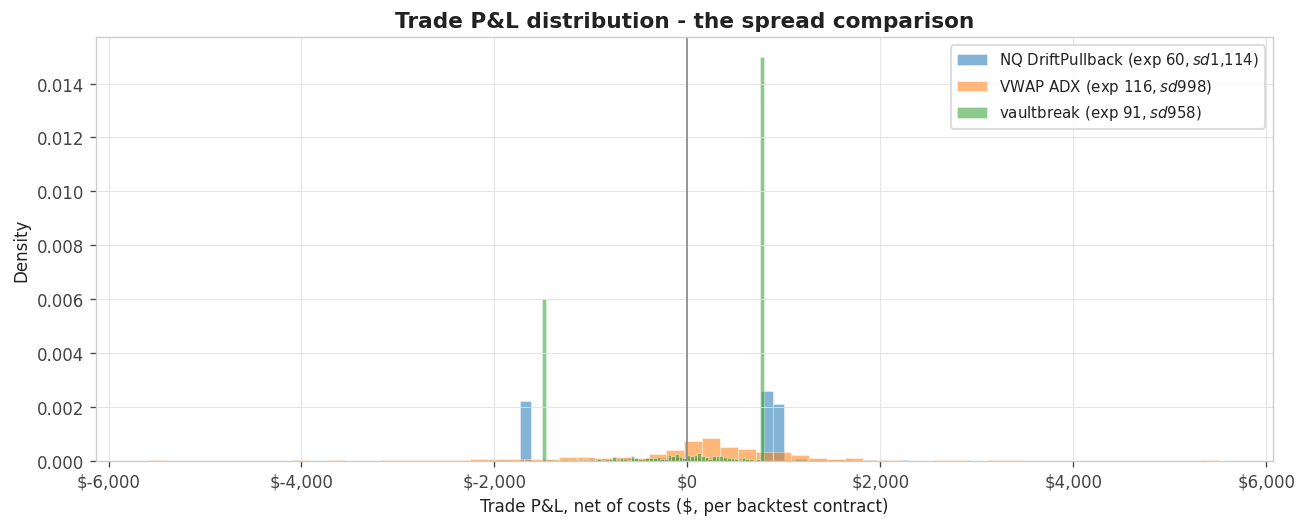

  NQ DriftPullback: worst trade $-3,877 | best $3,263 | skew -0.67  (negative skew: many small wins, occasional larger loss - higher pass odds, fatter left tail. A priced trade, not a free lunch.)
  VWAP ADX: worst trade $-5,577 | best $5,513 | skew -0.70  (negative skew: many small wins, occasional larger loss - higher pass odds, fatter left tail. A priced trade, not a free lunch.)
  vaultbreak: worst trade $-1,507 | best $793 | skew -0.88  (negative skew: many small wins, occasional larger loss - higher pass odds, fatter left tail. A priced trade, not a free lunch.)


In [ ]:
# =========================================================
# CELL 5 (M4.4): LOOK AT THE HISTOGRAM, NOT THE AVERAGE
# =========================================================
# The distribution IS the strategy. With 2+ strategies uploaded, the overlay
# sets up the spread lesson: at equal expectancy, wider spread = lower chance
# of touching the top barrier before the bottom one.

fig, ax = plt.subplots(figsize=(11, 4.5))
for s, g in df.groupby("strategy"):
    ax.hist(g["profit_net_usd"], bins=60, alpha=0.55, label=f"{s} "
            f"(exp ${g['profit_net_usd'].mean():,.0f}, sd ${g['profit_net_usd'].std():,.0f})",
            edgecolor="white", linewidth=0.4, density=len(STRATEGIES) > 1)
ax.axvline(0, color="#888888", linewidth=1)
ax.set_xlabel("Trade P&L, net of costs ($, per backtest contract)")
ax.set_ylabel("Density" if len(STRATEGIES) > 1 else "Count")
ax.set_title("Trade P&L distribution" + (" - the spread comparison" if len(STRATEGIES) > 1 else ""))
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout(); plt.show()

for s, g in df.groupby("strategy"):
    x = g["profit_net_usd"]
    print(f"  {s}: worst trade ${x.min():,.0f} | best ${x.max():,.0f} | "
          f"skew {x.skew():+.2f}"
          + ("  (negative skew: many small wins, occasional larger loss - "
             "higher pass odds, fatter left tail. A priced trade, not a free lunch.)"
             if x.skew() < -0.3 else ""))



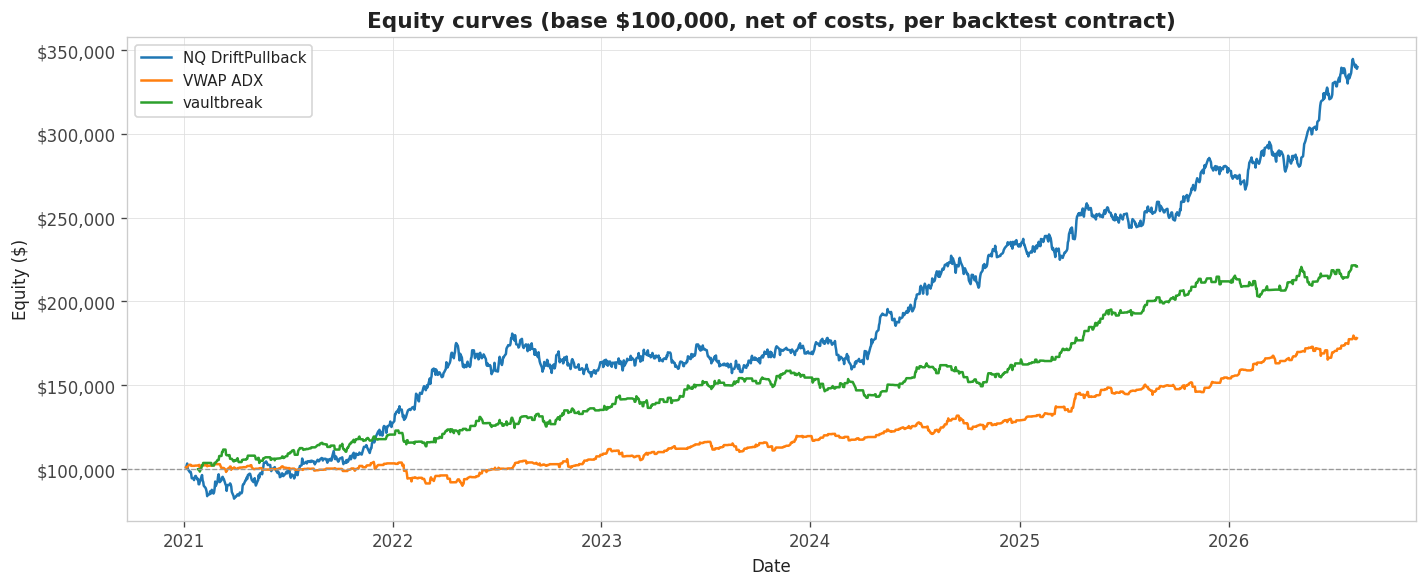

  NQ DriftPullback           total $   239,840   max DD $  25,660
  VWAP ADX                   total $    78,081   max DD $  14,232
  vaultbreak                 total $   120,834   max DD $  16,201
  The account you are about to rent has LESS room than that max DD in
  most cases - which is why the challenge is a sizing problem, not a
  profitability problem.


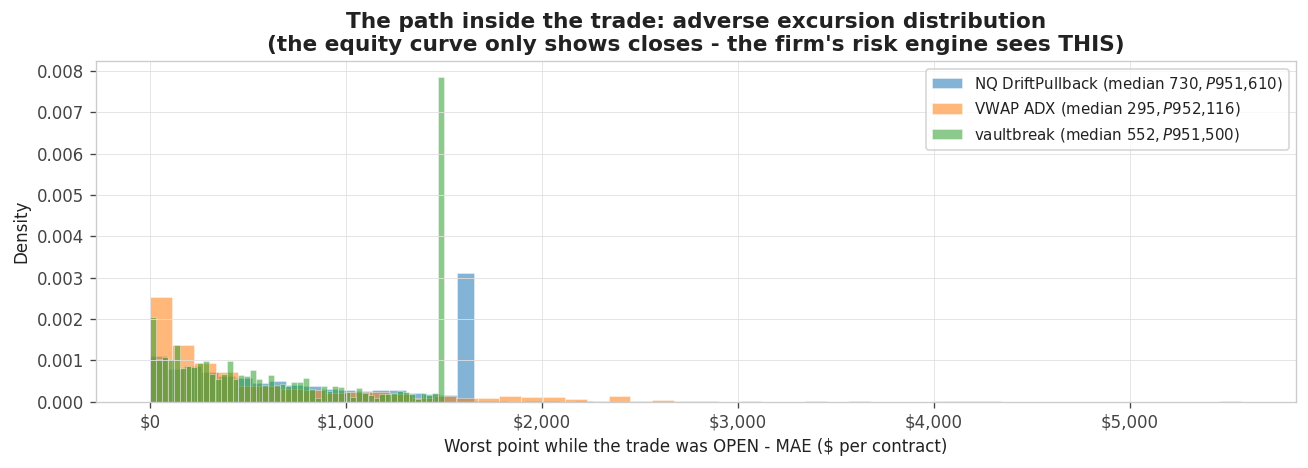

In [ ]:
# =========================================================
# CELL 5b (M4.5): EQUITY CURVES - THE MACHINE'S HISTORY AT A GLANCE
# =========================================================
# Cumulative net P&L on a $100,000 base, per backtest contract, on the
# weekday grid (flat stretches are honest flat lines, not gaps). With 2+
# strategies uploaded, all curves share one axis and the SAME unit, so
# shape and drawdown are directly comparable. The MAE band under the curve
# is the part of the history the equity line hides. (The MAE chart at the
# bottom is outline section 4.6 - the path INSIDE the trade.)

EQUITY_START = 100_000.0
fig, ax = plt.subplots(figsize=(12, 5))
_stats_rows = []
for s, g in df.groupby("strategy"):
    _grid = pd.date_range(g["date"].min(), g["date"].max(), freq="B")
    _eq = (g.groupby("date")["profit_net_usd"].sum()
           .reindex(_grid, fill_value=0.0).cumsum() + EQUITY_START)
    ax.plot(_grid, _eq, linewidth=1.5, label=s)
    _tot = _eq.iloc[-1] - EQUITY_START
    _mdd = float((_eq.cummax() - _eq).max())
    _stats_rows.append((s, _tot, _mdd))
ax.axhline(EQUITY_START, color="#999999", linewidth=0.8, linestyle="--")
ax.set_title(f"Equity curve{'s' if len(STRATEGIES) > 1 else ''} "
             f"(base ${EQUITY_START:,.0f}, net of costs, per backtest contract)")
ax.set_xlabel("Date"); ax.set_ylabel("Equity ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

for s, _tot, _mdd in _stats_rows:
    print(f"  {s:<26} total ${_tot:>10,.0f}   max DD ${_mdd:>8,.0f}")
print("  The account you are about to rent has LESS room than that max DD in")
print("  most cases - which is why the challenge is a sizing problem, not a")
print("  profitability problem.")

# the hidden half: what trades did WHILE OPEN (MAE), if measured
if HAS_EXCURSIONS:
    fig, ax = plt.subplots(figsize=(11, 4))
    for s, g in df.groupby("strategy"):
        ax.hist(g["mae_usd"], bins=50, alpha=0.55, density=len(STRATEGIES) > 1,
                edgecolor="white", linewidth=0.4,
                label=f"{s} (median ${g['mae_usd'].median():,.0f}, "
                      f"P95 ${g['mae_usd'].quantile(0.95):,.0f})")
    ax.set_xlabel("Worst point while the trade was OPEN - MAE ($ per contract)")
    ax.set_ylabel("Density" if len(STRATEGIES) > 1 else "Count")
    ax.set_title("The path inside the trade: adverse excursion distribution\n"
                 "(the equity curve only shows closes - the firm's risk engine sees THIS)")
    ax.legend()
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    plt.tight_layout(); plt.show()

In [ ]:
# =========================================================
# CELL 6 (M5.5): THE CONTROLLABLES - EVERY LEVER IN ONE PLACE
# =========================================================
# Cannot change today: your edge, the market.
# Can change today: everything below. This list is the entire optimisation
# surface; the sweeps in Cells 12-13 move these and nothing else.

SIM_STRATEGY        = STRATEGIES[0]   # which uploaded strategy to simulate
CONTRACTS_MNQ       = 10              # position size in MICRO contracts (10 = 1 NQ)
MAX_TRADES_PER_DAY  = None            # None = no cap; else an integer
STOP_AFTER_N_LOSSES = None            # stop the DAY after n losing trades; None = off
STOP_DAY_AFTER_UP   = None            # stop the DAY once day P&L >= this $; None = off

USE_EXCURSIONS = True                 # check the floor at each trade's MAE
                                      # (auto-off if the export lacks the columns)

N_SIMS      = 10_000                  # challenges per estimate
SWEEP_SIMS  = 4_000                   # per sweep point (faster)
HORIZON_DAYS = 250                    # safety guard when the account has no deadline

print(f"Levers set. Simulating '{SIM_STRATEGY}' on {ACCOUNT['name']} "
      f"at {CONTRACTS_MNQ} MNQ.")



Levers set. Simulating 'vaultbreak' on 50K EOD Trail at 10 MNQ.


In [ ]:
# =========================================================
# CELL 7 (M5.3): BUILD THE SIMULATOR - THE ENGINE
# =========================================================
# The bag-of-days mechanic from M5.2, in narratable pieces:
#   PIECE 1  the bag: your real trading days, each with its real trades in order
#   PIECE 2  the overlays: your daily rules (max trades, stop after n losses)
#   PIECE 3  one challenge: draw days, walk trades, floor / daily limit /
#            target / minimum days / deadline - until the account passes or dies
#   PIECE 4  many challenges: run it n times and COUNT. The count is p.
# Granularity note (honest, general): with Run-up/Drawdown columns in the
# export, the floor is checked at each trade's measured WORST point (MAE) as
# well as at its close - the firm's view of live equity. What remains unknown
# is the ORDER of the best and worst points inside one trade, so the MAE is
# applied before the close (pessimistic) and the target is only granted at
# closes (also pessimistic). Without excursion columns, checks fall back to
# closes only - optimistic at size, one more reason to prefer the smaller of
# two statistically tied sizes.

import numpy as np

# ── PIECE 1: the bag of days ─────────────────────────────────────────────
_g = df[df["strategy"] == SIM_STRATEGY].sort_values("datetime")
_scale = (CONTRACTS_MNQ / _BT_MNQ)          # backtest contract -> chosen MNQ size
_alldays = pd.date_range(_g["date"].min(), _g["date"].max(), freq="B")
DAY_BAG = []                                 # per-day (P&L array, MAE array)
_USE_MAE = bool(USE_EXCURSIONS and HAS_EXCURSIONS)
for _d in _alldays:
    _t = _g[_g["date"] == _d]
    DAY_BAG.append((_t["profit_net_usd"].to_numpy(),
                    _t["mae_usd"].to_numpy() if _USE_MAE
                    else _t["profit_net_usd"].clip(upper=0).abs().to_numpy()))
print(f"PIECE 1: bag holds {len(DAY_BAG)} real weekdays "
      f"({sum(len(p) > 0 for p, m in DAY_BAG)} with trades). Zero-trade days stay in -")
print("         they are real days and they cost deadline time.")

# ── PIECE 2: the overlays ────────────────────────────────────────────────
def apply_overlays(trades, maes, max_trades=None, stop_losses=None, stop_up=None):
    """Walk one day's trades in their real order and apply YOUR daily rules.
    Returns (trade P&L, trade MAE) pairs for the trades actually taken."""
    out, losses, day_pnl = [], 0, 0.0
    for t, m in zip(trades, maes):
        if max_trades is not None and len(out) >= max_trades: break
        if stop_losses is not None and losses >= stop_losses: break
        if stop_up is not None and day_pnl >= stop_up: break
        out.append((t, m)); day_pnl += t
        if t < 0: losses += 1
    return out

# ── PIECE 3: one simulated challenge ─────────────────────────────────────
def run_one_challenge(rng, contracts_mnq=None, verbose=False,
                      max_trades=None, stop_losses=None, stop_up=None,
                      win_haircut=0.0):
    a = ACCOUNT
    scale = (contracts_mnq if contracts_mnq is not None else CONTRACTS_MNQ) / _BT_MNQ
    bal = a["start_balance"]; hwm = bal
    floor = bal - a["max_drawdown"]
    lock_level = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
    trade_days = 0; peak_profit = 0.0; max_dd_seen = 0.0
    deadline = a["max_trading_days"] or HORIZON_DAYS

    for day in range(1, deadline + 1):
        raw, raw_mae = DAY_BAG[rng.integers(len(DAY_BAG))]
        if win_haircut > 0 and len(raw):                 # M4.5 haircut (Cell 15)
            raw = raw.copy(); raw_mae = raw_mae.copy()
            wins = np.where(raw > 0)[0]
            if len(wins):
                # each winning trade independently flips with prob = win_haircut
                flip = wins[rng.random(len(wins)) < win_haircut]
                losses = _g.loc[_g["profit_net_usd"] < 0, "profit_net_usd"].to_numpy()
                if len(losses) and len(flip):
                    raw[flip] = rng.choice(losses, size=len(flip))
                    raw_mae[flip] = np.abs(raw[flip])   # a loss's MAE >= the loss
        trades = apply_overlays(raw, raw_mae, max_trades, stop_losses, stop_up)
        if trades: trade_days += 1
        day_pnl = 0.0
        for t, t_mae in trades:
            t_usd = t * scale
            # the worst point INSIDE this trade, vs the CURRENT floor
            if _USE_MAE and (bal - t_mae * scale) <= floor:
                max_dd_seen = max(max_dd_seen, hwm - (bal - t_mae * scale))
                return _end("fail_dd", day, trade_days, peak_profit, max_dd_seen, verbose)
            bal += t_usd; day_pnl += t_usd
            peak_profit = max(peak_profit, bal - a["start_balance"])
            max_dd_seen = max(max_dd_seen, hwm - bal)
            # firm daily loss limit, checked at trade close (realised)
            if a["daily_loss_limit"] is not None and day_pnl <= -a["daily_loss_limit"]:
                if a["daily_loss_fatal"]:
                    return _end("fail_daily", day, trade_days, peak_profit, max_dd_seen, verbose)
                if verbose: print(f"    day {day}: daily loss limit hit, day over")
                break
            # the floor (M3.2)
            if a["dd_type"] == "intraday_trail":
                if bal > hwm: hwm = bal
                floor = hwm - a["max_drawdown"]
                if lock_level is not None: floor = min(floor, lock_level)
            if bal <= floor:
                return _end("fail_dd", day, trade_days, peak_profit, max_dd_seen, verbose)
            # target - with the minimum-days gate
            if (bal - a["start_balance"] >= a["profit_target"]
                    and trade_days >= a["min_trading_days"]):
                return _end("pass", day, trade_days, peak_profit, max_dd_seen, verbose)
        # end of day: EOD-trailing floor ratchets here
        if a["dd_type"] == "eod_trail":
            if bal > hwm: hwm = bal
            floor = hwm - a["max_drawdown"]
            if lock_level is not None: floor = min(floor, lock_level)
        if verbose:
            print(f"    day {day:>3}: {len(trades)} trades, day P&L ${day_pnl:>8,.0f}, "
                  f"balance ${bal:>9,.0f}, floor ${floor:>9,.0f}")
    return _end("fail_time", deadline, trade_days, peak_profit, max_dd_seen, verbose)

def _end(outcome, day, tdays, peak, mdd, verbose):
    if verbose: print(f"    → {outcome.upper()} on day {day}")
    return dict(outcome=outcome, days=day, trade_days=tdays,
                was_in_profit=peak > 0, max_dd=mdd)

# ── PIECE 4: many challenges = a probability ─────────────────────────────
def run_many(n_sims, rng, **kw):
    res = [run_one_challenge(rng, **kw) for _ in range(n_sims)]
    out = {k: sum(r["outcome"] == k for r in res) / n_sims
           for k in ("pass", "fail_dd", "fail_daily", "fail_time")}
    out["died_after_profit"] = (sum(1 for r in res if r["outcome"] != "pass" and r["was_in_profit"])
                                / max(1, sum(1 for r in res if r["outcome"] != "pass"))
                                if any(r["outcome"] != "pass" for r in res) else 0.0)
    _dp = [r["days"] for r in res if r["outcome"] == "pass"]
    out["med_days_to_pass"] = float(np.median(_dp)) if _dp else float("nan")
    out["p90_days_to_pass"] = float(np.percentile(_dp, 90)) if _dp else float("nan")
    out["days_pass_arr"] = np.array(_dp)
    out["max_dds"] = np.array([r["max_dd"] for r in res])
    out["day_pnls"] = None
    out["n"] = n_sims
    return out

def wilson_ci(p, n, z=1.96):
    d = 1 + z*z/n; c = (p + z*z/(2*n)) / d
    m = (z/d) * np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return max(0.0, c-m), min(1.0, c+m)

print("PIECE 2-4: overlays, one-challenge walk, and the counter are loaded.")
print("➡️  CELL 8 runs ONE challenge slowly; CELL 9 runs them all.")


PIECE 1: bag holds 1448 real weekdays (635 with trades). Zero-trade days stay in -
         they are real days and they cost deadline time.
PIECE 2-4: overlays, one-challenge walk, and the counter are loaded.
➡️  CELL 8 runs ONE challenge slowly; CELL 9 runs them all.


One simulated challenge - vaultbreak at 10 MNQ on 50K EOD Trail:

    day   1: 0 trades, day P&L $       0, balance $   50,000, floor $   48,000
    day   2: 0 trades, day P&L $       0, balance $   50,000, floor $   48,000
    day   3: 0 trades, day P&L $       0, balance $   50,000, floor $   48,000
    day   4: 2 trades, day P&L $     946, balance $   50,946, floor $   48,000
    day   5: 1 trades, day P&L $     793, balance $   51,738, floor $   48,946
    day   6: 0 trades, day P&L $       0, balance $   51,738, floor $   49,738
    day   7: 0 trades, day P&L $       0, balance $   51,738, floor $   49,738
    day   8: 0 trades, day P&L $       0, balance $   51,738, floor $   49,738
    day   9: 0 trades, day P&L $       0, balance $   51,738, floor $   49,738
    day  10: 0 trades, day P&L $       0, balance $   51,738, floor $   49,738
    day  11: 2 trades, day P&L $     650, balance $   52,389, floor $   49,738
    day  12: 3 trades, day P&L $     793, balance $   53,182, flo

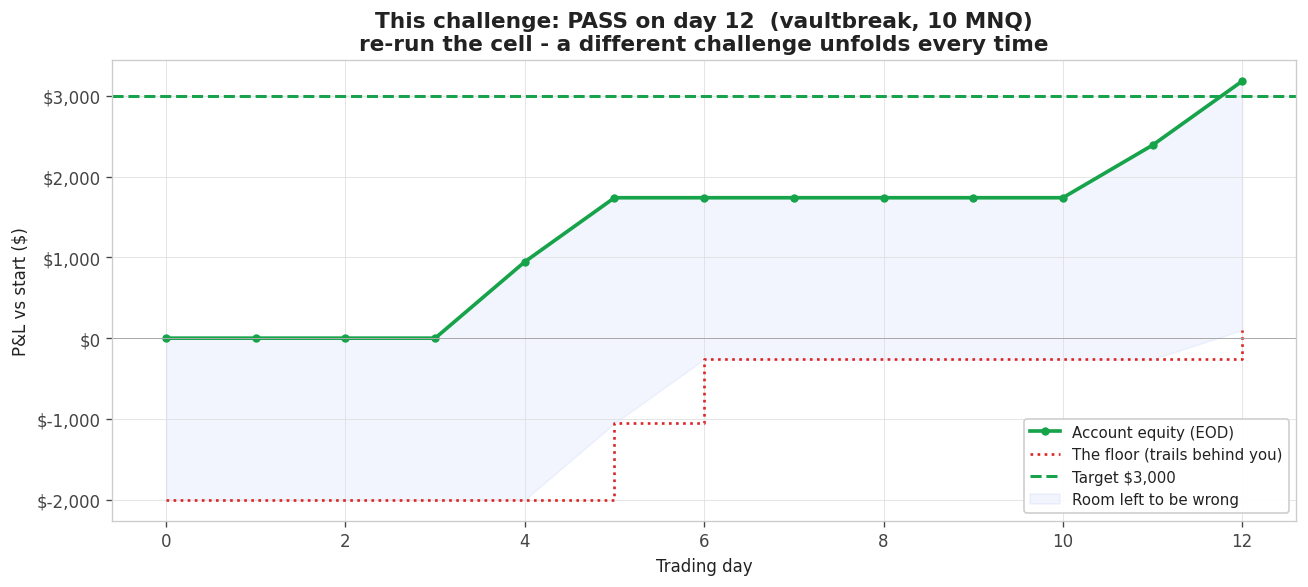


That was ONE of the ten thousand. Its outcome (pass) means
nothing by itself - the COUNT across all of them is the number that matters.
Re-run this cell a few times and watch different fates come out of the
SAME strategy - that spread of fates is exactly what Cell 9 measures.


In [ ]:
# =========================================================
# CELL 8 (M5.2): RUN ONE SIMULATED CHALLENGE, SLOWLY
# =========================================================
# The on-camera moment: one draw-by-draw challenge, every day printed AND
# charted, so the audience sees there is no model and no forecast - just the
# bag. DELIBERATELY UNSEEDED: re-run the cell and a different challenge
# unfolds every time (everything else in the notebook stays seeded and
# reproducible - one attempt is a story, ten thousand are a probability).

rng_demo = np.random.default_rng()          # fresh randomness on every run
print(f"One simulated challenge - {SIM_STRATEGY} at {CONTRACTS_MNQ} MNQ "
      f"on {ACCOUNT['name']}:\n")

# walk one challenge, recording the equity path day by day
_a = ACCOUNT
_scale8 = CONTRACTS_MNQ / _BT_MNQ
_deadline8 = _a["max_trading_days"] or HORIZON_DAYS
_bal = _a["start_balance"]; _hwm = _bal
_floor = _bal - _a["max_drawdown"]
_lock = (_bal + _a["dd_lock_at_profit"]) if _a["dd_lock_at_profit"] is not None else None
_td = 0
_eq_path, _fl_path = [0.0], [_floor - _a["start_balance"]]
_outcome, _end_day = None, _deadline8

for _day in range(1, _deadline8 + 1):
    _p_, _m_ = DAY_BAG[rng_demo.integers(len(DAY_BAG))]
    _trades = apply_overlays(_p_, _m_, MAX_TRADES_PER_DAY,
                             STOP_AFTER_N_LOSSES, STOP_DAY_AFTER_UP)
    if _trades:
        _td += 1
    _day_pnl = 0.0
    for _t, _m in _trades:
        if _USE_MAE and (_bal - _m * _scale8) <= _floor:
            _outcome = "fail_dd (inside a trade)"
            break
        _bal += _t * _scale8; _day_pnl += _t * _scale8
        if _a["dd_type"] == "intraday_trail":
            _hwm = max(_hwm, _bal); _floor = _hwm - _a["max_drawdown"]
            if _lock is not None: _floor = min(_floor, _lock)
        if _bal <= _floor:
            _outcome = "fail_dd"
            break
        if (_bal - _a["start_balance"] >= _a["profit_target"]
                and _td >= _a["min_trading_days"]):
            _outcome = "pass"
            break
    print(f"    day {_day:>3}: {len(_trades)} trades, day P&L ${_day_pnl:>8,.0f}, "
          f"balance ${_bal:>9,.0f}, floor ${_floor:>9,.0f}")
    _eq_path.append(_bal - _a["start_balance"])
    _fl_path.append(_floor - _a["start_balance"])
    if _outcome:
        _end_day = _day
        break
    if _a["dd_type"] == "eod_trail":
        _hwm = max(_hwm, _bal); _floor = _hwm - _a["max_drawdown"]
        if _lock is not None: _floor = min(_floor, _lock)
_outcome = _outcome or "fail_time"
print(f"    → {_outcome.upper()} on day {_end_day}")

# ── the chart of THIS challenge ──────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
_x8 = range(len(_eq_path))
ax.plot(_x8, _eq_path, linewidth=2.2,
        color=("#16a34a" if _outcome == "pass"
               else "#dc2626" if _outcome.startswith("fail_dd") else "#9ca3af"),
        marker="o", markersize=4, label="Account equity (EOD)")
ax.plot(_x8, _fl_path, linewidth=1.6, color="#dc2626", linestyle=":",
        drawstyle="steps-post", label="The floor (trails behind you)")
ax.axhline(_a["profit_target"], color="#16a34a", linestyle="--", linewidth=1.8,
           label=f"Target ${_a['profit_target']:,.0f}")
ax.axhline(0, color="#aaaaaa", linewidth=0.6)
ax.fill_between(_x8, _fl_path, _eq_path, alpha=0.06,
                color="#2563eb", label="Room left to be wrong")
ax.set_xlabel("Trading day")
ax.set_ylabel("P&L vs start ($)")
ax.set_title(f"This challenge: {_outcome.upper()} on day {_end_day}  "
             f"({SIM_STRATEGY}, {CONTRACTS_MNQ} MNQ)\n"
             f"re-run the cell - a different challenge unfolds every time")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="best", framealpha=0.95)
plt.tight_layout(); plt.show()

print(f"\nThat was ONE of the ten thousand. Its outcome ({_outcome}) means")
print("nothing by itself - the COUNT across all of them is the number that matters.")
print("Re-run this cell a few times and watch different fates come out of the")
print("SAME strategy - that spread of fates is exactly what Cell 9 measures.")

══════════════════════════════════════════════════════════════════
  vaultbreak | 50K EOD Trail | 10 MNQ | 10,000 challenges
══════════════════════════════════════════════════════════════════

  >>> p, single-attempt pass probability: 40.1%  [39.1% - 41.0%] <<<

  Outcome                         Share   Challenges
  ──────────────────────────────────────────────────
  Passed                          40.1%        4,006
  Failed: drawdown floor          58.1%        5,809
  Failed: ran out of time          1.8%          185

  Median days to pass : 7   (P90: 14)
  Median max drawdown : $2,152   (P95: $3,007 vs room $2,000)


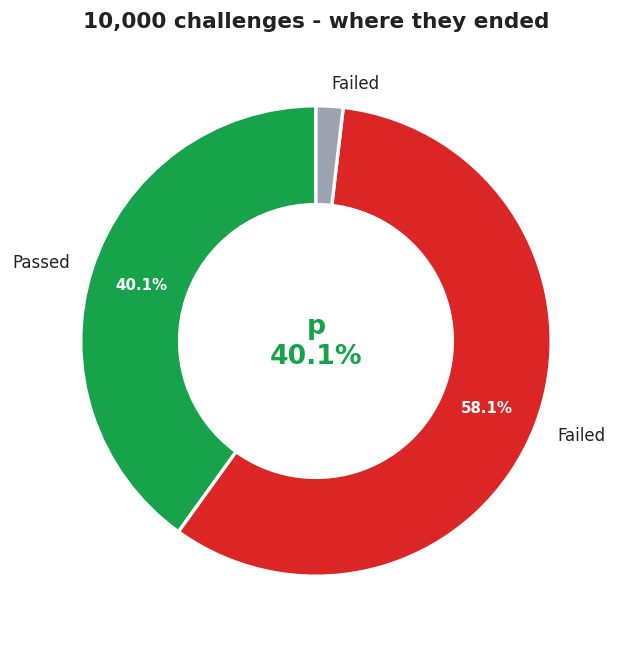

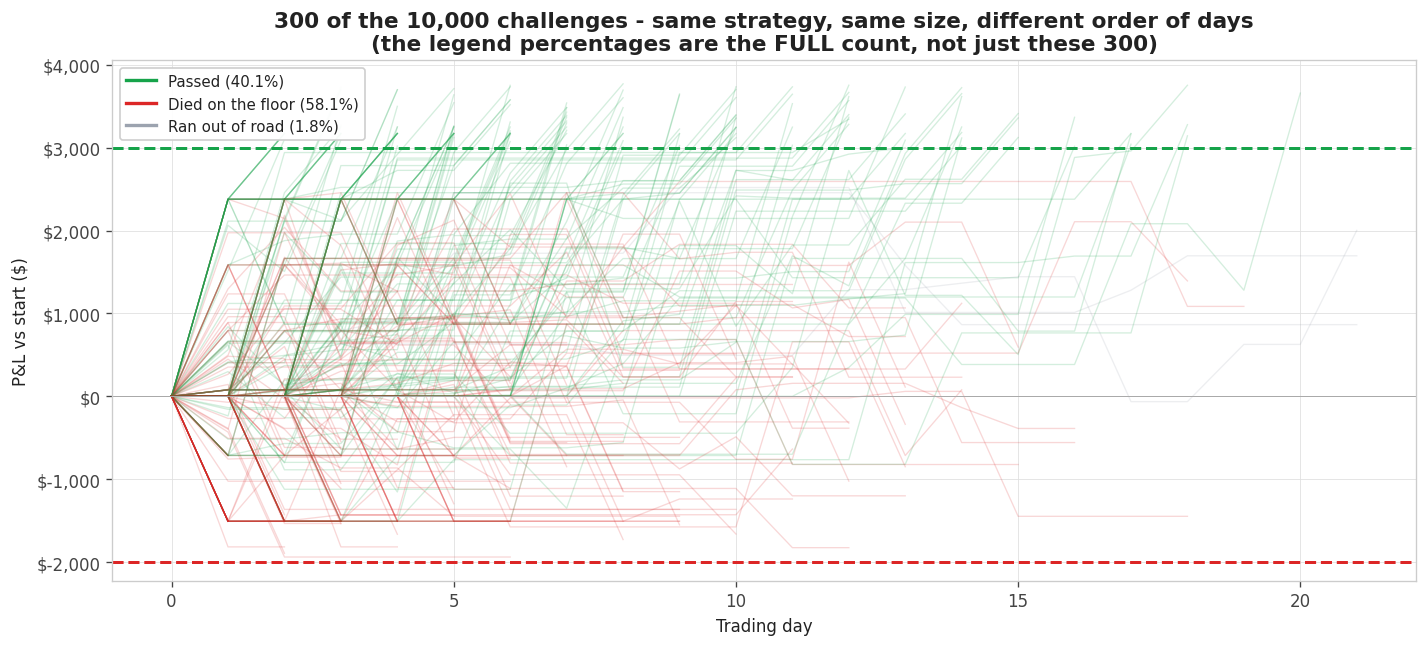


  This p is the price tag on the evaluation you were about to buy blind.
  The colored segments are Cell 10's subject: WHY the failures failed
  decides WHICH lever to pull - and the fixes point in opposite directions.


In [ ]:
# =========================================================
# CELL 9 (M5.3): RUN TEN THOUSAND - p, ITS COMPANIONS, AND THE TANGLE
# =========================================================
# The count, its confidence interval, the picture of where all ten thousand
# challenges ended - and a 300-path sample of them drawn as lives. One
# attempt was a story; this is the price. (Replaces the separate spaghetti
# cell: your backtest was ONE line through this tangle - the tangle is what
# it was hiding.)

rng = np.random.default_rng(SEED + 1)
R = run_many(N_SIMS, rng, max_trades=MAX_TRADES_PER_DAY,
             stop_losses=STOP_AFTER_N_LOSSES, stop_up=STOP_DAY_AFTER_UP)
ci = wilson_ci(R["pass"], N_SIMS)

print("═" * 66)
print(f"  {SIM_STRATEGY} | {ACCOUNT['name']} | {CONTRACTS_MNQ} MNQ | {N_SIMS:,} challenges")
print("═" * 66)
print(f"\n  >>> p, single-attempt pass probability: {R['pass']:.1%}  "
      f"[{ci[0]:.1%} - {ci[1]:.1%}] <<<\n")
print(f"  {'Outcome':<28} {'Share':>8} {'Challenges':>12}")
print("  " + "─" * 50)
_out_rows = [("Passed", R["pass"], "#16a34a"),
             ("Failed: drawdown floor", R["fail_dd"], "#dc2626"),
             ("Failed: daily loss limit", R["fail_daily"], "#d97706"),
             ("Failed: ran out of time", R["fail_time"], "#9ca3af")]
for _lbl, _v, _c in _out_rows:
    if _v > 0:
        print(f"  {_lbl:<28} {_v:>8.1%} {int(round(_v * N_SIMS)):>12,}")
print(f"\n  Median days to pass : {R['med_days_to_pass']:.0f}"
      f"   (P90: {R['p90_days_to_pass']:.0f})")
print(f"  Median max drawdown : ${np.median(R['max_dds']):,.0f}"
      f"   (P95: ${np.percentile(R['max_dds'], 95):,.0f} vs room "
      f"${ACCOUNT['max_drawdown']:,.0f})")

# ── picture 1: where ten thousand challenges ended ───────
_nz = [(l, v, c) for l, v, c in _out_rows if v > 0]
_ls, _vs, _cs = zip(*_nz)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(_vs, labels=[l.split(":")[0] for l in _ls], colors=_cs, startangle=90,
       wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
       autopct=lambda pct: f"{pct:.1f}%" if pct >= 4 else "",
       pctdistance=0.78, textprops={"fontsize": 10, "color": "#222222"})
for _t in ax.texts:
    if "%" in _t.get_text():
        _t.set_color("white"); _t.set_fontweight("bold"); _t.set_fontsize(9)
ax.text(0, 0, f"p\n{R['pass']:.1%}", ha="center", va="center",
        fontsize=16, fontweight="bold", color="#16a34a")
ax.set_title(f"{N_SIMS:,} challenges - where they ended", pad=12)
plt.tight_layout(); plt.show()
# ── picture 2: the spaghetti - a sample of those challenges as lives ─────
N_SPAGHETTI = 300
_deadline9 = ACCOUNT["max_trading_days"] or HORIZON_DAYS

def _one_path(rng):
    a = ACCOUNT
    scale = CONTRACTS_MNQ / _BT_MNQ
    bal = a["start_balance"]; hwm = bal
    floor = bal - a["max_drawdown"]
    lock = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
    td = 0; ys = [0.0]; out = None
    for day in range(_deadline9):
        _p_, _m_ = DAY_BAG[rng.integers(len(DAY_BAG))]
        for t, m in apply_overlays(_p_, _m_, MAX_TRADES_PER_DAY,
                                   STOP_AFTER_N_LOSSES, STOP_DAY_AFTER_UP):
            if _USE_MAE and (bal - m * scale) <= floor:
                out = "fail_dd"; break
            bal += t * scale
            if a["dd_type"] == "intraday_trail":
                hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                if lock is not None: floor = min(floor, lock)
            if bal <= floor:
                out = "fail_dd"; break
            if (bal - a["start_balance"] >= a["profit_target"]
                    and td + 1 >= a["min_trading_days"]):
                out = "pass"; break
        if len(_p_):
            td += 1
        ys.append(bal - a["start_balance"])
        if out:
            break
        if a["dd_type"] == "eod_trail":
            hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
            if lock is not None: floor = min(floor, lock)
    return ys, out or "fail_time"

rng_sp = np.random.default_rng(SEED + 2)
fig, ax = plt.subplots(figsize=(12, 5.5))
for _ in range(N_SPAGHETTI):
    ys, out = _one_path(rng_sp)
    c = ("#16a34a" if out == "pass"
         else "#dc2626" if out == "fail_dd" else "#9ca3af")
    ax.plot(range(len(ys)), ys, color=c, alpha=0.18, linewidth=0.8)
ax.axhline(ACCOUNT["profit_target"], color="#16a34a", ls="--", lw=1.8)
ax.axhline(-ACCOUNT["max_drawdown"], color="#dc2626", ls="--", lw=1.8)
ax.axhline(0, color="#aaaaaa", lw=0.6)
from matplotlib.lines import Line2D as _L2D
ax.legend(handles=[
    _L2D([0], [0], color="#16a34a", lw=2, label=f"Passed ({R['pass']:.1%})"),
    _L2D([0], [0], color="#dc2626", lw=2,
         label=f"Died on the floor ({R['fail_dd'] + R['fail_daily']:.1%})"),
    _L2D([0], [0], color="#9ca3af", lw=2, label=f"Ran out of road ({R['fail_time']:.1%})"),
], loc="upper left", framealpha=0.95)
ax.set_xlabel("Trading day"); ax.set_ylabel("P&L vs start ($)")
ax.set_title(f"{N_SPAGHETTI} of the {N_SIMS:,} challenges - same strategy, same size, "
             f"different order of days\n(the legend percentages are the FULL count, "
             f"not just these {N_SPAGHETTI})")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout(); plt.show()

print(f"\n  This p is the price tag on the evaluation you were about to buy blind.")
print(f"  The colored segments are Cell 10's subject: WHY the failures failed")
print(f"  decides WHICH lever to pull - and the fixes point in opposite directions.")

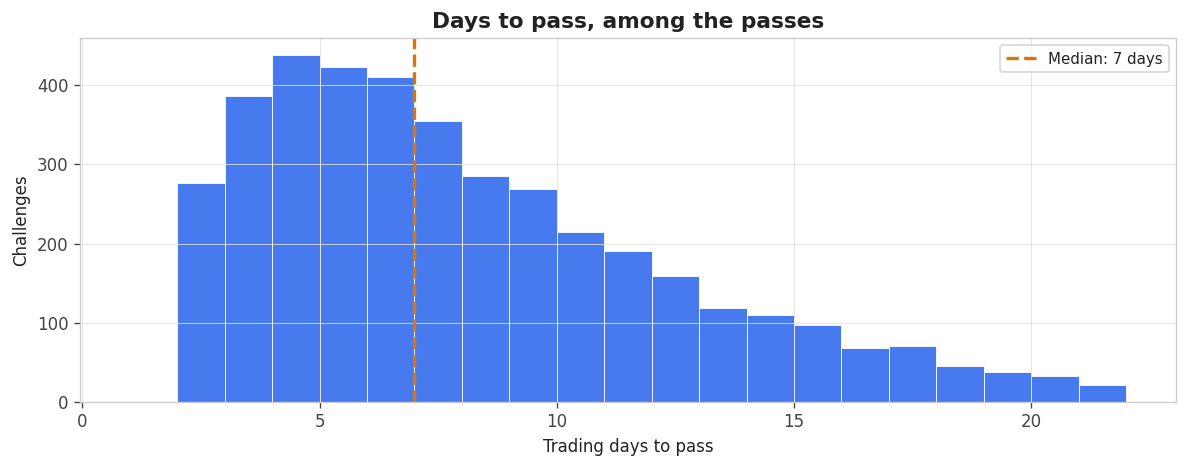

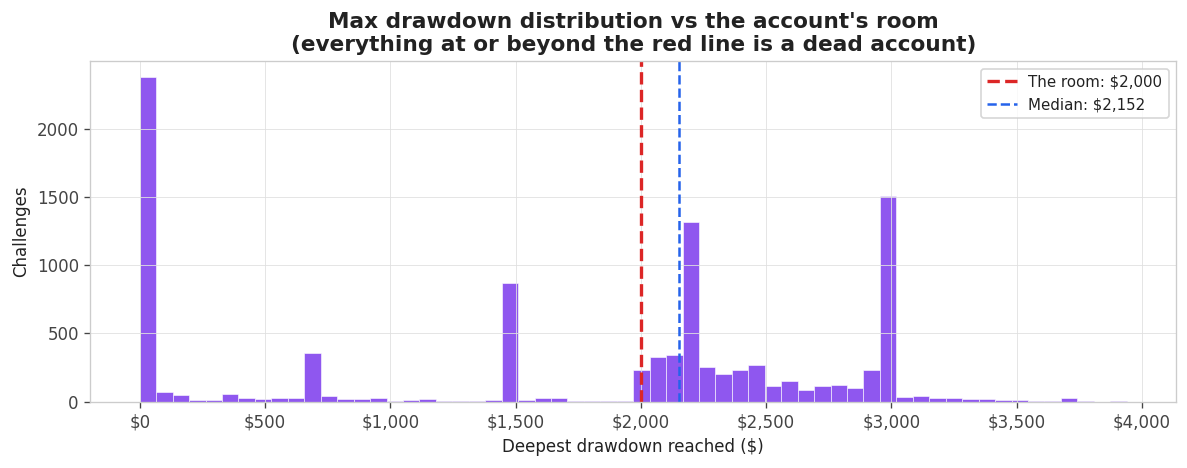

In [ ]:
# =========================================================
# CELL 9b (M5.3): WHAT PASSING AND FAILING LOOK LIKE
# =========================================================
# Two pictures behind the single number p: how long the passes take (plan
# your calendar and your patience), and how deep the accounts dig relative
# to the room (why the floor, not the target, is the boss).

_deadline = ACCOUNT["max_trading_days"] or HORIZON_DAYS
if len(R["days_pass_arr"]) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(R["days_pass_arr"], bins=range(1, min(_deadline, 60) + 2),
            color="#2563eb", edgecolor="white", linewidth=0.6, alpha=0.85)
    _med = np.median(R["days_pass_arr"])
    ax.axvline(_med, color="#d97706", linestyle="--", linewidth=2,
               label=f"Median: {_med:.0f} days")
    ax.set_xlabel("Trading days to pass"); ax.set_ylabel("Challenges")
    ax.set_title("Days to pass, among the passes")
    ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(R["max_dds"], bins=60, color="#7c3aed", edgecolor="white",
        linewidth=0.4, alpha=0.85)
ax.axvline(ACCOUNT["max_drawdown"], color="#dc2626", linestyle="--", linewidth=2,
           label=f"The room: ${ACCOUNT['max_drawdown']:,.0f}")
ax.axvline(float(np.median(R["max_dds"])), color="#2563eb", linestyle="--",
           linewidth=1.5, label=f"Median: ${np.median(R['max_dds']):,.0f}")
ax.set_xlabel("Deepest drawdown reached ($)"); ax.set_ylabel("Challenges")
ax.set_title("Max drawdown distribution vs the account's room\n"
             "(everything at or beyond the red line is a dead account)")
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout(); plt.show()


In [ ]:
# =========================================================
# CELL 10 (M5.4): THE FAILURE MODE TABLE - THE REAL OUTPUT
# =========================================================
# Most people stop at p. Each row of this table points at a DIFFERENT fix,
# and two of the fixes are opposites - which is why p alone cannot guide you.

_rows = [
    ("Failed on the drawdown floor",  R["fail_dd"],
     "a SIZING problem - fewer contracts, or a daily stop"),
    ("Failed on the daily loss limit", R["fail_daily"],
     "a SIZING / clustering problem - smaller size or stop-after-n-losses"),
    ("Never reached the target",       R["fail_time"],
     "a FREQUENCY problem - MORE size or more trades, the OPPOSITE fix"),
]
print("═" * 74)
print(f"  WHY THE FAILURES FAILED  ({(1 - R['pass']):.1%} of {N_SIMS:,} challenges)")
print("═" * 74)
for lbl, v, fix in _rows:
    if v > 0:
        print(f"  {lbl:<32} {v:>7.1%}   → {fix}")
print(f"  {'Died AFTER having been in profit':<32} {R['died_after_profit']:>7.1%}"
      f"   (share of all failures - the trailing floor's signature)")
print("\n  Read the biggest row first. Fix that one. Re-run. That loop IS Step 3.")


══════════════════════════════════════════════════════════════════════════
  WHY THE FAILURES FAILED  (59.9% of 10,000 challenges)
══════════════════════════════════════════════════════════════════════════
  Failed on the drawdown floor       58.1%   → a SIZING problem - fewer contracts, or a daily stop
  Never reached the target            1.8%   → a FREQUENCY problem - MORE size or more trades, the OPPOSITE fix
  Died AFTER having been in profit   66.3%   (share of all failures - the trailing floor's signature)

  Read the biggest row first. Fix that one. Re-run. That loop IS Step 3.


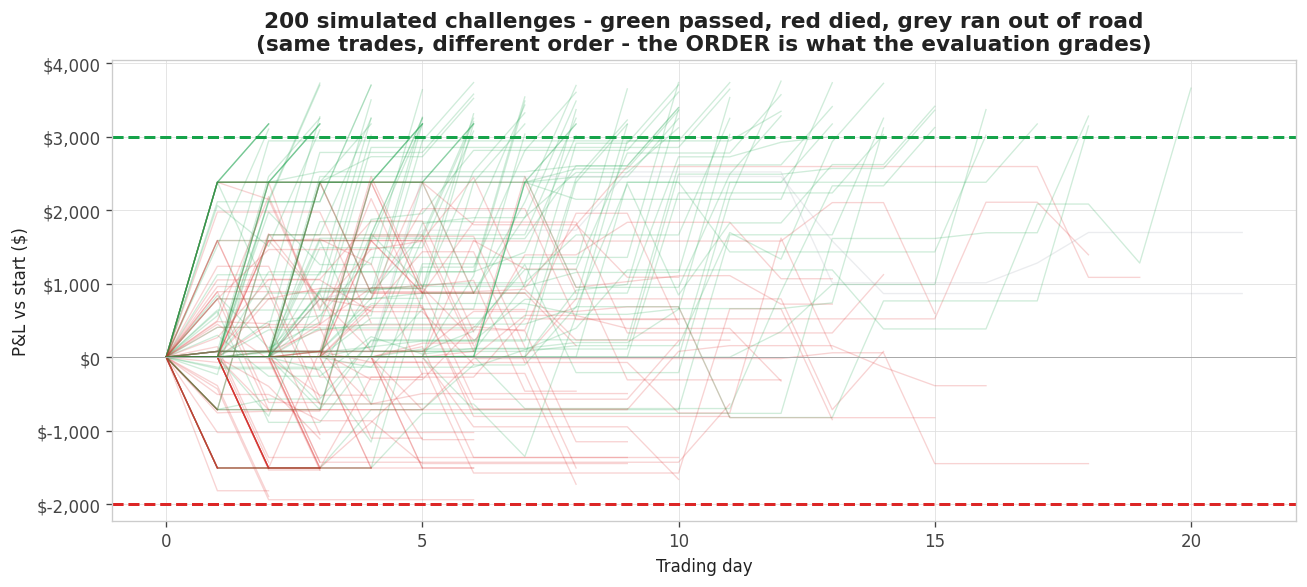

In [ ]:
# =========================================================
# CELL 11 (M5.1): SPAGHETTI - AN EDGE SURVIVES SHUFFLING
# =========================================================
# Your backtest is ONE sequence in the one order history dealt. Bootstrapped
# challenge paths show the distribution that one sequence was hiding.

N_PATHS = 200
rng_s = np.random.default_rng(SEED + 2)
fig, ax = plt.subplots(figsize=(11, 5))
_deadline = ACCOUNT["max_trading_days"] or HORIZON_DAYS
_shown = 0
for _ in range(N_PATHS):
    bal = ACCOUNT["start_balance"]; hwm = bal
    floor = bal - ACCOUNT["max_drawdown"]
    lock = (bal + ACCOUNT["dd_lock_at_profit"]) if ACCOUNT["dd_lock_at_profit"] is not None else None
    ys = [0.0]; dead = passed = False
    for day in range(_deadline):
        _p_, _m_ = DAY_BAG[rng_s.integers(len(DAY_BAG))]
        for t, m in apply_overlays(_p_, _m_,
                                MAX_TRADES_PER_DAY, STOP_AFTER_N_LOSSES, STOP_DAY_AFTER_UP):
            if _USE_MAE and (bal - m * (CONTRACTS_MNQ / _BT_MNQ)) <= floor:
                dead = True; break
            bal += t * (CONTRACTS_MNQ / _BT_MNQ)
            if ACCOUNT["dd_type"] == "intraday_trail":
                hwm = max(hwm, bal); floor = hwm - ACCOUNT["max_drawdown"]
                if lock is not None: floor = min(floor, lock)
            if bal <= floor: dead = True; break
            if bal - ACCOUNT["start_balance"] >= ACCOUNT["profit_target"]: passed = True; break
        ys.append(bal - ACCOUNT["start_balance"])
        if dead or passed: break
        if ACCOUNT["dd_type"] == "eod_trail":
            hwm = max(hwm, bal); floor = hwm - ACCOUNT["max_drawdown"]
            if lock is not None: floor = min(floor, lock)
    c = "#16a34a" if passed else ("#dc2626" if dead else "#9ca3af")
    ax.plot(range(len(ys)), ys, color=c, alpha=0.20, linewidth=0.8)
    _shown += 1
ax.axhline(ACCOUNT["profit_target"], color="#16a34a", ls="--", lw=1.8)
ax.axhline(-ACCOUNT["max_drawdown"], color="#dc2626", ls="--", lw=1.8)
ax.axhline(0, color="#aaaaaa", lw=0.6)
ax.set_xlabel("Trading day"); ax.set_ylabel("P&L vs start ($)")
ax.set_title(f"{_shown} simulated challenges - green passed, red died, grey ran out of road\n"
             f"(same trades, different order - the ORDER is what the evaluation grades)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout(); plt.show()



    MNQ        p            95% CI  MedDays  P95 maxDD
  ──────────────────────────────────────────────────────
     1     0.0%  [ 0.0% -  0.1%]      nan       $766
     2     0.4%  [ 0.3% -  0.7%]       19     $1,515
     3     4.9%  [ 4.2% -  5.6%]       17     $2,139
     4    15.4%  [14.4% - 16.6%]       16     $2,377
     5    24.6%  [23.2% - 25.9%]       14     $2,575
     6    31.2%  [29.8% - 32.7%]       12     $2,709
     8    39.0%  [37.5% - 40.5%]        9     $2,977
    10    40.3%  [38.8% - 41.9%]        7     $3,007
    12    39.0%  [37.5% - 40.5%]        6     $3,609
    15    41.4%  [39.9% - 43.0%]        4     $3,322
    20    45.4%  [43.8% - 46.9%]        2     $3,514
    25    41.1%  [39.6% - 42.7%]        2     $4,100
    30    36.5%  [35.0% - 38.0%]        2     $4,500


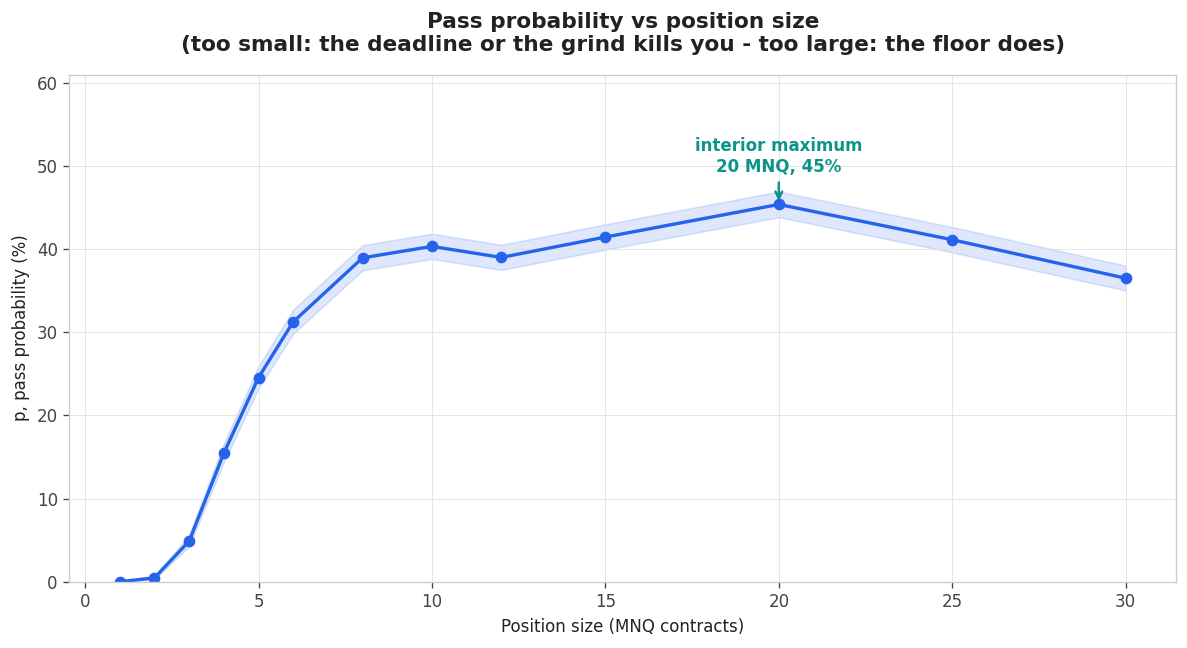


  Peak: 20 MNQ at 45.4%, statistically tied across 20-20 MNQ.
  Inside a tie, take the SMALLER size: same measured odds, less drawdown,
  and the trade-close granularity note from Cell 7 always favours smaller.


In [ ]:
# =========================================================
# CELL 12 (M5.6): SWEEP CONTRACT SIZE - THE INTERIOR MAXIMUM
# =========================================================
# The most quotable chart in the class: too small never reaches the target,
# too large touches the floor. Somewhere in between is YOUR maximum.

SIZE_GRID_MNQ = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]
SIZE_GRID_MNQ = [s for s in SIZE_GRID_MNQ if s <= ACCOUNT["max_contracts_mnq"]]

sweep = []
print(f"  {'MNQ':>5} {'p':>8} {'95% CI':>17} {'MedDays':>8} {'P95 maxDD':>10}")
print("  " + "─" * 54)
for s in SIZE_GRID_MNQ:
    r = run_many(SWEEP_SIMS, np.random.default_rng(SEED + 100), contracts_mnq=s,
                 max_trades=MAX_TRADES_PER_DAY, stop_losses=STOP_AFTER_N_LOSSES,
                 stop_up=STOP_DAY_AFTER_UP)
    lo, hi = wilson_ci(r["pass"], SWEEP_SIMS)
    print(f"  {s:>4} {r['pass']:>8.1%}  [{lo:>5.1%} - {hi:>5.1%}] {r['med_days_to_pass']:>8.0f} "
          f"{'$' + format(np.percentile(r['max_dds'], 95), ',.0f'):>10}")
    sweep.append(dict(mnq=s, p=r["pass"], lo=lo, hi=hi, r=r))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot([d["mnq"] for d in sweep], [d["p"] * 100 for d in sweep], "-o",
        color="#2563eb", linewidth=2)
ax.fill_between([d["mnq"] for d in sweep], [d["lo"] * 100 for d in sweep],
                [d["hi"] * 100 for d in sweep], alpha=0.15, color="#2563eb")

_pk = max(sweep, key=lambda d: d["p"])
_top = max(d["hi"] for d in sweep) * 100          # highest point incl. CI band
ax.set_ylim(0, _top * 1.30)                        # guaranteed headroom
ax.annotate(f"interior maximum\n{_pk['mnq']} MNQ, {_pk['p']:.0%}",
            xy=(_pk["mnq"], _pk["p"] * 100),
            xytext=(_pk["mnq"], _top * 1.14),      # label lives IN the headroom
            ha="center", va="top",
            fontweight="bold", color="#0d9488",
            arrowprops=dict(arrowstyle="->", color="#0d9488", lw=1.5))
ax.set_xlabel("Position size (MNQ contracts)"); ax.set_ylabel("p, pass probability (%)")
ax.set_title("Pass probability vs position size\n"
             "(too small: the deadline or the grind kills you - too large: the floor does)",
             pad=14)
plt.tight_layout(); plt.show()

# statistically-tied zone (the lesson from every sweep: don't rank noise)
_tied = [d for d in sweep if d["hi"] >= _pk["lo"]]
_zone = (min(_tied, key=lambda d: d["mnq"])["mnq"], max(_tied, key=lambda d: d["mnq"])["mnq"])
print(f"\n  Peak: {_pk['mnq']} MNQ at {_pk['p']:.1%}, statistically tied across "
      f"{_zone[0]}-{_zone[1]} MNQ.")
print(f"  Inside a tie, take the SMALLER size: same measured odds, less drawdown,")
print(f"  and the trade-close granularity note from Cell 7 always favours smaller.")

════════════════════════════════════════════════════════════════════════
  BUFFER TEST - small until +$1,000 profit, then 20 MNQ  (dynamic mode, 4,000 sims each)
════════════════════════════════════════════════════════════════════════
                Plan        p            95% CI   vs flat
  ──────────────────────────────────────────────────────────
         flat 20 MNQ    44.7%   [43.2% - 46.2%]  baseline
            5→20 MNQ    31.1%   [29.6% - 32.5%]     -13.7pp
           10→20 MNQ    41.8%   [40.3% - 43.3%]      -2.9pp
           15→20 MNQ    39.4%   [37.9% - 40.9%]      -5.3pp


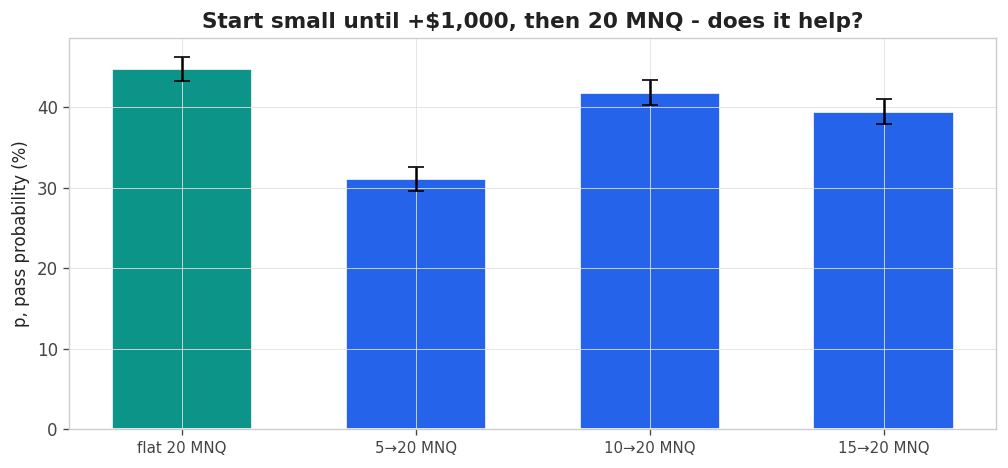


  >>> Statistically TIED (41.8% staged vs 44.7% flat). The buffer idea neither helps nor hurts the
      EVAL - so take the simpler flat plan: one fewer rule to
      execute is itself a risk reduction. <<<

  Whichever way YOUR data lands: this took a simulation, not an
  opinion - and the same idea on a funded account (no deadline, death
  costs the whole ladder) can come out the other way. That trade-off
  returns in Cell 23.


In [ ]:
# =========================================================
# CELL 12b (M5.6): THE BUFFER IDEA - START SMALL, THEN GO OPTIMAL?
# =========================================================
# The most common sizing plan traders invent for themselves: trade a reduced
# size until the account has built a profit buffer, then switch to the
# optimal size. Intuition says it protects the dangerous early days (no
# cushion, floor right behind you). The deadline says it wastes the scarcest
# resource. Both are right - which one wins is an empirical question, and
# the same engine answers it. Same seeds for every variant, so differences
# are real, not luck.
#
# STAGED_MODE: "dynamic" = size follows equity (drops back below the buffer)
#              "ratchet" = once the buffer is reached, stay at optimal size

BUFFER_LEVEL  = 1_000.0
STAGE1_FRACS  = [0.25, 0.50, 0.75]     # stage-1 size as a fraction of optimal
STAGED_MODE   = "dynamic"
STAGED_SIMS   = SWEEP_SIMS

# test the buffer idea against the sweep's optimal size (the peak of Cell 12)
TARGET_MNQ = min(d["mnq"] for d in sweep if d["hi"] >= _pk["lo"])

def run_staged(nc_small, nc_big, n_sims, rng, mode="dynamic"):
    a = ACCOUNT
    deadline = a["max_trading_days"] or HORIZON_DAYS
    passed = 0
    for _ in range(n_sims):
        bal = a["start_balance"]; hwm = bal
        floor = bal - a["max_drawdown"]
        lock = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
        td = 0; big = False; out = None
        for day in range(deadline):
            _p_, _m_ = DAY_BAG[rng.integers(len(DAY_BAG))]
            trades = apply_overlays(_p_, _m_, MAX_TRADES_PER_DAY,
                                    STOP_AFTER_N_LOSSES, STOP_DAY_AFTER_UP)
            if trades:
                td += 1
            day_pnl = 0.0
            for t, m in trades:
                if mode == "ratchet":
                    big = big or (bal - a["start_balance"] >= BUFFER_LEVEL)
                else:
                    big = bal - a["start_balance"] >= BUFFER_LEVEL
                scale = (nc_big if big else nc_small) / _BT_MNQ
                if _USE_MAE and (bal - m * scale) <= floor:
                    out = "dead"; break
                bal += t * scale; day_pnl += t * scale
                if (a["daily_loss_limit"] is not None
                        and day_pnl <= -a["daily_loss_limit"]):
                    if a["daily_loss_fatal"]:
                        out = "dead"
                    break
                if a["dd_type"] == "intraday_trail":
                    hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                    if lock is not None: floor = min(floor, lock)
                if bal <= floor:
                    out = "dead"; break
                if (bal - a["start_balance"] >= a["profit_target"]
                        and td >= a["min_trading_days"]):
                    out = "pass"; break
            if out:
                break
            if a["dd_type"] == "eod_trail":
                hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                if lock is not None: floor = min(floor, lock)
        passed += out == "pass"
    return passed / n_sims

_stage1_sizes = sorted({max(1, int(round(fr * TARGET_MNQ))) for fr in STAGE1_FRACS}
                       - {TARGET_MNQ})

_p_flat = run_staged(TARGET_MNQ, TARGET_MNQ, STAGED_SIMS,
                     np.random.default_rng(SEED + 700), STAGED_MODE)
_lo_f, _hi_f = wilson_ci(_p_flat, STAGED_SIMS)

print("═" * 72)
print(f"  BUFFER TEST - small until +${BUFFER_LEVEL:,.0f} profit, "
      f"then {TARGET_MNQ} MNQ  ({STAGED_MODE} mode, {STAGED_SIMS:,} sims each)")
print("═" * 72)

if not _stage1_sizes:
    print(f"  The optimal size is already {TARGET_MNQ} MNQ - there is no smaller")
    print(f"  whole-contract size to stage from. The buffer question does not")
    print(f"  arise for this configuration.")
else:
    print(f"  {'Plan':>18} {'p':>8} {'95% CI':>17} {'vs flat':>9}")
    print("  " + "─" * 58)
    print(f"  {'flat ' + str(TARGET_MNQ) + ' MNQ':>18} {_p_flat:>8.1%}   "
          f"[{_lo_f:>5.1%} - {_hi_f:>5.1%}]  baseline")
    _rows12b = [(f"flat {TARGET_MNQ} MNQ", _p_flat, _lo_f, _hi_f)]
    for nc1 in _stage1_sizes:
        p = run_staged(nc1, TARGET_MNQ, STAGED_SIMS,
                       np.random.default_rng(SEED + 700), STAGED_MODE)
        lo, hi = wilson_ci(p, STAGED_SIMS)
        _rows12b.append((f"{nc1}→{TARGET_MNQ} MNQ", p, lo, hi))
        print(f"  {str(nc1) + '→' + str(TARGET_MNQ) + ' MNQ':>18} {p:>8.1%}   "
              f"[{lo:>5.1%} - {hi:>5.1%}]  {(p - _p_flat) * 100:>+8.1f}pp")

    # ── small visual: the plans side by side, CI whiskers ────
    fig, ax = plt.subplots(figsize=(8.5, 4))
    _ps12 = [r[1] * 100 for r in _rows12b]
    _errs = [[r[1] * 100 - r[2] * 100 for r in _rows12b],
             [r[3] * 100 - r[1] * 100 for r in _rows12b]]
    _cols12 = ["#0d9488"] + ["#2563eb"] * (len(_rows12b) - 1)
    ax.bar(range(len(_rows12b)), _ps12, yerr=_errs, capsize=5,
           color=_cols12, edgecolor="white", width=0.6)
    ax.set_xticks(range(len(_rows12b)))
    ax.set_xticklabels([r[0] for r in _rows12b], fontsize=9)
    ax.set_ylabel("p, pass probability (%)")
    ax.set_title(f"Start small until +${BUFFER_LEVEL:,.0f}, then {TARGET_MNQ} MNQ - "
                 f"does it help?")
    plt.tight_layout(); plt.show()

    # ── computed, gated verdict ──────────────────────────────
    _staged = _rows12b[1:]
    _best_st = max(_staged, key=lambda r: r[1])
    if _best_st[2] > _hi_f:
        print(f"\n  >>> Staging HELPS here: {_best_st[0]} beats flat sizing outside")
        print(f"      the CIs ({_best_st[1]:.1%} vs {_p_flat:.1%}). The early")
        print(f"      protection is worth more than the time it spends. <<<")
    elif _best_st[3] < _lo_f:
        print(f"\n  >>> Staging HURTS here: every staged plan is worse than flat")
        print(f"      sizing, outside the CIs. Under a deadline, days spent trading")
        print(f"      small buy little progress - the clock kills more accounts")
        print(f"      than the early floor would have. <<<")
    else:
        print(f"\n  >>> Statistically TIED ({_best_st[1]:.1%} staged vs "
              f"{_p_flat:.1%} flat). The buffer idea neither helps nor hurts the")
        print(f"      EVAL - so take the simpler flat plan: one fewer rule to")
        print(f"      execute is itself a risk reduction. <<<")
    print(f"\n  Whichever way YOUR data lands: this took a simulation, not an")
    print(f"  opinion - and the same idea on a funded account (no deadline, death")
    print(f"  costs the whole ladder) can come out the other way. That trade-off")
    print(f"  returns in Cell 23.")

════════════════════════════════════════════════════════════════════════════════════
  ACCOUNT SHOWDOWN - vaultbreak, same trades, every account (2,000 sims per size)
════════════════════════════════════════════════════════════════════════════════════
  Account                       Fee  Size*        p  E[attempts]  E[cost to pass]
  ────────────────────────────────────────────────────────────────────────────────
  25K EOD Trail                $147      5    40.0%          2.5             $368
  50K EOD Trail                $167     10    40.2%          2.5             $416
  100K EOD Trail               $207     15    31.4%          3.2             $658
  150K EOD Trail               $297     20    27.4%          3.7           $1,086

  (ACCOUNT restored to your selection: 50K EOD Trail. Size* is each
  account's own smallest statistically tied size; E[cost] = fee / p.)


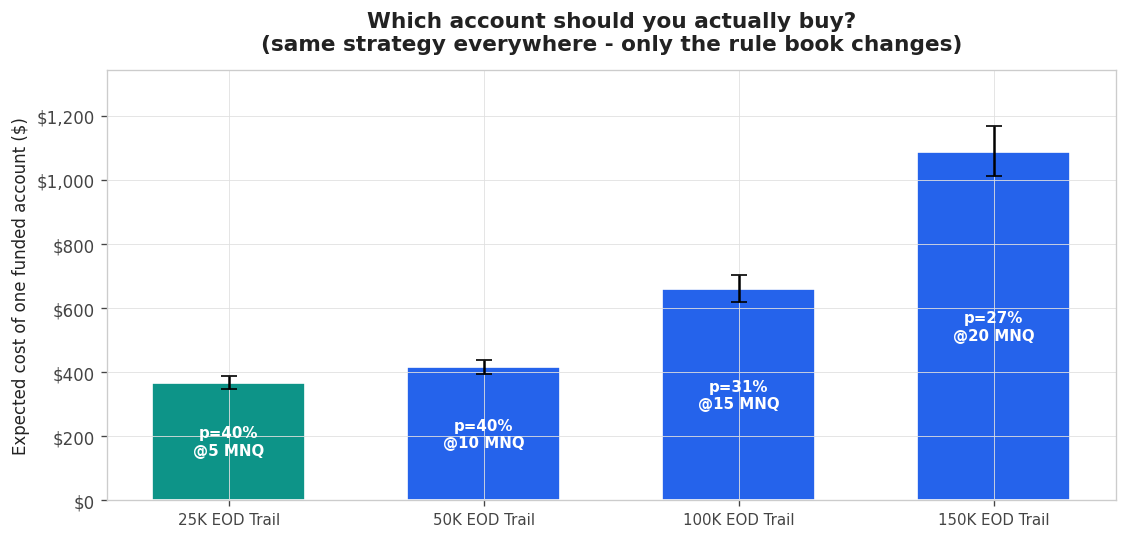


  >>> 25K EOD Trail is the cheapest path to a funded account for THIS
      strategy: E[cost] $368 vs $416 for the
      runner-up, outside the intervals. Note it is not automatically the
      account with the highest p - fee and odds trade off. <<<

  Caveats, so this stays honest: every preset must be VERIFIED against the
  firm's current page; resets and monthly rebills are not modeled (E[cost]
  assumes one fee per attempt); and the same daily rules were applied to
  every account - re-run Cells 13-14 per account before a final decision.


In [ ]:
# =========================================================
# CELL 12c (M3.5): WHICH ACCOUNT SHOULD YOU ACTUALLY BUY - THE SHOWDOWN
# =========================================================
# Module 3 built the spec sheets and compared DIFFICULTY on paper. This cell
# settles it empirically: the SAME strategy, swept across EVERY account in
# the spec sheet, each account at its own recommended size. The decision
# number is not p alone - it is the expected COST of one funded account:
# fee x expected attempts (fee / p). Cheapest sticker is often not the
# cheapest pass.
# (Lives here because it needs the engine from Cell 7; on the slides this
# is Module 3.5. The selected ACCOUNT_KEY is restored afterwards.)

SHOWDOWN_SIMS = 2_000

_saved_account = ACCOUNT
_show_rows = []
print("═" * 84)
print(f"  ACCOUNT SHOWDOWN - {SIM_STRATEGY}, same trades, every account "
      f"({SHOWDOWN_SIMS:,} sims per size)")
print("═" * 84)
print(f"  {'Account':<26} {'Fee':>6} {'Size*':>6} {'p':>8} "
      f"{'E[attempts]':>12} {'E[cost to pass]':>16}")
print("  " + "─" * 80)
for _k, _spec in ACCOUNT_PRESETS.items():
    ACCOUNT = _spec
    _asw = []
    for sz in SIZE_GRID_MNQ:
        if sz > ACCOUNT["max_contracts_mnq"]:
            continue
        r = run_many(SHOWDOWN_SIMS, np.random.default_rng(SEED + 950),
                     contracts_mnq=sz, max_trades=MAX_TRADES_PER_DAY,
                     stop_losses=STOP_AFTER_N_LOSSES, stop_up=STOP_DAY_AFTER_UP)
        lo, hi = wilson_ci(r["pass"], SHOWDOWN_SIMS)
        _asw.append(dict(mnq=sz, p=r["pass"], lo=lo, hi=hi))
    _pk_a = max(_asw, key=lambda d: d["p"])
    _tied_a = [d for d in _asw if d["hi"] >= _pk_a["lo"]]
    _rec_a = min(_tied_a, key=lambda d: d["mnq"])
    _fee_a = _spec.get("fee", 0.0) or 0.0
    _att = (1.0 / _rec_a["p"]) if _rec_a["p"] > 0 else float("inf")
    _cost = _fee_a * _att
    _cost_lo = _fee_a / _rec_a["hi"] if _rec_a["hi"] > 0 else float("inf")
    _cost_hi = _fee_a / _rec_a["lo"] if _rec_a["lo"] > 0 else float("inf")
    print(f"  {_spec['name']:<26} {'$' + format(_fee_a, ',.0f'):>6} "
          f"{_rec_a['mnq']:>6} {_rec_a['p']:>8.1%} {_att:>12.1f} "
          f"{'$' + format(_cost, ',.0f'):>16}")
    _show_rows.append(dict(key=_k, name=_spec["name"], fee=_fee_a,
                           mnq=_rec_a["mnq"], p=_rec_a["p"],
                           lo=_rec_a["lo"], hi=_rec_a["hi"],
                           cost=_cost, cost_lo=_cost_lo, cost_hi=_cost_hi))
ACCOUNT = _saved_account
print(f"\n  (ACCOUNT restored to your selection: {ACCOUNT['name']}. Size* is each")
print(f"  account's own smallest statistically tied size; E[cost] = fee / p.)")

# ── the decision chart: expected cost of ONE funded account ──────────────
fig, ax = plt.subplots(figsize=(9.5, 4.6))
_names_s = [r["name"] for r in _show_rows]
_costs = [r["cost"] for r in _show_rows]
_errs = [[max(0.0, r["cost"] - r["cost_lo"]) for r in _show_rows],
         [max(0.0, r["cost_hi"] - r["cost"]) for r in _show_rows]]
_best_c = min(_show_rows, key=lambda r: r["cost"])
_cols_s = ["#0d9488" if r is _best_c else "#2563eb" for r in _show_rows]
ax.bar(range(len(_show_rows)), _costs, yerr=_errs, capsize=5,
       color=_cols_s, edgecolor="white", width=0.6)
for i, r in enumerate(_show_rows):
    ax.text(i, r["cost"] * 0.5, f"p={r['p']:.0%}\n@{r['mnq']} MNQ",
            ha="center", va="center", fontsize=9, fontweight="bold",
            color="white")
ax.set_xticks(range(len(_show_rows)))
ax.set_xticklabels(_names_s, fontsize=9)
ax.set_ylabel("Expected cost of one funded account ($)")
_topc = max(r["cost_hi"] for r in _show_rows if np.isfinite(r["cost_hi"]))
ax.set_ylim(0, _topc * 1.15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_title("Which account should you actually buy?\n"
             "(same strategy everywhere - only the rule book changes)", pad=12)
plt.tight_layout(); plt.show()

# ── computed, gated verdict ──────────────────────────────
_rankc = sorted(_show_rows, key=lambda r: r["cost"])
_c1, _c2 = _rankc[0], _rankc[1]
if _c1["cost_hi"] < _c2["cost_lo"]:
    print(f"\n  >>> {_c1['name']} is the cheapest path to a funded account for THIS")
    print(f"      strategy: E[cost] ${_c1['cost']:,.0f} vs ${_c2['cost']:,.0f} for the")
    print(f"      runner-up, outside the intervals. Note it is not automatically the")
    print(f"      account with the highest p - fee and odds trade off. <<<")
else:
    print(f"\n  >>> {_c1['name']} (${_c1['cost']:,.0f}) and {_c2['name']} "
          f"(${_c2['cost']:,.0f}) are statistically")
    print(f"      TIED on expected cost. Break the tie on what E[cost] cannot see:")
    print(f"      the funded phase you inherit (drawdown type and room AFTER passing),")
    print(f"      activation and monthly fees, and payout rules - Module 8 territory. <<<")
print(f"\n  Caveats, so this stays honest: every preset must be VERIFIED against the")
print(f"  firm's current page; resets and monthly rebills are not modeled (E[cost]")
print(f"  assumes one fee per attempt); and the same daily rules were applied to")
print(f"  every account - re-run Cells 13-14 per account before a final decision.")

════════════════════════════════════════════════════════════════════════════════
  THE BARRIER PROBLEM, PURE - model trader on 50K EOD Trail, 3 trades/day
  every RR gets the same advantage: win rate 10% above its breakeven
════════════════════════════════════════════════════════════════════════════════
     RR     WR   Risk*        p   95% CI
  ──────────────────────────────────────────────
   0.25    88%    $700    75.6%   [73.7% - 77.5%]
   0.50    73%    $500    61.8%   [59.6% - 63.9%]
   0.75    63%    $400    53.4%   [51.2% - 55.6%]
   1.00    55%    $400    49.0%   [46.8% - 51.2%]
   1.50    44%    $250    40.5%   [38.4% - 42.7%]
   2.00    37%    $250    42.0%   [39.9% - 44.2%]
   3.00    28%    $200    38.2%   [36.1% - 40.4%]
   4.00    22%    $200    38.0%   [35.9% - 40.1%]


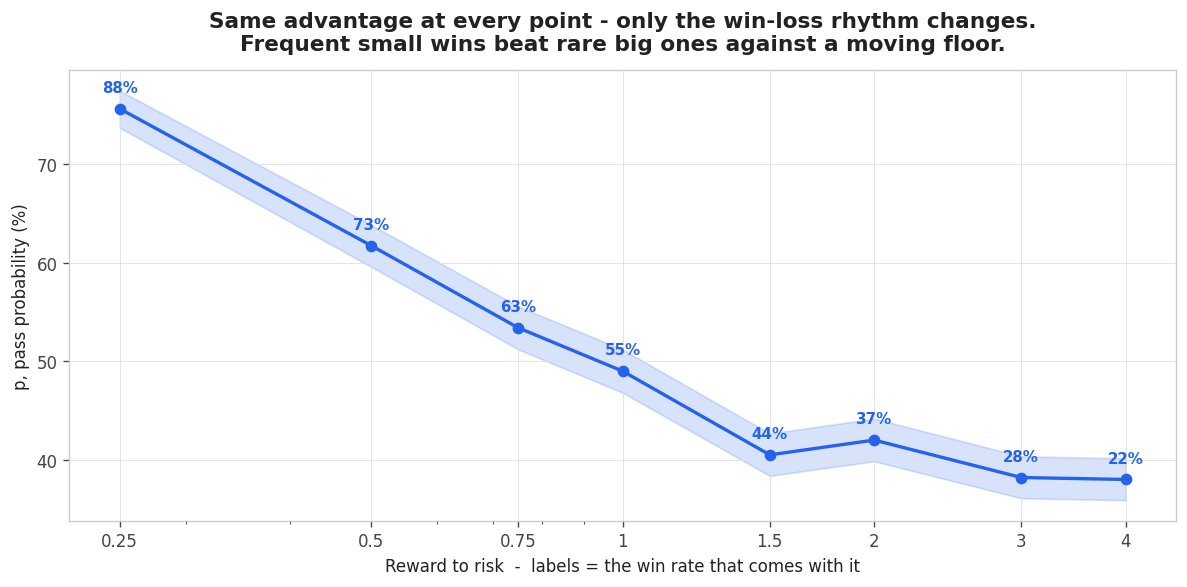


  >>> Same advantage, different destiny: RR 0.25 (88% win rate) passes at 75.6%,
      RR 4 (22% win rate) at 38.0%, outside the CIs. <<<
  Why: the high win rate machine takes many small steps, so its losing
  streaks are short and shallow, and the trailing floor never catches
  it. The low win rate machine spends most of its life in droughts
  between big wins, and the floor collects it during the droughts,
  even though both machines earn the same per trade on average. A
  challenge rewards frequent wins, and frequent wins are usually the
  gift of a LOWER reward to risk ratio.


In [ ]:
# =========================================================
# CELL 12d (M2.4): ENGINEER THE SHAPE - THE BARRIER PROBLEM, PURE
# =========================================================
# No uploaded trades, on purpose: a model trader who risks a fixed amount
# per trade (RR 1 = risk $1,000 to make $1,000). Every RR on the grid gets
# the SAME small advantage: a win rate 10% above breakeven for that RR
# (breakeven = 1/(1+RR)). So RR 0.25 wins 88% of trades, RR 1 wins 55%,
# RR 4 wins 22%, and all of them make the same money per trade on average.
# Same advantage, different rhythm. If the rhythm did not matter, the
# curve below would be flat. Each RR is swept over risk-per-trade sizes
# and gets its own tied-zone recommendation, so the comparison is fair.

RR_GRID_T  = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0]
EDGE_MULT  = 1.10            # win rate = breakeven x this (1.10 = 10% above)
TRADES_DAY = 3
RISK_GRID  = [100, 150, 200, 250, 300, 400, 500, 700]   # $ risk per trade
SHAPE_SIMS = 2_000

def _run_pure(rr, risk, n_sims, rng):
    a = ACCOUNT
    wr = EDGE_MULT / (1.0 + rr)
    if wr >= 0.97:
        return None                      # this RR cannot carry the advantage
    tgt = rr * risk
    deadline = a["max_trading_days"] or HORIZON_DAYS
    passed = 0
    for _ in range(n_sims):
        bal = a["start_balance"]; hwm = bal
        floor = bal - a["max_drawdown"]
        lock = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
        td = 0; outc = None
        for day in range(deadline):
            td += 1
            day_pnl = 0.0
            for j_ in range(TRADES_DAY):
                win = rng.random() < wr
                dip = risk if not win else rng.random() * risk
                if _USE_MAE and (bal - dip) <= floor:
                    outc = "dd"; break
                pnl = tgt if win else -risk
                bal += pnl; day_pnl += pnl
                if (a["daily_loss_limit"] is not None
                        and day_pnl <= -a["daily_loss_limit"]):
                    if a["daily_loss_fatal"]:
                        outc = "dd"
                    break
                if a["dd_type"] == "intraday_trail":
                    hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                    if lock is not None: floor = min(floor, lock)
                if bal <= floor:
                    outc = "dd"; break
                if (bal - a["start_balance"] >= a["profit_target"]
                        and td >= a["min_trading_days"]):
                    outc = "pass"; break
            if outc:
                break
            if a["dd_type"] == "eod_trail":
                hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                if lock is not None: floor = min(floor, lock)
        passed += outc == "pass"
    return passed / n_sims

print("═" * 80)
print(f"  THE BARRIER PROBLEM, PURE - model trader on {ACCOUNT['name']}, "
      f"{TRADES_DAY} trades/day")
print(f"  every RR gets the same advantage: win rate 10% above its breakeven")
print("═" * 80)
print(f"  {'RR':>5} {'WR':>6} {'Risk*':>7} {'p':>8}   95% CI")
print("  " + "─" * 46)
_rows_p = []
for rr in RR_GRID_T:
    sw = []
    for rk in RISK_GRID:
        p_ = _run_pure(rr, rk, SHAPE_SIMS, np.random.default_rng(SEED + 985))
        if p_ is None:
            continue
        lo, hi = wilson_ci(p_, SHAPE_SIMS)
        sw.append(dict(risk=rk, p=p_, lo=lo, hi=hi))
    if not sw:
        print(f"  {rr:>5.2f}  win rate would exceed 97% - skipped")
        continue
    pk = max(sw, key=lambda d_: d_["p"])
    rec = min([d_ for d_ in sw if d_["hi"] >= pk["lo"]],
              key=lambda d_: d_["risk"])
    wr = EDGE_MULT / (1.0 + rr)
    print(f"  {rr:>5.2f} {wr:>6.0%} {'$' + format(rec['risk'], ',d'):>7} "
          f"{rec['p']:>8.1%}   [{rec['lo']:.1%} - {rec['hi']:.1%}]")
    _rows_p.append(dict(rr=rr, wr=wr, rec=rec))

fig, ax = plt.subplots(figsize=(10, 5))
_xs = [r["rr"] for r in _rows_p]
ax.plot(_xs, [r["rec"]["p"] * 100 for r in _rows_p], "-o",
        color="#2563eb", linewidth=2)
ax.fill_between(_xs, [r["rec"]["lo"] * 100 for r in _rows_p],
                [r["rec"]["hi"] * 100 for r in _rows_p],
                alpha=0.18, color="#2563eb")
for r in _rows_p:
    ax.annotate(f"{r['wr']:.0%}", (r["rr"], r["rec"]["p"] * 100),
                textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold", color="#2563eb")
ax.set_xscale("log")
ax.set_xticks(_xs)
ax.set_xticklabels([f"{x:g}" for x in _xs])
ax.set_xlabel("Reward to risk  -  labels = the win rate that comes with it")
ax.set_ylabel("p, pass probability (%)")
ax.set_title("Same advantage at every point - only the win-loss rhythm changes.\n"
             "Frequent small wins beat rare big ones against a moving floor.",
             pad=12)
plt.tight_layout(); plt.show()

if len(_rows_p) >= 2:
    _lo_rr = _rows_p[0]; _hi_rr = _rows_p[-1]
    if _lo_rr["rec"]["lo"] > _hi_rr["rec"]["hi"]:
        print(f"\n  >>> Same advantage, different destiny: RR {_lo_rr['rr']:g} "
              f"({_lo_rr['wr']:.0%} win rate) passes at {_lo_rr['rec']['p']:.1%},")
        print(f"      RR {_hi_rr['rr']:g} ({_hi_rr['wr']:.0%} win rate) at "
              f"{_hi_rr['rec']['p']:.1%}, outside the CIs. <<<")
    else:
        print(f"\n  >>> The curve is flatter than the CIs on this account - "
              f"read the tied ranges. <<<")
print(f"  Why: the high win rate machine takes many small steps, so its losing")
print(f"  streaks are short and shallow, and the trailing floor never catches")
print(f"  it. The low win rate machine spends most of its life in droughts")
print(f"  between big wins, and the floor collects it during the droughts,")
print(f"  even though both machines earn the same per trade on average. A")
print(f"  challenge rewards frequent wins, and frequent wins are usually the")
print(f"  gift of a LOWER reward to risk ratio.")

In [ ]:
# =========================================================
# CELL 13 (M5.6): SWEEP THE DAILY RULES
# =========================================================
# Two one-dimensional sweeps at the peak-zone size: the daily stop after n
# losses, and the max-trades-per-day cap. Watch BOTH columns - what a rule
# buys in p and what it costs in time to pass.

RULE_SWEEP_SIZE = _pk["mnq"]          # from Cell 12; override manually if desired

print(f"  At {RULE_SWEEP_SIZE} MNQ - STOP AFTER N LOSSES:")
print(f"  {'n':>6} {'p':>8} {'MedDays':>8}")
for n_ in [None, 1, 2, 3, 4]:
    r = run_many(SWEEP_SIMS, np.random.default_rng(SEED + 200),
                 contracts_mnq=RULE_SWEEP_SIZE, max_trades=MAX_TRADES_PER_DAY,
                 stop_losses=n_, stop_up=STOP_DAY_AFTER_UP)
    print(f"  {str(n_) if n_ else 'off':>6} {r['pass']:>8.1%} {r['med_days_to_pass']:>8.0f}")

print(f"\n  At {RULE_SWEEP_SIZE} MNQ - MAX TRADES PER DAY:")
print(f"  {'cap':>6} {'p':>8} {'MedDays':>8}")
for m_ in [None, 2, 3, 4, 6]:
    r = run_many(SWEEP_SIMS, np.random.default_rng(SEED + 300),
                 contracts_mnq=RULE_SWEEP_SIZE, max_trades=m_,
                 stop_losses=STOP_AFTER_N_LOSSES, stop_up=STOP_DAY_AFTER_UP)
    print(f"  {str(m_) if m_ else 'off':>6} {r['pass']:>8.1%} {r['med_days_to_pass']:>8.0f}")

print("\n  A rule earns its place only if it moves p beyond the CI width from")
print("  Cell 12 - otherwise it is ritual, not risk management. Keep what earns.")



  At 20 MNQ - STOP AFTER N LOSSES:
       n        p  MedDays
     off    44.1%        2
       1    44.1%        2
       2    44.1%        2
       3    44.1%        2
       4    44.1%        2

  At 20 MNQ - MAX TRADES PER DAY:
     cap        p  MedDays
     off    43.7%        2
       2    43.3%        2
       3    43.7%        2
       4    43.7%        2
       6    43.7%        2

  A rule earns its place only if it moves p beyond the CI width from
  Cell 12 - otherwise it is ritual, not risk management. Keep what earns.


In [ ]:
# =========================================================
# CELL 14 (M5.6): THE RECOMMENDED CONFIGURATION - AS A RULE SET
# =========================================================
# Fill these from Cells 12-13, then this cell re-simulates the FINAL rule set
# at full quality and prints it as rules, not preferences. Edit the four
# values, run, screenshot.

FINAL_MNQ         = None    # e.g. the smaller edge of the tied zone from Cell 12
FINAL_MAX_TRADES  = None
FINAL_STOP_LOSSES = None
FINAL_STOP_UP     = None

if FINAL_MNQ is None:
    FINAL_MNQ = min(d["mnq"] for d in sweep if d["hi"] >= _pk["lo"])
    print(f"(FINAL_MNQ not set - defaulting to the smallest statistically tied size: {FINAL_MNQ} MNQ)\n")

Rf = run_many(N_SIMS, np.random.default_rng(SEED + 400), contracts_mnq=FINAL_MNQ,
              max_trades=FINAL_MAX_TRADES, stop_losses=FINAL_STOP_LOSSES,
              stop_up=FINAL_STOP_UP)
cif = wilson_ci(Rf["pass"], N_SIMS)

print("═" * 66)
print(f"  THE RULE SET  -  {SIM_STRATEGY} on {ACCOUNT['name']}")
print("═" * 66)
print(f"  1. Size: {FINAL_MNQ} MNQ. Every trade. Not a confidence setting.")
print(f"  2. Max trades per day: {FINAL_MAX_TRADES if FINAL_MAX_TRADES else 'per the strategy rules'}.")
print(f"  3. Stop the day after {FINAL_STOP_LOSSES} losses." if FINAL_STOP_LOSSES
      else "  3. No loss-count stop beyond the strategy's own rules.")
print(f"  4. Stop the day once up ${FINAL_STOP_UP:,.0f}." if FINAL_STOP_UP
      else "  4. No profit lock-in rule.")
print(f"\n  Priced at: p = {Rf['pass']:.1%}  [{cif[0]:.1%} - {cif[1]:.1%}], "
      f"median {Rf['med_days_to_pass']:.0f} days to pass.")
print(f"  P95 max drawdown ${np.percentile(Rf['max_dds'], 95):,.0f} "
      f"vs room ${ACCOUNT['max_drawdown']:,.0f}.")




(FINAL_MNQ not set - defaulting to the smallest statistically tied size: 20 MNQ)

══════════════════════════════════════════════════════════════════
  THE RULE SET  -  vaultbreak on 50K EOD Trail
══════════════════════════════════════════════════════════════════
  1. Size: 20 MNQ. Every trade. Not a confidence setting.
  2. Max trades per day: per the strategy rules.
  3. No loss-count stop beyond the strategy's own rules.
  4. No profit lock-in rule.

  Priced at: p = 44.3%  [43.3% - 45.3%], median 2 days to pass.
  P95 max drawdown $3,505 vs room $2,000.


In [ ]:
# =========================================================
# CELL 15 (M4.5): THE HAIRCUT RULE - DOES THE CONCLUSION SURVIVE? : NOTE NO 21 DAY LIMITS
# =========================================================
# Whatever the trade list measured, the live version will be worse: costs you
# underestimated, fills you idealised, in-sample optimism. The haircut flips a
# fraction of winning trades into sampled losses and re-prices the rule set.
# If p collapses, you had a hope, not a plan.

print(f"  {'Haircut':>9} {'p':>8}   (rule set from Cell 14, {SWEEP_SIMS:,} sims each)")
print("  " + "─" * 40)
_base_p = None
for hc in [0.00, 0.03, 0.05, 0.08]:
    r = run_many(SWEEP_SIMS, np.random.default_rng(SEED + 500),
                 contracts_mnq=FINAL_MNQ, max_trades=FINAL_MAX_TRADES,
                 stop_losses=FINAL_STOP_LOSSES, stop_up=FINAL_STOP_UP,
                 win_haircut=hc)
    if _base_p is None: _base_p = r["pass"]
    print(f"  {hc:>8.0%} {r['pass']:>8.1%}" + ("   ← as measured" if hc == 0 else ""))
_surv = r["pass"] / _base_p if _base_p else float("nan")
print(f"\n  At an 8% win-haircut the plan retains {_surv:.0%} of its measured p.")
print(f"  Decide your own threshold BEFORE seeing the number - a plan that only")
print(f"  works at the exact backtest win rate is not a plan.")



    Haircut        p   (rule set from Cell 14, 4,000 sims each)
  ────────────────────────────────────────
        0%    44.8%   ← as measured
        3%    40.2%
        5%    38.8%
        8%    36.4%

  At an 8% win-haircut the plan retains 81% of its measured p.
  Decide your own threshold BEFORE seeing the number - a plan that only
  works at the exact backtest win rate is not a plan.


In [ ]:
# =========================================================
# CELL 16 (M5.7): THE ATTEMPT BUDGET
# =========================================================
# This is a business with a fixed budget and a repeatable process, not one
# life-changing attempt. Decide n BEFORE attempt one (Module 8, budget row).

BUDGET = 1000.0                        # total $ you are willing to spend on fees

_p = Rf["pass"]
_fee = ACCOUNT["fee"]
_afford = int(BUDGET // _fee)
print("═" * 60)
print(f"  ATTEMPT BUDGET  (fee ${_fee:,.0f}/attempt, p = {_p:.1%})")
print("═" * 60)
print(f"  Budget ${BUDGET:,.0f} → {_afford} attempt(s) affordable")
print(f"\n  {'Attempts':>9} {'Cumulative P(pass ≥1)':>22} {'Total fees':>12}")
print("  " + "─" * 47)
for n_ in range(1, max(_afford, 5) + 1):
    cum = 1 - (1 - _p) ** n_
    mark = "  ◀ budget line" if n_ == _afford else ""
    print(f"  {n_:>9} {cum:>22.1%} {'$' + format(n_ * _fee, ',.0f'):>12}{mark}")
print(f"\n  Expected attempts to a pass: {1/_p:.1f}" if _p > 0 else "  p = 0: no budget helps.")
print(f"  CAVEAT, resolved in the next cell: this table assumes attempts are")
print(f"  independent coin flips. They are not.")



════════════════════════════════════════════════════════════
  ATTEMPT BUDGET  (fee $167/attempt, p = 44.3%)
════════════════════════════════════════════════════════════
  Budget $1,000 → 5 attempt(s) affordable

   Attempts  Cumulative P(pass ≥1)   Total fees
  ───────────────────────────────────────────────
          1                  44.3%         $167
          2                  69.0%         $334
          3                  82.7%         $501
          4                  90.4%         $668
          5                  94.6%         $835  ◀ budget line

  Expected attempts to a pass: 2.3
  CAVEAT, resolved in the next cell: this table assumes attempts are
  independent coin flips. They are not.


In [ ]:
# =========================================================
# CELL 17 (M8): ATTEMPTS ARE NOT INDEPENDENT - THE HONEST CELL
# =========================================================
# Same strategy, similar regime, overlapping months: your attempts are
# CORRELATED. Model: your true p is itself uncertain - drawn once (your skill
# x regime), then attempts share it. Higher correlation = the reruns tell you
# less that is new. Watch the cumulative curve flatten.

RHO_GRID = [0.0, 0.3, 0.6]            # 0 = the naive independent table
N_TRADERS = 20_000

print(f"  Cumulative P(pass ≥1) over attempts, at measured p = {_p:.1%}:")
print(f"  {'Attempts':>9}" + "".join(f"  rho={r:>3.1f}" for r in RHO_GRID))
print("  " + "─" * (11 + 9 * len(RHO_GRID)))
rng_c = np.random.default_rng(SEED + 600)
_curves = {}
for rho in RHO_GRID:
    if rho == 0:
        _curves[rho] = [1 - (1 - _p) ** n_ for n_ in range(1, 6)]
    else:
        # p_i ~ Beta with mean p; rho maps to the Beta's concentration
        _k = max(1e-6, (1 - rho) / rho)
        p_i = rng_c.beta(_p * _k, (1 - _p) * _k, size=N_TRADERS)
        _curves[rho] = [float(np.mean(1 - (1 - p_i) ** n_)) for n_ in range(1, 6)]
for i, n_ in enumerate(range(1, 6)):
    print(f"  {n_:>9}" + "".join(f"  {_curves[r][i]:>7.1%}" for r in RHO_GRID))
print(f"\n  Attempt one is identical everywhere. The DIFFERENCE is what retrying is")
print(f"  worth: under correlation, a failed attempt is also INFORMATION that your")
print(f"  true p may be lower than measured. The budget from Cell 16 is the")
print(f"  optimistic bound, not the plan.")



  Cumulative P(pass ≥1) over attempts, at measured p = 44.3%:
   Attempts  rho=0.0  rho=0.3  rho=0.6
  ──────────────────────────────────────
          1    44.3%    44.1%    44.4%
          2    69.0%    61.4%    54.3%
          3    82.7%    70.6%    59.4%
          4    90.4%    76.3%    62.7%
          5    94.6%    80.2%    65.1%

  Attempt one is identical everywhere. The DIFFERENCE is what retrying is
  worth: under correlation, a failed attempt is also INFORMATION that your
  true p may be lower than measured. The budget from Cell 16 is the
  optimistic bound, not the plan.


In [ ]:
# =========================================================
# CELL 17b (M5-M6): THE SINGLE-STRATEGY PLAYBOOK - ONE SCREEN
# =========================================================
# Everything the class computed for this strategy on this account, on one
# screen: the rule set, its honest price, its stress behaviour, and the
# business plan around it. This is the screenshot that leaves the session.
# (Requires Cells 12-15; 16-17 optional, it adapts to what has run.)

print("═" * 74)
print(f"  THE PLAYBOOK - {SIM_STRATEGY} on {ACCOUNT['name']}")
print("═" * 74)

# sizes, straight from the Cell 12 sweep
_tied17 = [d for d in sweep if d["hi"] >= _pk["lo"]]
_min17 = min(_tied17, key=lambda d: d["mnq"])
_zone17 = (min(d["mnq"] for d in _tied17), max(d["mnq"] for d in _tied17))

# 1. the rule set (from Cell 14)
print(f"\n  RULES")
print(f"    Size            : {_min17['mnq']} MNQ, every trade  (statistical minimum)")
if _pk["mnq"] != _min17["mnq"]:
    print(f"                      sampled peak: {_pk['mnq']} MNQ - same measured odds, "
          f"more drawdown")
print(f"    Max trades/day  : {FINAL_MAX_TRADES if FINAL_MAX_TRADES else 'per the strategy rules'}")
print(f"    Stop after      : "
      f"{str(FINAL_STOP_LOSSES) + ' losses' if FINAL_STOP_LOSSES else 'no loss-count stop'}")
print(f"    Profit lock     : "
      f"{'stop day at +$' + format(FINAL_STOP_UP, ',.0f') if FINAL_STOP_UP else 'none'}")
print(f"    Deadline        : "
      f"{str(ACCOUNT['max_trading_days']) + ' trading days' if ACCOUNT['max_trading_days'] else 'none'}"
      f"  |  DD: ${ACCOUNT['max_drawdown']:,.0f} {ACCOUNT['dd_type']}")

# 2. the price (both sizes from the sweep; full-quality run from Cell 14)
print(f"\n  THE PRICE")
print(f"    p at {_min17['mnq']:>2} MNQ (min)  : {_min17['p']:.1%}  "
      f"[{_min17['lo']:.1%} - {_min17['hi']:.1%}]")
if _pk["mnq"] != _min17["mnq"]:
    print(f"    p at {_pk['mnq']:>2} MNQ (peak) : {_pk['p']:.1%}  "
          f"[{_pk['lo']:.1%} - {_pk['hi']:.1%}]")
print(f"    p, full run     : {Rf['pass']:.1%}  [{cif[0]:.1%} - {cif[1]:.1%}]  "
      f"(at {FINAL_MNQ} MNQ, Cell 14 quality)")
print(f"    Median days     : {Rf['med_days_to_pass']:.0f}  (P90: {Rf['p90_days_to_pass']:.0f})")
print(f"    P95 max DD      : ${np.percentile(Rf['max_dds'], 95):,.0f} "
      f"vs room ${ACCOUNT['max_drawdown']:,.0f}")
print(f"    Size confidence : {_zone17[0]}-{_zone17[1]} MNQ statistically tied "
      f"(peak position within it is noise)")

# 3. where the failures die (from Cell 14's run)
_fd, _ft, _fl = Rf["fail_dd"], Rf["fail_time"], Rf["fail_daily"]
_ftot = max(_fd + _ft + _fl, 1e-9)
print(f"\n  HOW IT FAILS  ({1 - Rf['pass']:.1%} of attempts)")
if _fd > 0:  print(f"    Drawdown floor  : {_fd / _ftot:>5.1%} of failures")
if _fl > 0:  print(f"    Daily loss limit: {_fl / _ftot:>5.1%} of failures")
if _ft > 0:  print(f"    Out of time     : {_ft / _ftot:>5.1%} of failures")

# 4. stress (from Cell 15, if stored)
if "_hc_rows" in dir() and len(_hc_rows) > 1:
    _hc_str = "  ".join(f"{h:.0%}→{p_:.1%}" for h, p_ in _hc_rows)
    print(f"\n  STRESS (win-haircut)")
    print(f"    {_hc_str}")
    _ret = _hc_rows[-1][1] / max(_hc_rows[0][1], 1e-9)
    print(f"    Retention at {_hc_rows[-1][0]:.0%}: {_ret:.0%} of measured p - "
          f"{'robust' if _ret >= 0.75 else 'sensitive' if _ret >= 0.5 else 'fragile'} "
          f"to win-rate erosion")

# 5. the business plan (works with or without Cell 16)
_att_meas = 1.0 / Rf["pass"] if Rf["pass"] > 0 else float("inf")
_budget17 = next((eval(n) for n in ("BUDGET", "FEE_BUDGET", "ATTEMPT_BUDGET")
                  if n in dir()), None)
print(f"\n  THE BUSINESS")
if _budget17 is not None:
    print(f"    Fee per attempt : ${ACCOUNT['fee']:,.0f}  |  budget ${_budget17:,.0f} → "
          f"{int(_budget17 // ACCOUNT['fee'])} attempts affordable")
else:
    print(f"    Fee per attempt : ${ACCOUNT['fee']:,.0f}")
print(f"    Expected attempts (measured p)        : {_att_meas:.1f}")
if "_hc_rows" in dir() and len(_hc_rows) > 1 and _hc_rows[-1][1] > 0:
    _att_str = 1.0 / _hc_rows[-1][1]
    print(f"    Expected attempts (stressed p, {_hc_rows[-1][0]:.0%}HC) : "
          f"{_att_str:.1f}   ← budget for THIS one")
    if _budget17 is None:
        print(f"    Suggested budget: {int(np.ceil(_att_str))} fees = "
              f"${int(np.ceil(_att_str)) * ACCOUNT['fee']:,.0f}, decided BEFORE attempt one")
print(f"    Attempts are correlated (Cell 17): after 2 same-strategy failures,")
print(f"    diagnose the equity paths against the simulation before attempt 3.")

# 6. computed verdict
_p17 = Rf["pass"]
_tag = ("STRONG - a clear positive-EV process" if _p17 >= 0.55 else
        "SOLID - workable odds, budget for 2-3 attempts" if _p17 >= 0.40 else
        "MODERATE - passable, but the attempt budget does the heavy lifting" if _p17 >= 0.25 else
        "WEAK - re-examine size, rules, or the strategy before paying fees")
print(f"\n  VERDICT: {_tag}")
print(f"  If it is not written above, it is not in the plan. Module 6 is about")
print(f"  executing this screen without overriding it; Cells 20+ ask whether a")
print(f"  BUDGET of strategies beats this single one." .replace("BUDGET", "BOOK"))

══════════════════════════════════════════════════════════════════════════
  THE PLAYBOOK - vaultbreak on 50K EOD Trail
══════════════════════════════════════════════════════════════════════════

  RULES
    Size            : 20 MNQ, every trade  (statistical minimum)
    Max trades/day  : per the strategy rules
    Stop after      : no loss-count stop
    Profit lock     : none
    Deadline        : 21 trading days  |  DD: $2,000 eod_trail

  THE PRICE
    p at 20 MNQ (min)  : 45.4%  [43.8% - 46.9%]
    p, full run     : 44.3%  [43.3% - 45.3%]  (at 20 MNQ, Cell 14 quality)
    Median days     : 2  (P90: 7)
    P95 max DD      : $3,505 vs room $2,000
    Size confidence : 20-20 MNQ statistically tied (peak position within it is noise)

  HOW IT FAILS  (55.7% of attempts)
    Drawdown floor  : 100.0% of failures

  THE BUSINESS
    Fee per attempt : $167
    Expected attempts (measured p)        : 2.3
    Attempts are correlated (Cell 17): after 2 same-strategy failures,
    diagnose th

In [ ]:
# =========================================================
# CELL 18 (M6.3): YARDSTICKS, NOT FEELINGS
# =========================================================
# During the live attempt: enter today's result and see where it sits inside
# the simulated distribution. If it happens in a large share of simulated
# paths, it is not a problem - it is a normal day of this exact plan.
# Sizes itself to the plan: the statistical minimum from the Cell 12 sweep
# (the size the playbook says to trade). Set YARDSTICK_MNQ to override.

TODAYS_DAY_PNL   = 1000             # <- edit daily: today's $ P&L
CURRENT_DRAWDOWN = -1000              # <- optional: $ below your high (positive number)
YARDSTICK_MNQ    = None             # None = statistical minimum from the sweep

_y_mnq = (YARDSTICK_MNQ if YARDSTICK_MNQ is not None
          else min((d for d in sweep if d["hi"] >= _pk["lo"]),
                   key=lambda d: d["mnq"])["mnq"])
print(f"  Yardstick size: {_y_mnq} MNQ "
      f"({'manual override' if YARDSTICK_MNQ is not None else 'statistical minimum, the playbook size'})\n")

# simulated one-day P&L distribution under the final rule set, at that size
rng_y = np.random.default_rng(SEED + 700)
_day_pnls = []
for _ in range(20_000):
    _p_, _m_ = DAY_BAG[rng_y.integers(len(DAY_BAG))]
    trades = apply_overlays(_p_, _m_,
                            FINAL_MAX_TRADES, FINAL_STOP_LOSSES, FINAL_STOP_UP)
    _day_pnls.append(sum(t for t, m in trades) * (_y_mnq / _BT_MNQ))
_day_pnls = np.array(_day_pnls)

_pct = float(np.mean(_day_pnls <= TODAYS_DAY_PNL))
_asbad = (float(np.mean(_day_pnls <= TODAYS_DAY_PNL)) if TODAYS_DAY_PNL < 0
          else float(np.mean(_day_pnls >= TODAYS_DAY_PNL)))
print(f"  Today's P&L ${TODAYS_DAY_PNL:,.0f} sits at the {_pct:.0%} percentile of")
print(f"  20,000 simulated days of this exact rule set at {_y_mnq} MNQ.")
print(f"  A day at least this {'bad' if TODAYS_DAY_PNL < 0 else 'good'} occurs in "
      f"{_asbad:.0%} of simulated days.")
if TODAYS_DAY_PNL < 0 and _asbad >= 0.15:
    print(f"  → It is inside the normal range of the plan. Not a signal. Continue.")
elif TODAYS_DAY_PNL < 0:
    print(f"  → It is in the tail. Check execution vs the rule set BEFORE the next")
    print(f"    session - a tail day is where overrides are born.")

if CURRENT_DRAWDOWN is not None:
    _dd_now = abs(CURRENT_DRAWDOWN)
    _dds_y = np.asarray(Rf["max_dds"]) * (_y_mnq / FINAL_MNQ)
    _dd_pct = float(np.mean(_dds_y >= _dd_now))
    print(f"\n  Your current drawdown ${_dd_now:,.0f} is reached at some point in")
    print(f"  {_dd_pct:.0%} of simulated challenges run with this plan at {_y_mnq} MNQ.")
    if _dd_pct < 0.05:
        print(f"  → Beyond the simulated P95. This is kill-criteria territory (6.4):")
        print(f"    consult the sheet you wrote in advance, not your mood.")

  Yardstick size: 20 MNQ (statistical minimum, the playbook size)

  Today's P&L $1,000 sits at the 82% percentile of
  20,000 simulated days of this exact rule set at 20 MNQ.
  A day at least this good occurs in 18% of simulated days.

  Your current drawdown $1,000 is reached at some point in
  58% of simulated challenges run with this plan at 20 MNQ.


In [ ]:
# =========================================================
# CELL 19 (M7.4): TWO STRATEGIES, SAME ACCOUNT, SIDE BY SIDE
# =========================================================
# The playbook is strategy agnostic: different family, same four steps,
# different p. Each strategy gets its own quick size sweep, and the SAME
# discipline as Cell 12: the recommended size is the SMALLEST statistically
# tied one, not the noisy peak - and strategies are only declared different
# where their intervals separate.

SIDE_SIMS = 2_000

if len(STRATEGIES) < 2:
    print("One strategy uploaded - upload a second file in Cell 1 to unlock the")
    print("side-by-side. The playbook itself is unchanged either way.")
else:
    print("═" * 84)
    print(f"  SAME ACCOUNT ({ACCOUNT['name']}), DIFFERENT STRATEGIES  "
          f"({SIDE_SIMS:,} sims per size)")
    print("═" * 84)
    print(f"  {'Strategy':<22} {'Exp/trade':>10} {'Sd':>8} {'Size*':>6} "
          f"{'p at Size*':>11} {'TiedZone':>10} {'MedDays':>8}")
    print("  " + "─" * 80)
    _keep = (SIM_STRATEGY, DAY_BAG, _g)
    _side_rows = []
    for s in STRATEGIES:
        SIM_STRATEGY = s
        _g = df[df["strategy"] == s].sort_values("datetime")
        _alld = pd.date_range(_g["date"].min(), _g["date"].max(), freq="B")
        DAY_BAG = [(_g[_g["date"] == d]["profit_net_usd"].to_numpy(),
                    (_g[_g["date"] == d]["mae_usd"].to_numpy() if _USE_MAE
                     else _g[_g["date"] == d]["profit_net_usd"].clip(upper=0).abs().to_numpy()))
                   for d in _alld]
        _sw = []
        for sz in SIZE_GRID_MNQ:
            r = run_many(SIDE_SIMS, np.random.default_rng(SEED + 800), contracts_mnq=sz)
            lo, hi = wilson_ci(r["pass"], SIDE_SIMS)
            _sw.append(dict(mnq=sz, p=r["pass"], lo=lo, hi=hi,
                            days=r["med_days_to_pass"]))
        _pk_s = max(_sw, key=lambda d: d["p"])
        _tied_s = [d for d in _sw if d["hi"] >= _pk_s["lo"]]
        _rec = min(_tied_s, key=lambda d: d["mnq"])          # smallest tied size
        _zone_s = (min(d["mnq"] for d in _tied_s), max(d["mnq"] for d in _tied_s))
        print(f"  {s:<22} {'$' + format(_g['profit_net_usd'].mean(), ',.0f'):>10} "
              f"{'$' + format(_g['profit_net_usd'].std(), ',.0f'):>8} {_rec['mnq']:>6} "
              f"{_rec['p']:>11.1%} {str(_zone_s[0]) + '-' + str(_zone_s[1]):>10} "
              f"{_rec['days']:>8.0f}")
        _side_rows.append(dict(name=s, rec=_rec, peak=_pk_s, zone=_zone_s))
    SIM_STRATEGY, DAY_BAG, _g = _keep

    print(f"\n  Size* = smallest size statistically tied with each strategy's own")
    print(f"  peak (the Cell 12 rule, applied per strategy). The peak itself is a")
    print(f"  noisy point; the tied zone is what the data actually supports.")

    # cross-strategy verdict, CI-gated like everything else
    _rank = sorted(_side_rows, key=lambda r: r["rec"]["p"], reverse=True)
    _a, _b = _rank[0], _rank[1]
    if _a["rec"]["lo"] > _b["rec"]["hi"]:
        print(f"\n  >>> {_a['name']} is the statistically better eval vehicle here:")
        print(f"      {_a['rec']['p']:.1%} vs {_b['rec']['p']:.1%} at their "
              f"recommended sizes, outside the CIs. <<<")
    else:
        print(f"\n  >>> {_a['name']} ({_a['rec']['p']:.1%}) and {_b['name']} "
              f"({_b['rec']['p']:.1%}) are statistically TIED at their")
        print(f"      recommended sizes. Choose on second-order grounds: drawdown,")
        print(f"      days to pass, and the haircut sensitivity from Cell 15 - or")
        print(f"      hold both for Cells 20-21, where the book gets its audition. <<<")

════════════════════════════════════════════════════════════════════════════════════
  SAME ACCOUNT (50K EOD Trail), DIFFERENT STRATEGIES  (2,000 sims per size)
════════════════════════════════════════════════════════════════════════════════════
  Strategy                Exp/trade       Sd  Size*  p at Size*   TiedZone  MedDays
  ────────────────────────────────────────────────────────────────────────────────
  vaultbreak                    $91     $958     10       39.7%      10-20        7
  VWAP ADX                     $116     $998     12       30.7%      12-30       10
  NQ DriftPullback              $60   $1,114      4       38.0%       4-20        8

  Size* = smallest size statistically tied with each strategy's own
  peak (the Cell 12 rule, applied per strategy). The peak itself is a
  noisy point; the tied zone is what the data actually supports.

  >>> vaultbreak (39.7%) and NQ DriftPullback (38.0%) are statistically TIED at their
      recommended sizes. Choose on second-or

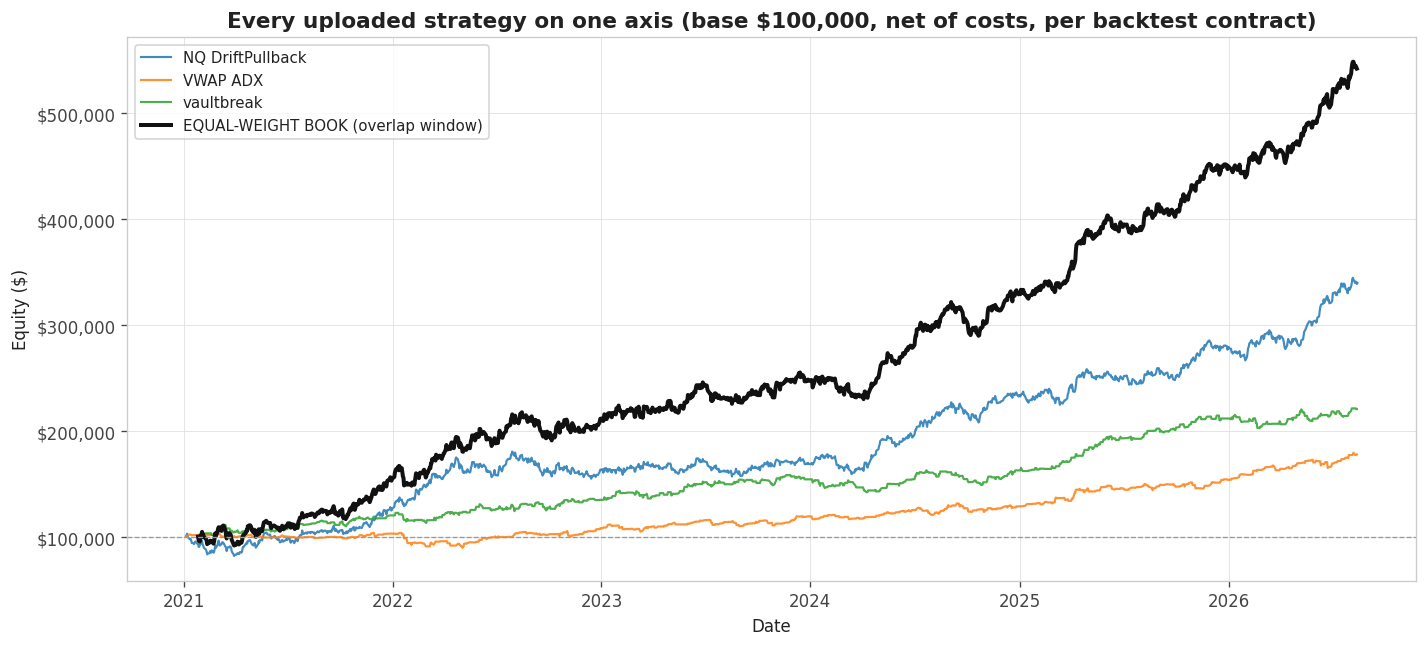

  Curve                             Total     Max DD
  ────────────────────────────────────────────────────
  NQ DriftPullback               $239,840    $25,660
  VWAP ADX                        $78,081    $14,232
  vaultbreak                     $120,834    $16,201
  EQUAL-WEIGHT BOOK              $442,049    $31,782

  The book's max DD ($31,782) vs the parts' summed DDs ($56,092) is
  diversification made visible BEFORE any statistics - Cell 20 puts a
  number on it (correlation), Cell 21 puts a price on it (p).


In [ ]:
# =========================================================
# CELL 19b (M7.5): THE STRATEGIES' EQUITY CURVES, SIDE BY SIDE
# =========================================================
# Before correlations and mixes, LOOK at the machines together: each
# strategy's full-history equity on one axis (same unit: per backtest
# contract, net of costs), plus a preview of the EQUAL-WEIGHT book on the
# overlap window - the first visual argument for why a book might be
# steadier than its parts. The proper mix race is Cells 20-21.

if len(STRATEGIES) < 2:
    print("One strategy uploaded - upload 2+ files in Cell 1 (and re-run Cell 3)")
    print("to see the side-by-side equity curves.")
else:
    EQUITY_START = 100_000.0
    fig, ax = plt.subplots(figsize=(12, 5.5))
    _stats19 = []
    for s, g in df.groupby("strategy"):
        _grid19 = pd.date_range(g["date"].min(), g["date"].max(), freq="B")
        _eq19 = (g.groupby("date")["profit_net_usd"].sum()
                 .reindex(_grid19, fill_value=0.0).cumsum() + EQUITY_START)
        ax.plot(_grid19, _eq19, linewidth=1.3, alpha=0.85, label=s)
        _stats19.append((s, _eq19.iloc[-1] - EQUITY_START,
                         float((_eq19.cummax() - _eq19).max())))

    # equal-weight book preview on the overlap window (1x each strategy)
    _spans19 = df.groupby("strategy")["date"].agg(["min", "max"])
    _olo19, _ohi19 = _spans19["min"].max(), _spans19["max"].min()
    if _olo19 <= _ohi19:
        _bg19 = pd.date_range(_olo19, _ohi19, freq="B")
        _bdf19 = df[(df["date"] >= _olo19) & (df["date"] <= _ohi19)]
        _beq19 = (_bdf19.groupby("date")["profit_net_usd"].sum()
                  .reindex(_bg19, fill_value=0.0).cumsum() + EQUITY_START)
        ax.plot(_bg19, _beq19, linewidth=2.4, color="#111111",
                label="EQUAL-WEIGHT BOOK (overlap window)")
        _stats19.append(("EQUAL-WEIGHT BOOK", _beq19.iloc[-1] - EQUITY_START,
                         float((_beq19.cummax() - _beq19).max())))

    ax.axhline(EQUITY_START, color="#999999", linewidth=0.8, linestyle="--")
    ax.set_title(f"Every uploaded strategy on one axis "
                 f"(base ${EQUITY_START:,.0f}, net of costs, per backtest contract)")
    ax.set_xlabel("Date"); ax.set_ylabel("Equity ($)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.legend(loc="upper left", fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"  {'Curve':<26} {'Total':>12} {'Max DD':>10}")
    print("  " + "─" * 52)
    for _n19, _t19, _d19 in _stats19:
        print(f"  {_n19:<26} {'$' + format(_t19, ',.0f'):>12} "
              f"{'$' + format(_d19, ',.0f'):>10}")
    _sum_dd = sum(d for n, t, d in _stats19 if "BOOK" not in n)
    _book_dd = next((d for n, t, d in _stats19 if "BOOK" in n), None)
    if _book_dd is not None:
        print(f"\n  The book's max DD (${_book_dd:,.0f}) vs the parts' summed DDs "
              f"(${_sum_dd:,.0f}) is")
        print(f"  diversification made visible BEFORE any statistics - Cell 20 puts a")
        print(f"  number on it (correlation), Cell 21 puts a price on it (p).")

════════════════════════════════════════════════════════════════════════
  DAILY STATISTICS on the overlap window (2021-01-26 → 2026-08-13, 1448 weekdays)
════════════════════════════════════════════════════════════════════════
  Strategy                      mu/day    sd/day  Sharpe/day
  ──────────────────────────────────────────────────────────
  NQ DriftPullback                $169    $1,918      0.0883
  VWAP ADX                         $53      $682      0.0770
  vaultbreak                       $83      $986      0.0846

  mu = average daily P&L (the drift toward the target).
  sd = how violently the daily number swings (what hits the floor).
  Sharpe = drift per unit of wobble - the one you cannot buy with size.


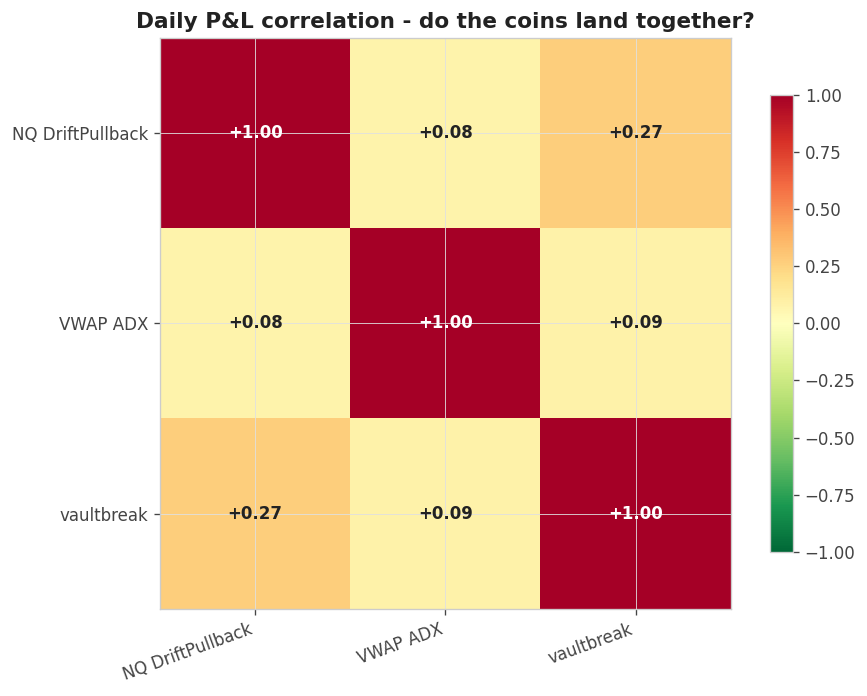

  Highest pairwise correlation: +0.27 - genuinely different
  return streams. This is where a portfolio can earn its keep:
  one strategy's bad day is not automatically the others' bad day.
  Same instrument + same direction puts a floor under correlation -
  negative values (one pays when the other bleeds) are the prize,
  and also the most regime-fragile thing you can estimate.


In [ ]:
# =========================================================
# CELL 20 (M7.5): THE PORTFOLIO QUESTION - STATISTICS & CORRELATIONS
# =========================================================
# One strategy is a coin with an edge. Several strategies are several coins -
# and the question that decides everything is whether they land together.
# Daily statistics are computed on the OVERLAP window (all strategies live),
# because a "portfolio" that is really one strategy alone is not a portfolio.

if len(STRATEGIES) < 2:
    print("One strategy uploaded - upload 2+ files in Cell 1 to unlock the")
    print("portfolio section (Cells 20-21). Cells 22-23 work either way.")
else:
    _spans = df.groupby("strategy")["date"].agg(["min", "max"])
    _olo, _ohi = _spans["min"].max(), _spans["max"].min()
    if _olo > _ohi:
        raise RuntimeError("The uploaded strategies' date ranges do not overlap - "
                           "portfolio statistics need a common window.")
    df_ov = df[(df["date"] >= _olo) & (df["date"] <= _ohi)].copy()
    _ogrid = pd.date_range(_olo, _ohi, freq="B")
    daily_mat = (df_ov.pivot_table(index="date", columns="strategy",
                                   values="profit_net_usd", aggfunc="sum")
                 .reindex(_ogrid).fillna(0.0))[sorted(STRATEGIES)]
    _mu = daily_mat.mean(); _sd = daily_mat.std()

    print("═" * 72)
    print(f"  DAILY STATISTICS on the overlap window "
          f"({_olo.date()} → {_ohi.date()}, {len(_ogrid)} weekdays)")
    print("═" * 72)
    print(f"  {'Strategy':<26} {'mu/day':>9} {'sd/day':>9} {'Sharpe/day':>11}")
    print("  " + "─" * 58)
    for s in daily_mat.columns:
        print(f"  {s:<26} {'$' + format(_mu[s], ',.0f'):>9} "
              f"{'$' + format(_sd[s], ',.0f'):>9} "
              f"{(_mu[s] / _sd[s] if _sd[s] > 0 else float('nan')):>11.4f}")
    print(f"\n  mu = average daily P&L (the drift toward the target).")
    print(f"  sd = how violently the daily number swings (what hits the floor).")
    print(f"  Sharpe = drift per unit of wobble - the one you cannot buy with size.")

    _corr = daily_mat.corr()
    fig, ax = plt.subplots(figsize=(1.6 * len(_corr) + 3, 1.3 * len(_corr) + 2))
    im = ax.imshow(_corr.to_numpy(), vmin=-1, vmax=1, cmap="RdYlGn_r")
    ax.set_xticks(range(len(_corr))); ax.set_xticklabels(_corr.columns, rotation=20, ha="right")
    ax.set_yticks(range(len(_corr))); ax.set_yticklabels(_corr.columns)
    for i in range(len(_corr)):
        for j in range(len(_corr)):
            ax.text(j, i, f"{_corr.iloc[i, j]:+.2f}", ha="center", va="center",
                    fontweight="bold",
                    color="white" if abs(_corr.iloc[i, j]) > 0.6 else "#222222")
    ax.set_title("Daily P&L correlation - do the coins land together?")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout(); plt.show()

    _offdiag = _corr.to_numpy()[np.triu_indices(len(_corr), 1)]
    _mx = float(_offdiag.max()) if len(_offdiag) else float("nan")
    if len(_offdiag):
        if _mx < 0.30:
            print(f"  Highest pairwise correlation: {_mx:+.2f} - genuinely different")
            print(f"  return streams. This is where a portfolio can earn its keep:")
            print(f"  one strategy's bad day is not automatically the others' bad day.")
        elif _mx < 0.60:
            print(f"  Highest pairwise correlation: {_mx:+.2f} - partial overlap.")
            print(f"  Diversification helps, less than the strategy count suggests.")
        else:
            print(f"  Highest pairwise correlation: {_mx:+.2f} - these largely rise and")
            print(f"  fall together; a 'portfolio' of them is mostly one bet at size.")
        print(f"  Same instrument + same direction puts a floor under correlation -")
        print(f"  negative values (one pays when the other bleeds) are the prize,")
        print(f"  and also the most regime-fragile thing you can estimate.")


════════════════════════════════════════════════════════════════════════════════════════
  MIX SWEEP - each candidate at its own recommended TOTAL size (3,000 sims/point, MAE-checked)
  Window: OVERLAP dates only, so the race is fair. Solo sizes here answer
  'this window'; the size you TRADE a solo at stays the Cell 12 playbook size.
════════════════════════════════════════════════════════════════════════════════════════
  Book (share of total per strategy)          Size*  p at Size*   TiedZone  19 Size*
  ────────────────────────────────────────────────────────────────────────────────────
  solo NQ DriftPullback [1/0/0]                   4       38.6%       4-20          
  solo VWAP ADX [0/1/0]                          15       30.3%      15-30          
  solo vaultbreak [0/0/1]                        20       44.8%      20-20          
  EQUAL WEIGHT [0.333333/0.333333/0.333333]       8       42.5%       8-30          
  mix 0.2/0.4/0.4 [0.2/0.4/0.4]                  10       43.3

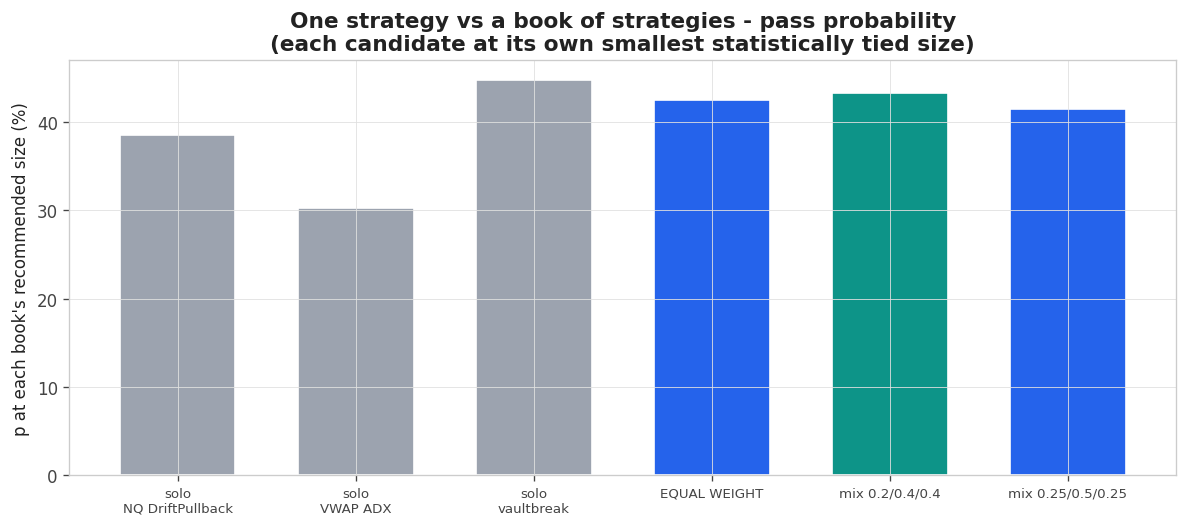


  >>> Statistically TIED: best book 43.3% vs best solo 44.8%. For the EVAL alone, take the simpler single
      strategy - but hold that thought for the funded phase below,
      where steadier daily P&L is worth far more than it is here. <<<


In [ ]:
# =========================================================
# CELL 21 (M7.6): MIX SWEEP - DOES A PORTFOLIO PASS BETTER?
# =========================================================
# The same engine, now fed a WEIGHTED BOOK: within each drawn day, every
# strategy's trades run in their real timestamp order, each scaled by its mix
# weight. Candidates: each solo, equal weight, and the best few weight combos
# by daily Sharpe. Each candidate is sized by the class's rule - the SMALLEST
# size statistically tied (two-proportion z-test) with its own peak - and the
# best portfolio races the best single strategy with the same honesty guard.
# NOTE: everything here runs on the OVERLAP window (common dates), so the
# race is fair; solo sizes can differ from Cell 19's full-history sizes,
# and the table says so explicitly. The playbook size you TRADE for a solo
# remains Cell 12/17b's.

if len(STRATEGIES) >= 2:
    MIX_SIMS      = 3_000
    MIX_SIZE_GRID = [3, 4, 5, 6, 8, 10, 12, 15, 18, 20, 25, 30]  # TOTAL MNQ

    _sord = list(daily_mat.columns)
    _sidx = {s: i for i, s in enumerate(_sord)}
    _src21 = df_ov.sort_values("datetime")
    MIX_BAG = []
    for _d in _ogrid:
        _m = _src21["date"] == _d
        MIX_BAG.append((
            _src21.loc[_m, "strategy"].map(_sidx).to_numpy(dtype=int),
            _src21.loc[_m, "profit_net_usd"].to_numpy(dtype=float),
            (_src21.loc[_m, "mae_usd"].to_numpy(dtype=float) if _USE_MAE
             else _src21.loc[_m, "profit_net_usd"].clip(upper=0).abs().to_numpy())))

    def run_mix(u_vec, total_mnq, n_sims, rng):
        """u_vec sums to 1 (share of the book per strategy)."""
        u = np.asarray(u_vec, float)
        a = ACCOUNT
        passed = 0
        for _ in range(n_sims):
            bal = a["start_balance"]; hwm = bal
            floor = bal - a["max_drawdown"]
            lock = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
            td = 0; out = None
            deadline = a["max_trading_days"] or HORIZON_DAYS
            for day in range(deadline):
                si, pnl, mae = MIX_BAG[rng.integers(len(MIX_BAG))]
                uw = u[si] * total_mnq / _BT_MNQ if len(si) else None
                if len(si) and np.any(uw != 0):
                    td += 1
                for j in range(len(pnl)):
                    if uw[j] == 0:
                        continue
                    if _USE_MAE and (bal - mae[j] * uw[j]) <= floor:
                        out = "dd"; break
                    bal += pnl[j] * uw[j]
                    if a["dd_type"] == "intraday_trail":
                        hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                        if lock is not None: floor = min(floor, lock)
                    if bal <= floor:
                        out = "dd"; break
                    if (bal - a["start_balance"] >= a["profit_target"]
                            and td >= a["min_trading_days"]):
                        out = "pass"; break
                if out:
                    break
                if a["dd_type"] == "eod_trail":
                    hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                    if lock is not None: floor = min(floor, lock)
            passed += out == "pass"
        return passed / n_sims

    def _dsharpe(u):
        p = daily_mat.to_numpy() @ np.asarray(u, float)
        return p.mean() / p.std() if p.std() > 0 else -np.inf

    def _is_tied21(d, pk, n=MIX_SIMS):
        if d is pk:
            return True
        se = np.sqrt(pk["p"] * (1 - pk["p"]) / n + d["p"] * (1 - d["p"]) / n)
        return (pk["p"] - d["p"]) / max(se, 1e-9) < 1.96

    K = len(_sord)
    cand = {}
    for i, s in enumerate(_sord):
        e = np.zeros(K); e[i] = 1.0
        cand[f"solo {s}"] = e
    cand["EQUAL WEIGHT"] = np.ones(K) / K
    import itertools
    _lat = [np.array(g, float) for g in itertools.product([0, 0.5, 1.0], repeat=K)
            if max(g) > 0 and sum(1 for x in g if x > 0) >= 2]
    _lat = [u / u.sum() for u in _lat]
    _lat.sort(key=_dsharpe, reverse=True)
    for u in _lat[:3]:
        key = "mix " + "/".join(f"{x:g}" for x in u)
        if not any(np.allclose(u, v) for v in cand.values()):
            cand[key] = u

    # Cell 19's full-history sizes, if available, for the solo reference column
    _r19 = None
    for _nm in ("results19", "rows19"):
        if _nm in dir():
            _r19 = {r["strategy"] if "strategy" in r else r.get("name", ""): r
                    for r in eval(_nm)}
            break

    print("═" * 88)
    print(f"  MIX SWEEP - each candidate at its own recommended TOTAL size "
          f"({MIX_SIMS:,} sims/point, {'MAE-checked' if _USE_MAE else 'close-checked'})")
    print(f"  Window: OVERLAP dates only, so the race is fair. Solo sizes here answer")
    print(f"  'this window'; the size you TRADE a solo at stays the Cell 12 playbook size.")
    print("═" * 88)
    print(f"  {'Book (share of total per strategy)':<42} {'Size*':>6} "
          f"{'p at Size*':>11} {'TiedZone':>10} {'19 Size*':>9}")
    print("  " + "─" * 84)
    results21 = []
    for name, u in cand.items():
        _msw = []
        for s_ in MIX_SIZE_GRID:
            if s_ > ACCOUNT["max_contracts_mnq"]:
                continue
            p = run_mix(u, s_, MIX_SIMS, np.random.default_rng(SEED + 900))
            lo, hi = wilson_ci(p, MIX_SIMS)
            _msw.append(dict(mnq=s_, p=p, lo=lo, hi=hi))
        _pk_m = max(_msw, key=lambda d: d["p"])
        _tied_m = [d for d in _msw if _is_tied21(d, _pk_m)]
        _rec = min(_tied_m, key=lambda d: d["mnq"])       # smallest tied size
        _zone_m = (min(d["mnq"] for d in _tied_m), max(d["mnq"] for d in _tied_m))
        _ref19 = ""
        if name.startswith("solo ") and _r19:
            _r = _r19.get(name.replace("solo ", ""))
            if _r and "mnq" in _r:
                _ref19 = str(_r["mnq"])
        lbl = f"{name} [{'/'.join(f'{x:g}' for x in u)}]"
        print(f"  {lbl:<42} {_rec['mnq']:>6} {_rec['p']:>11.1%} "
              f"{str(_zone_m[0]) + '-' + str(_zone_m[1]):>10} {_ref19:>9}")
        results21.append({"name": name, "u": u, "mnq": _rec["mnq"], "p": _rec["p"],
                          "lo": _rec["lo"], "hi": _rec["hi"],
                          "zone": _zone_m, "solo": name.startswith("solo")})
    print(f"\n  Size* = smallest TOTAL size statistically tied (z-test) with each")
    print(f"  book's own peak. '19 Size*' = the same strategy's full-history size")
    print(f"  from Cell 19: where they differ, the overlap window is the reason,")
    print(f"  not the method.")

    _best_solo = max((r for r in results21 if r["solo"]), key=lambda r: r["p"])
    _best_port = max((r for r in results21 if not r["solo"]), key=lambda r: r["p"])
    _lo_s, _hi_s = _best_solo["lo"], _best_solo["hi"]
    _lo_p, _hi_p = _best_port["lo"], _best_port["hi"]

    fig, ax = plt.subplots(figsize=(10, 4.5))
    _names = [r["name"] for r in results21]
    _ps = [r["p"] * 100 for r in results21]
    _cols = ["#9ca3af" if r["solo"] else "#2563eb" for r in results21]
    _cols[_names.index(_best_port["name"])] = "#0d9488"
    ax.bar(range(len(results21)), _ps, color=_cols, edgecolor="white", width=0.65)
    ax.set_xticks(range(len(results21)))
    ax.set_xticklabels([r["name"].replace("solo ", "solo\n") for r in results21],
                       fontsize=8)
    ax.set_ylabel("p at each book's recommended size (%)")
    ax.set_title("One strategy vs a book of strategies - pass probability\n"
                 "(each candidate at its own smallest statistically tied size)")
    plt.tight_layout(); plt.show()

    if _lo_p > _hi_s:
        print(f"\n  >>> The portfolio WINS: {_best_port['name']} "
              f"({_best_port['p']:.1%}) beats the best single strategy "
              f"({_best_solo['name']}, {_best_solo['p']:.1%}) outside the CIs. <<<")
        print(f"      Low correlation turned several ordinary coins into one better coin.")
    elif _hi_p < _lo_s:
        print(f"\n  >>> The single strategy wins here - the book's extra legs added")
        print(f"      more floor risk than diversification removed. <<<")
    else:
        print(f"\n  >>> Statistically TIED: best book {_best_port['p']:.1%} vs best solo "
              f"{_best_solo['p']:.1%}. For the EVAL alone, take the simpler single")
        print(f"      strategy - but hold that thought for the funded phase below,")
        print(f"      where steadier daily P&L is worth far more than it is here. <<<")

══════════════════════════════════════════════════════════════════════════════
  FINE SWEEP - mix 0.2/0.4/0.4  [0.2/0.4/0.4]  (3,000 sims/point)
══════════════════════════════════════════════════════════════════════════════
   TotMNQ        p            95% CI
  ──────────────────────────────────────
        8    36.7%  [35.0% - 38.5%]
        9    40.8%  [39.0% - 42.5%]
       10    42.4%  [40.6% - 44.1%]
       11    43.8%  [42.0% - 45.6%]
       12    43.7%  [41.9% - 45.5%]
       13    43.1%  [41.4% - 44.9%]
       14    42.8%  [41.0% - 44.6%]
       15    42.1%  [40.3% - 43.8%]
       16    42.6%  [40.9% - 44.4%]
       17    41.8%  [40.0% - 43.5%]
       18    41.2%  [39.5% - 43.0%]
       19    41.6%  [39.9% - 43.4%]
       20    41.8%  [40.0% - 43.6%]
       21    41.0%  [39.2% - 42.7%]
       22    41.4%  [39.6% - 43.1%]
       23    41.5%  [39.7% - 43.3%]
       24    42.0%  [40.2% - 43.7%]
       25    41.8%  [40.0% - 43.5%]
       26    41.7%  [39.9% - 43.4%]
       27    4

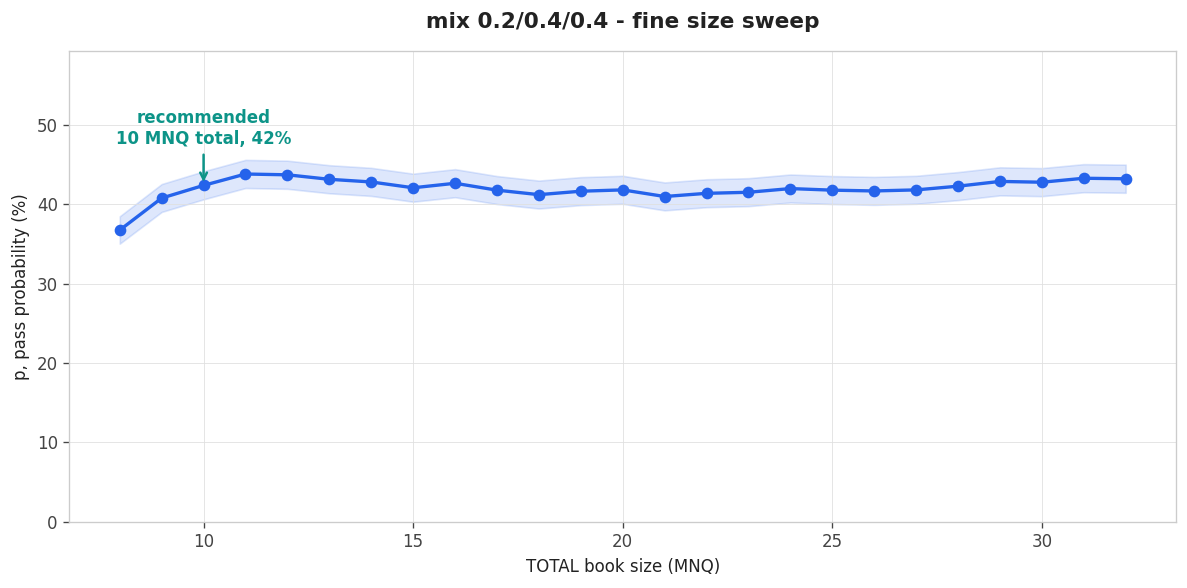


  RECOMMENDED BOOK: 10 MNQ total at p = 42.4% (tied zone 10-32 MNQ)
  Strategy                      Exact   Ticket
  ──────────────────────────────────────────────
  NQ DriftPullback                2.0       2m
  VWAP ADX                        4.0       4m
  vaultbreak                      4.0       4m

══════════════════════════════════════════════════════════════════════════════
  ONE STRATEGY OR THE BOOK?
══════════════════════════════════════════════════════════════════════════════
  Best single strategy : solo vaultbreak              p = 44.8%  [43.0% - 46.6%]  at 20 MNQ
  The book (fine-swept): mix 0.2/0.4/0.4              p = 42.4%  [40.6% - 44.1%]  at 10 MNQ

  >>> Statistically TIED. For the EVAL, simple wins on execution
      grounds: one strategy is one thing to run correctly. But hold
      the book's ticket - the funded phase (next section) rewards
      steady daily P&L far more than the eval does, and that is
      where the diversification case gets its real hearing.

In [ ]:
# =========================================================
# CELL 21b (M7.6): THE BOOK'S FINE SWEEP - AND THE FINAL VERDICT VS ONE STRATEGY
# =========================================================
# Cell 21 raced the candidates at a coarse grid. This cell takes the best
# MULTI-STRATEGY book (or set BOOK_CHOICE to any name from the Cell 21
# table), gives it what Cell 12 gave one strategy - a finer sweep with
# confidence bands and a tied zone - prints the order ticket in whole
# micros, and then answers the section's question head on: does the book
# beat the best single strategy, or does simple win?

BOOK_CHOICE = None          # e.g. "EQUAL WEIGHT"; None = best multi-strategy book
FINE_SIMS   = MIX_SIMS

if len(STRATEGIES) >= 2:
    if BOOK_CHOICE is not None:
        _chosen = next(r for r in results21 if r["name"] == BOOK_CHOICE)
    else:
        _chosen = _best_port          # the best MULTI-STRATEGY book, always
    _cu = np.asarray(_chosen["u"], float)

    # finer grid: the book's tied zone plus one step either side
    _z0, _z1 = _chosen["zone"]
    _fine = sorted({max(1, _z0 - 2), _z0, max(1, (_z0 + _z1) // 2), _z1, _z1 + 2}
                   | {s for s in range(max(1, _z0 - 2), _z1 + 3)
                      if s <= ACCOUNT["max_contracts_mnq"]})

    print("═" * 78)
    print(f"  FINE SWEEP - {_chosen['name']}  "
          f"[{'/'.join(f'{x:g}' for x in _cu)}]  ({FINE_SIMS:,} sims/point)")
    print("═" * 78)
    print(f"  {'TotMNQ':>7} {'p':>8} {'95% CI':>17}")
    print("  " + "─" * 38)
    _fsw = []
    for s_ in _fine:
        p = run_mix(_cu, s_, FINE_SIMS, np.random.default_rng(SEED + 910))
        lo, hi = wilson_ci(p, FINE_SIMS)
        _fsw.append(dict(mnq=s_, p=p, lo=lo, hi=hi))
        print(f"  {s_:>7} {p:>8.1%}  [{lo:>5.1%} - {hi:>5.1%}]")
        _pk_f = max(_fsw, key=lambda d: d["p"])
    def _is_tied(d, pk, n, z_crit=1.96):
        se = ((d["p"] * (1 - d["p"]) + pk["p"] * (1 - pk["p"])) / n) ** 0.5
        return (pk["p"] - d["p"]) <= z_crit * se if se > 0 else True
    _tied_f = [d for d in _fsw if _is_tied(d, _pk_f, FINE_SIMS)]
    _recf = min(_tied_f, key=lambda d: d["mnq"])
    _zf = (min(d["mnq"] for d in _tied_f), max(d["mnq"] for d in _tied_f))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot([d["mnq"] for d in _fsw], [d["p"] * 100 for d in _fsw], "-o",
            color="#2563eb", linewidth=2)
    ax.fill_between([d["mnq"] for d in _fsw], [d["lo"] * 100 for d in _fsw],
                    [d["hi"] * 100 for d in _fsw], alpha=0.15, color="#2563eb")
    _topf = max(d["hi"] for d in _fsw) * 100
    ax.set_ylim(0, _topf * 1.30)
    ax.annotate(f"recommended\n{_recf['mnq']} MNQ total, {_recf['p']:.0%}",
                xy=(_recf["mnq"], _recf["p"] * 100),
                xytext=(_recf["mnq"], _topf * 1.14), ha="center", va="top",
                fontweight="bold", color="#0d9488",
                arrowprops=dict(arrowstyle="->", color="#0d9488", lw=1.5))
    ax.set_xlabel("TOTAL book size (MNQ)")
    ax.set_ylabel("p, pass probability (%)")
    ax.set_title(f"{_chosen['name']} - fine size sweep", pad=14)
    plt.tight_layout(); plt.show()

    # ── the order ticket: legs in whole micros ───────────
    CHOSEN_BOOK = {"name": _chosen["name"], "u": _cu, "total_mnq": _recf["mnq"],
                   "p": _recf["p"], "lo": _recf["lo"], "hi": _recf["hi"],
                   "zone": _zf}
    _legs_raw = _cu * _recf["mnq"]
    _legs_int = np.maximum(np.round(_legs_raw), 0).astype(int)
    print(f"\n  RECOMMENDED BOOK: {_recf['mnq']} MNQ total at p = {_recf['p']:.1%} "
          f"(tied zone {_zf[0]}-{_zf[1]} MNQ)")
    print(f"  {'Strategy':<26} {'Exact':>8} {'Ticket':>8}")
    print("  " + "─" * 46)
    for _s_, _r_, _i_ in zip(_sord, _legs_raw, _legs_int):
        if _r_ > 0:
            print(f"  {_s_:<26} {_r_:>8.1f} {_i_:>7d}m")
    if any((r_ > 0) and (i_ == 0) for r_, i_ in zip(_legs_raw, _legs_int)):
        print(f"\n  ⚠️  A leg rounds to ZERO micros - this book is not tradable at this")
        print(f"      total size. Move up the tied zone until every leg is >= 1 micro;")
        print(f"      whole-contract granularity is a real constraint the math must obey.")
    elif not np.allclose(_legs_raw, _legs_int):
        _dr = float(np.abs(_legs_int - _legs_raw).max())
        print(f"\n  Rounding note: ticket sizes are whole micros (largest leg rounding")
        print(f"  {_dr:.1f} contracts). Small drift from the simulated weights is")
        print(f"  unavoidable at small totals - it shrinks as the total grows.")

    # ── THE VERDICT: the book vs the best single strategy ─────────────────
    print("\n" + "═" * 78)
    print(f"  ONE STRATEGY OR THE BOOK?")
    print("═" * 78)
    print(f"  Best single strategy : {_best_solo['name']:<28} "
          f"p = {_best_solo['p']:.1%}  [{_best_solo['lo']:.1%} - {_best_solo['hi']:.1%}]"
          f"  at {_best_solo['mnq']} MNQ")
    print(f"  The book (fine-swept): {_chosen['name']:<28} "
          f"p = {_recf['p']:.1%}  [{_recf['lo']:.1%} - {_recf['hi']:.1%}]"
          f"  at {_recf['mnq']} MNQ")
    if _recf["lo"] > _best_solo["hi"]:
        print(f"\n  >>> The BOOK wins the eval: its pass probability separates from the")
        print(f"      best single strategy outside both confidence intervals. The")
        print(f"      correlation structure from Cell 20 is worth real percentage")
        print(f"      points here - trade the ticket above. <<<")
    elif _recf["hi"] < _best_solo["lo"]:
        print(f"\n  >>> The SINGLE strategy wins the eval: the book's extra legs add")
        print(f"      more floor risk than diversification removes on this data.")
        print(f"      Pass with the single strategy - the book can still earn its")
        print(f"      place later, where its steadier P&L matters more. <<<")
    else:
        print(f"\n  >>> Statistically TIED. For the EVAL, simple wins on execution")
        print(f"      grounds: one strategy is one thing to run correctly. But hold")
        print(f"      the book's ticket - the funded phase (next section) rewards")
        print(f"      steady daily P&L far more than the eval does, and that is")
        print(f"      where the diversification case gets its real hearing. <<<")

In [ ]:
# =========================================================
# CELL 21b2 (M7.5): THE DECISION - WHAT DO WE ACTUALLY TRADE?
# =========================================================
# The section's output as one computed screen: the fine-swept book against
# the best single strategy, settled with a z-test, exported as FINAL_CHOICE
# for every cell downstream. Ties go to the single strategy for the EVAL
# (one thing to execute correctly beats two), with the book's funded
# hearing explicitly reserved. Requires Cell 21b.

if len(STRATEGIES) >= 2 and "CHOSEN_BOOK" in dir():
    _pb, _nb = CHOSEN_BOOK["p"], FINE_SIMS
    _ps, _ns = _best_solo["p"], MIX_SIMS
    _se_d = np.sqrt(_pb * (1 - _pb) / _nb + _ps * (1 - _ps) / _ns)
    _z_d = (_pb - _ps) / max(_se_d, 1e-9)

    if _z_d > 1.96:
        _mode, _why = "BOOK", "separates from the best solo (z = %.1f)" % _z_d
        FINAL_CHOICE = {"mode": "book", "name": CHOSEN_BOOK["name"],
                        "u": np.asarray(CHOSEN_BOOK["u"], float),
                        "total_mnq": CHOSEN_BOOK["total_mnq"],
                        "p": _pb, "lo": CHOSEN_BOOK["lo"], "hi": CHOSEN_BOOK["hi"]}
    elif _z_d < -1.96:
        _mode, _why = "SINGLE STRATEGY", "the book adds floor risk (z = %.1f)" % _z_d
        FINAL_CHOICE = {"mode": "solo", "name": _best_solo["name"],
                        "u": np.asarray(_best_solo["u"], float),
                        "total_mnq": _best_solo["mnq"],
                        "p": _ps, "lo": _best_solo["lo"], "hi": _best_solo["hi"]}
    else:
        _mode, _why = ("SINGLE STRATEGY",
                       "statistically tied (z = %.1f) - simple wins on execution" % _z_d)
        FINAL_CHOICE = {"mode": "solo", "name": _best_solo["name"],
                        "u": np.asarray(_best_solo["u"], float),
                        "total_mnq": _best_solo["mnq"],
                        "p": _ps, "lo": _best_solo["lo"], "hi": _best_solo["hi"]}

    print("═" * 78)
    print(f"  THE DECISION")
    print("═" * 78)
    print(f"  Candidate A (book) : {CHOSEN_BOOK['name']:<26} p = {_pb:.1%} "
          f"at {CHOSEN_BOOK['total_mnq']} MNQ total")
    print(f"  Candidate B (solo) : {_best_solo['name']:<26} p = {_ps:.1%} "
          f"at {_best_solo['mnq']} MNQ")
    print(f"\n  >>> TRADE THE {_mode}: {FINAL_CHOICE['name']} at "
          f"{FINAL_CHOICE['total_mnq']} MNQ - {_why}. <<<")
    if FINAL_CHOICE["mode"] == "solo" and abs(_z_d) <= 1.96:
        print(f"      The book is not dismissed: its funded-phase hearing is Cells")
        print(f"      22-23, where steadier daily P&L is worth far more than here.")
    print(f"\n  Exported as FINAL_CHOICE: p = {FINAL_CHOICE['p']:.1%} "
          f"[{FINAL_CHOICE['lo']:.1%} - {FINAL_CHOICE['hi']:.1%}] - the next cell")
    print(f"  prices the attempts, and Cell 23 can price its funded life")
    print(f"  (set FUNDED_CHOICE to the same name).")
else:
    print("Run Cells 20-21b first - this cell settles book vs solo.")

══════════════════════════════════════════════════════════════════════════════
  THE DECISION
══════════════════════════════════════════════════════════════════════════════
  Candidate A (book) : mix 0.2/0.4/0.4            p = 42.4% at 10 MNQ total
  Candidate B (solo) : solo vaultbreak            p = 44.8% at 20 MNQ

  >>> TRADE THE SINGLE STRATEGY: solo vaultbreak at 20 MNQ - statistically tied (z = -1.9) - simple wins on execution. <<<
      The book is not dismissed: its funded-phase hearing is Cells
      22-23, where steadier daily P&L is worth far more than here.

  Exported as FINAL_CHOICE: p = 44.8% [43.0% - 46.6%] - the next cell
  prices the attempts, and Cell 23 can price its funded life
  (set FUNDED_CHOICE to the same name).


══════════════════════════════════════════════════════════════════════════
  PASSING WITHIN N ATTEMPTS - mix 0.2/0.4/0.4 at 10 MNQ total
  (p = 42.4% per attempt, from the Cell 21b fine sweep)
══════════════════════════════════════════════════════════════════════════
   Attempts  Fees paid    Naive    Correlated (ρ=0.30)
  ────────────────────────────────────────────────────────
          1       $167    42.4%                  42.4%
          2       $334    66.8%                  59.5%
          3       $501    80.9%                  68.7%
          4       $668    89.0%                  74.5%
          5       $835    93.6%                  78.5%
          6     $1,002    96.3%                  81.4%


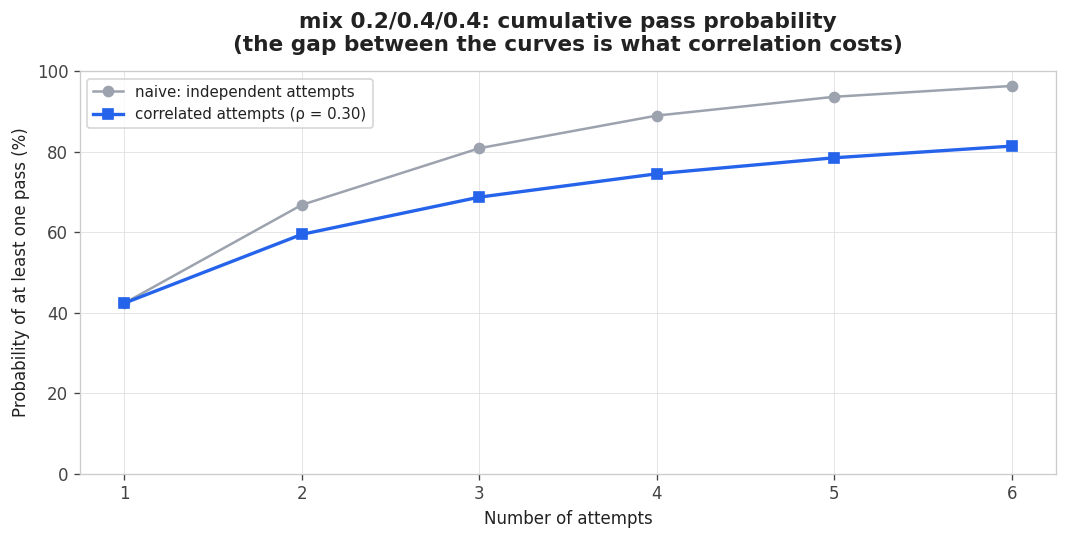


  >>> 80% confidence of a pass: 3 attempts if independent,
      6 under correlation - budget $1,002 in fees, decided BEFORE attempt one. <<<
  One attempt-level note for a BOOK: retrying with the same book is
  still correlated, but less than a single strategy retrying - the
  mix already diversifies part of the persistent fate. ρ here is a
  lever; the honest range is 0.2-0.4.
  The correlated curve flattens where the naive one keeps climbing:
  repeated failures are partly the SAME verdict repeating. After two,
  diagnose (Cell 17) - do not just rebuy.


In [ ]:
# =========================================================
# CELL 21b3 (M7.5): PASSING WITHIN N ATTEMPTS - THE BOOK
# =========================================================
# The single-strategy attempt math, re-run for the fine-swept book from
# Cell 21b. Naive curve: attempts as independent coins, 1-(1-p)^n. Honest
# curve: attempts share persistent fate (your true edge, the regime,
# measurement optimism) - a Beta mixture with correlation RHO_ATTEMPTS,
# closed form: P(all n fail) = prod_{k<n} (b+k)/(a+b+k). Same math as
# Cell 17. Requires Cell 21b (CHOSEN_BOOK).

RHO_ATTEMPTS = 0.30          # persistent share of fate between attempts
N_MAX        = 6

if len(STRATEGIES) >= 2 and "CHOSEN_BOOK" in dir():
    _p_e = CHOSEN_BOOK["p"]
    _nm_e = f"{CHOSEN_BOOK['name']} at {CHOSEN_BOOK['total_mnq']} MNQ total"
    _a_e = _p_e * (1 - RHO_ATTEMPTS) / RHO_ATTEMPTS
    _b_e = (1 - _p_e) * (1 - RHO_ATTEMPTS) / RHO_ATTEMPTS

    def _p_within(n, corr):
        if not corr:
            return 1 - (1 - _p_e) ** n
        f = 1.0
        for k in range(n):
            f *= (_b_e + k) / (_a_e + _b_e + k)
        return 1 - f

    _fee_e = ACCOUNT.get("fee", 0.0) or 0.0
    print("═" * 74)
    print(f"  PASSING WITHIN N ATTEMPTS - {_nm_e}")
    print(f"  (p = {_p_e:.1%} per attempt, from the Cell 21b fine sweep)")
    print("═" * 74)
    print(f"  {'Attempts':>9} {'Fees paid':>10} {'Naive':>8} "
          f"{'Correlated (ρ=' + format(RHO_ATTEMPTS, '.2f') + ')':>22}")
    print("  " + "─" * 56)
    _rows_e = []
    for n in range(1, N_MAX + 1):
        pn_n, pn_c = _p_within(n, False), _p_within(n, True)
        _rows_e.append((n, pn_n, pn_c))
        print(f"  {n:>9} {'$' + format(n * _fee_e, ',.0f'):>10} {pn_n:>8.1%} "
              f"{pn_c:>22.1%}")

    fig, ax = plt.subplots(figsize=(9, 4.6))
    _ns_e = [r[0] for r in _rows_e]
    ax.plot(_ns_e, [r[1] * 100 for r in _rows_e], "-o", color="#9ca3af",
            label="naive: independent attempts")
    ax.plot(_ns_e, [r[2] * 100 for r in _rows_e], "-s", color="#2563eb",
            linewidth=2, label=f"correlated attempts (ρ = {RHO_ATTEMPTS:.2f})")
    ax.set_xticks(_ns_e)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Number of attempts")
    ax.set_ylabel("Probability of at least one pass (%)")
    ax.set_title(f"{CHOSEN_BOOK['name']}: cumulative pass probability\n"
                 "(the gap between the curves is what correlation costs)", pad=12)
    ax.legend()
    plt.tight_layout(); plt.show()

    _n80_n = next((n for n, pn, _ in _rows_e if pn >= 0.80), None)
    _n80_c = next((n for n, _, pc in _rows_e if pc >= 0.80), None)
    if _n80_c is not None:
        print(f"\n  >>> 80% confidence of a pass: {_n80_n} attempts if independent,")
        print(f"      {_n80_c} under correlation - budget "
              f"${_n80_c * _fee_e:,.0f} in fees, decided BEFORE attempt one. <<<")
    else:
        print(f"\n  >>> Even {N_MAX} correlated attempts stay under 80% "
              f"({_rows_e[-1][2]:.0%}). The honest read: more attempts cannot")
        print(f"      buy what the plan lacks - improve p (size, rules, the mix,")
        print(f"      or the strategies) before spending another fee. <<<")
    print(f"  One attempt-level note for a BOOK: retrying with the same book is")
    print(f"  still correlated, but less than a single strategy retrying - the")
    print(f"  mix already diversifies part of the persistent fate. ρ here is a")
    print(f"  lever; the honest range is 0.2-0.4.")
    print(f"  The correlated curve flattens where the naive one keeps climbing:")
    print(f"  repeated failures are partly the SAME verdict repeating. After two,")
    print(f"  diagnose (Cell 17) - do not just rebuy.")
else:
    print("Run Cells 20-21b first - this cell prices the book's attempts.")

════════════════════════════════════════════════════════════════════════════
  BUFFER TEST, BOOK EDITION - mix 0.2/0.4/0.4: small until +$1,000, then 10 MNQ total
  (dynamic mode, 3,000 sims each)
════════════════════════════════════════════════════════════════════════════
                  Plan        p            95% CI   vs flat
  ────────────────────────────────────────────────────────────
           flat 10 MNQ    43.9%   [42.1% - 45.7%]  baseline
       2→10 MNQ ⚠︎legs     5.6%   [ 4.8% -  6.5%]     -38.3pp
              5→10 MNQ    30.8%   [29.1% - 32.4%]     -13.1pp
              8→10 MNQ    41.8%   [40.0% - 43.5%]      -2.1pp

  ⚠︎legs: at that stage-1 total, at least one strategy's leg rounds
  to zero micros - the simulated weights are not placeable there;
  treat that row as theory, not a ticket.


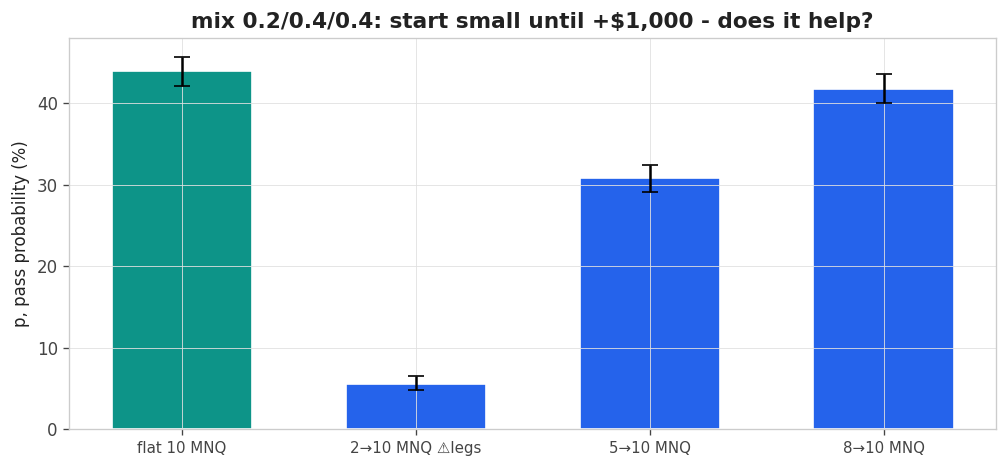


  >>> Statistically TIED (41.8% staged vs 43.9% flat).
      Take the flat plan: fewer moving parts, and a staged book
      means re-sizing EVERY leg mid-challenge - execution risk the
      simulation does not charge for. <<<

  The same idea faces a different price on the funded account (no
  deadline, death costs the ladder) - Cell 23 prices that side.


In [ ]:
# =========================================================
# CELL 21c (M7.6): THE BUFFER IDEA, BOOK EDITION
# =========================================================
# Same question as Cell 12b, asked of the CHOSEN BOOK: trade a reduced total
# size until the account is up a buffer, then switch to the recommended
# total. Size is decided at each trade's entry from current equity; same
# seeds for every plan, so differences are real. Requires Cell 21b.

BOOK_BUFFER   = 1_000.0
BOOK_FRACS    = [0.25, 0.50, 0.75]
BOOK_MODE     = "dynamic"            # "dynamic" or "ratchet"
BOOK_ST_SIMS  = MIX_SIMS

if len(STRATEGIES) >= 2 and "CHOSEN_BOOK" in dir():
    _bu = np.asarray(CHOSEN_BOOK["u"], float)
    _btot = CHOSEN_BOOK["total_mnq"]

    def run_mix_staged(total_small, total_big, n_sims, rng, mode="dynamic"):
        a = ACCOUNT
        deadline = a["max_trading_days"] or HORIZON_DAYS
        passed = 0
        for _ in range(n_sims):
            bal = a["start_balance"]; hwm = bal
            floor = bal - a["max_drawdown"]
            lock = (bal + a["dd_lock_at_profit"]) if a["dd_lock_at_profit"] is not None else None
            td = 0; big = False; out = None
            for day in range(deadline):
                si, pnl, mae = MIX_BAG[rng.integers(len(MIX_BAG))]
                if len(si):
                    td += 1
                for j in range(len(pnl)):
                    if mode == "ratchet":
                        big = big or (bal - a["start_balance"] >= BOOK_BUFFER)
                    else:
                        big = bal - a["start_balance"] >= BOOK_BUFFER
                    _tot = total_big if big else total_small
                    w_ = _bu[si[j]] * _tot / _BT_MNQ
                    if w_ == 0:
                        continue
                    if _USE_MAE and (bal - mae[j] * w_) <= floor:
                        out = "dead"; break
                    bal += pnl[j] * w_
                    if a["dd_type"] == "intraday_trail":
                        hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                        if lock is not None: floor = min(floor, lock)
                    if bal <= floor:
                        out = "dead"; break
                    if (bal - a["start_balance"] >= a["profit_target"]
                            and td >= a["min_trading_days"]):
                        out = "pass"; break
                if out:
                    break
                if a["dd_type"] == "eod_trail":
                    hwm = max(hwm, bal); floor = hwm - a["max_drawdown"]
                    if lock is not None: floor = min(floor, lock)
            passed += out == "pass"
        return passed / n_sims

    _s1_totals = sorted({max(1, int(round(fr * _btot))) for fr in BOOK_FRACS}
                        - {_btot})

    _pf = run_mix_staged(_btot, _btot, BOOK_ST_SIMS,
                         np.random.default_rng(SEED + 920), BOOK_MODE)
    _lof, _hif = wilson_ci(_pf, BOOK_ST_SIMS)

    print("═" * 76)
    print(f"  BUFFER TEST, BOOK EDITION - {CHOSEN_BOOK['name']}: small until "
          f"+${BOOK_BUFFER:,.0f}, then {_btot} MNQ total")
    print(f"  ({BOOK_MODE} mode, {BOOK_ST_SIMS:,} sims each)")
    print("═" * 76)
    if not _s1_totals:
        print(f"  The recommended total is already {_btot} MNQ - no smaller whole-MNQ")
        print(f"  stage to start from. The buffer question does not arise here.")
    else:
        print(f"  {'Plan':>20} {'p':>8} {'95% CI':>17} {'vs flat':>9}")
        print("  " + "─" * 60)
        print(f"  {'flat ' + str(_btot) + ' MNQ':>20} {_pf:>8.1%}   "
              f"[{_lof:>5.1%} - {_hif:>5.1%}]  baseline")
        _rows21c = [(f"flat {_btot} MNQ", _pf, _lof, _hif)]
        for t1 in _s1_totals:
            _zero_legs = int(np.sum((np.round(_bu * t1) == 0) & (_bu > 0)))
            p = run_mix_staged(t1, _btot, BOOK_ST_SIMS,
                               np.random.default_rng(SEED + 920), BOOK_MODE)
            lo, hi = wilson_ci(p, BOOK_ST_SIMS)
            _tag_ = " ⚠︎legs" if _zero_legs else ""
            _rows21c.append((f"{t1}→{_btot} MNQ{_tag_}", p, lo, hi))
            print(f"  {str(t1) + '→' + str(_btot) + ' MNQ' + _tag_:>20} {p:>8.1%}   "
                  f"[{lo:>5.1%} - {hi:>5.1%}]  {(p - _pf) * 100:>+8.1f}pp")
        if any("⚠︎" in r[0] for r in _rows21c):
            print(f"\n  ⚠︎legs: at that stage-1 total, at least one strategy's leg rounds")
            print(f"  to zero micros - the simulated weights are not placeable there;")
            print(f"  treat that row as theory, not a ticket.")

        fig, ax = plt.subplots(figsize=(8.5, 4))
        _ps21 = [r[1] * 100 for r in _rows21c]
        _errs = [[r[1] * 100 - r[2] * 100 for r in _rows21c],
                 [r[3] * 100 - r[1] * 100 for r in _rows21c]]
        _cols21 = ["#0d9488"] + ["#2563eb"] * (len(_rows21c) - 1)
        ax.bar(range(len(_rows21c)), _ps21, yerr=_errs, capsize=5,
               color=_cols21, edgecolor="white", width=0.6)
        ax.set_xticks(range(len(_rows21c)))
        ax.set_xticklabels([r[0] for r in _rows21c], fontsize=9)
        ax.set_ylabel("p, pass probability (%)")
        ax.set_title(f"{CHOSEN_BOOK['name']}: start small until "
                     f"+${BOOK_BUFFER:,.0f} - does it help?")
        plt.tight_layout(); plt.show()

        _stg = _rows21c[1:]
        _bst = max(_stg, key=lambda r: r[1])
        if _bst[2] > _hif:
            print(f"\n  >>> Staging HELPS the book here: {_bst[0]} beats flat outside")
            print(f"      the CIs ({_bst[1]:.1%} vs {_pf:.1%}). <<<")
        elif _bst[3] < _lof:
            print(f"\n  >>> Staging HURTS the book here, outside the CIs - under a")
            print(f"      deadline, the small days cost more than the protection buys. <<<")
        else:
            print(f"\n  >>> Statistically TIED ({_bst[1]:.1%} staged vs {_pf:.1%} flat).")
            print(f"      Take the flat plan: fewer moving parts, and a staged book")
            print(f"      means re-sizing EVERY leg mid-challenge - execution risk the")
            print(f"      simulation does not charge for. <<<")
    print(f"\n  The same idea faces a different price on the funded account (no")
    print(f"  deadline, death costs the ladder) - Cell 23 prices that side.")
else:
    print("Run Cells 20-21b first (2+ strategies) - this cell stages the CHOSEN book.")

In [ ]:
# =========================================================
# CELL 22 (MF.1): THE FUNDED PHASE - SAME MACHINE, DIFFERENT OBJECTIVE
# =========================================================
# Passing was a barrier problem with a deadline: maximise p. The funded
# account is the SAME simulation (same bag of days, same trailing floor) with
# three changes: no deadline, a payout ladder instead of one target, and the
# account's death now costs you future income, not a resit fee.
# So the number to maximise is NOT the chance of the next payout - it is the
# EXPECTED TOTAL EXTRACTED over the account's whole life. That change of
# objective changes the optimal size, usually by a lot.
# EXAMPLE numbers below - VERIFY every one on the funded rule page.

FUNDED = dict(
    safety_net=2_600.0,          # withdrawable only ABOVE this profit level
    min_withdrawal=500.0,
    qual_day_profit=250.0,       # a "qualifying day" = net profit >= this
    qual_days_per_payout=5,      # new qualifying days needed EACH cycle
    consistency_limit=0.50,      # best day < this share of cycle profit
    payout_ladder=[1500.0, 1500.0, 2000.0, 2500.0, 2500.0, 3000.0],
    dd_lock_at_profit=100.0,     # trailing floor freezes at start + this
    horizon_days=400,            # simulation guard, NOT a rule
)
print("Funded-phase spec loaded (EXAMPLE numbers - VERIFY on the firm's page).")
print(f"  Ladder: {len(FUNDED['payout_ladder'])} payouts, "
      f"${sum(FUNDED['payout_ladder']):,.0f} lifetime ceiling | "
      f"safety net +${FUNDED['safety_net']:,.0f} | no deadline.")
print("  Same bag of days, same floor - only the objective changes:")
print("  eval = P(hit target before floor, in time); funded = E[$ extracted before death].")


Funded-phase spec loaded (EXAMPLE numbers - VERIFY on the firm's page).
  Ladder: 6 payouts, $13,000 lifetime ceiling | safety net +$2,600 | no deadline.
  Same bag of days, same floor - only the objective changes:
  eval = P(hit target before floor, in time); funded = E[$ extracted before death].


════════════════════════════════════════════════════════════════════════════
  FUNDED LIFETIME SWEEP - mix 0.2/0.4/0.4  [0.2/0.4/0.4]
  objective = E[total extracted]  ($13,000 max)  (auto-selected)
════════════════════════════════════════════════════════════════════════════
   TotMNQ   E[Total]  MedTotal   P($0)  Death%
  ──────────────────────────────────────────────
        1         $0        $0  100.0%    0.5%
        2     $3,521    $3,609   12.9%   13.5%
        3     $5,298    $6,625   24.1%   36.1%
        4     $4,894    $5,683   34.7%   55.3%
        5     $4,621    $2,019   43.1%   66.5%
        6     $4,292      $564   48.2%   70.5%
        8     $3,438        $0   56.0%   76.9%
       10     $3,148        $0   58.6%   79.0%
       12     $2,830        $0   62.9%   80.9%
       15     $2,431        $0   67.6%   83.5%
       18     $2,193        $0   71.6%   85.3%
       20     $2,099        $0   73.6%   85.7%
       25     $1,895        $0   75.5%   87.1%
       30     $1,

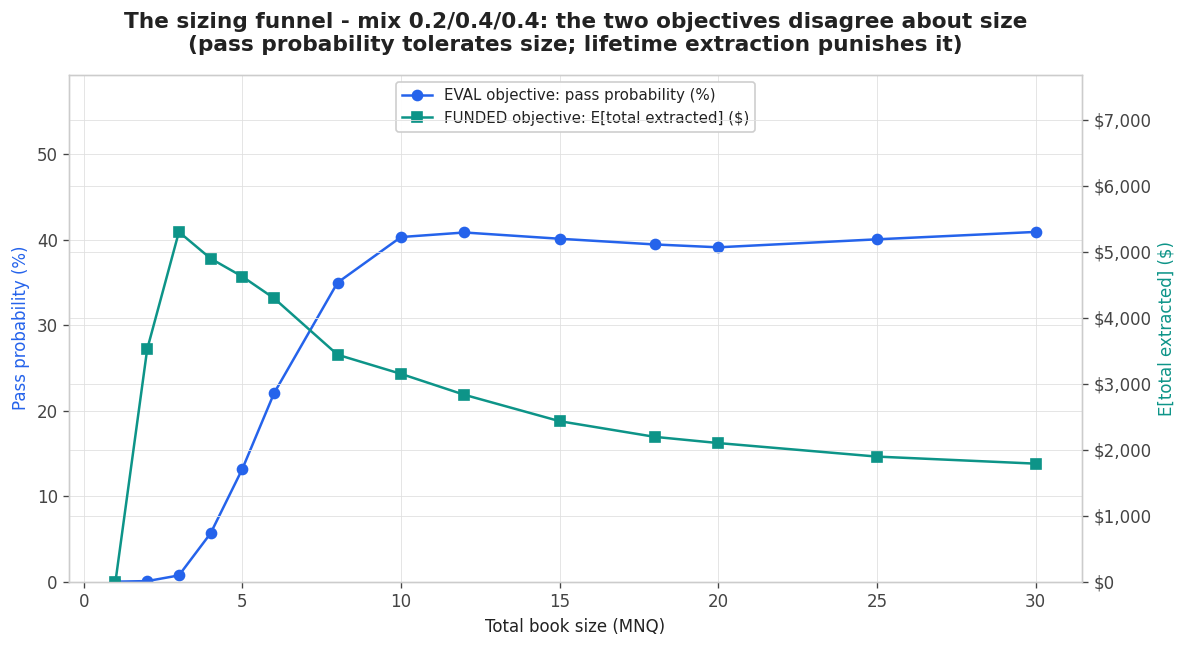


  >>> FUNDED OPTIMUM (mix 0.2/0.4/0.4): 3 MNQ total → E[Total] $5,298, median $6,625, P(paid nothing) 24% <<<
  The eval's best size here was ~30 MNQ; the funded optimum is 3 MNQ -
  a 10.0x SIZE-DOWN the day you are funded. Passing pays a fixed fee
  when it fails; the funded account loses the whole remaining ladder. Same
  machine, new price on death, smaller size. That is the funnel.
  (Inactivity rules, fees, and the firm's exact ladder are NOT modeled -
   VERIFY the spec above; the direction of the lesson survives the details.)


In [ ]:
# =========================================================
# CELL 23 (MF.2): LIFETIME PAYOUT ENGINE - SIZE FOR EXTRACTION
# =========================================================
# Walks the funded account trade by trade (MAE-checked like everything else):
# build profit, clear the payout gates, withdraw, repeat - until the ladder
# completes or the floor takes the account. Dead accounts KEEP the payouts
# already taken; that is the whole point of lifetime EV. Then the size sweep
# answers the coda's question: the size that best PASSES is rarely the size
# that best PAYS.

LIFETIME_SIMS = 1_500
FUNDED_CHOICE = None       # None = auto (CHOSEN_BOOK, else best of Cell 21).
                           # Or name any Cell 21 candidate to force it, e.g.:
                           #   "solo vaultbreak"
                           #   "solo NQ DriftPullback"
                           #   "EQUAL WEIGHT"
                           #   "mix 0.2/0.4/0.4"
                           # Matching is case-insensitive and accepts substrings.

if len(STRATEGIES) >= 2 and "results21" in dir():
    _bag23, _idx23 = MIX_BAG, True
    if FUNDED_CHOICE is not None:
        _hits = [r for r in results21
                 if FUNDED_CHOICE.lower() in r["name"].lower()]
        if len(_hits) == 1:
            _u23, _book23 = np.asarray(_hits[0]["u"], float), _hits[0]["name"]
        else:
            print(f"  ⚠️  FUNDED_CHOICE {FUNDED_CHOICE!r} matched "
                  f"{len(_hits)} candidates. Available:")
            for r in results21:
                print(f"      - {r['name']}")
            raise SystemExit
    elif "CHOSEN_BOOK" in dir():
        _u23, _book23 = np.asarray(CHOSEN_BOOK["u"], float), CHOSEN_BOOK["name"]
    elif _best_port["p"] >= _best_solo["p"]:
        _u23, _book23 = np.asarray(_best_port["u"], float), _best_port["name"]
    else:
        _u23, _book23 = np.asarray(_best_solo["u"], float), _best_solo["name"]
    _eval_best_mnq = max(results21, key=lambda r: r["p"])["mnq"]
    _eval_best_p = max(results21, key=lambda r: r["p"])["p"]
else:
    _u23, _idx23 = np.array([1.0]), False
    _book23 = SIM_STRATEGY
    _bag23 = [(np.zeros(len(p), dtype=int), p, m) for p, m in DAY_BAG]
    _eval_best_mnq, _eval_best_p = _pk["mnq"], _pk["p"]

def run_funded_lifetime(u_vec, total_mnq, n_sims, rng):
    u = np.asarray(u_vec, float)
    a, f = ACCOUNT, FUNDED
    totals, ndeaths = [], 0
    for _ in range(n_sims):
        bal = a["start_balance"]; hwm = bal
        floor = bal - a["max_drawdown"]
        lock = bal + f["dd_lock_at_profit"]
        locked = False
        cyc_start = bal; best_day = 0.0; qual = 0
        pay_i = 0; paid = 0.0
        out = None
        for day in range(f["horizon_days"]):
            si, pnl, mae = _bag23[rng.integers(len(_bag23))]
            uw = u[si] * total_mnq / _BT_MNQ if len(si) else None
            day_pnl = 0.0
            for j in range(len(pnl)):
                if uw[j] == 0:
                    continue
                if _USE_MAE and (bal - mae[j] * uw[j]) <= floor:
                    out = "dead"; break
                bal += pnl[j] * uw[j]; day_pnl += pnl[j] * uw[j]
                if bal <= floor:
                    out = "dead"; break
            if out:
                break
            if day_pnl >= f["qual_day_profit"]:
                qual += 1
            if day_pnl > best_day:
                best_day = day_pnl
            # EOD: floor ratchets until it locks
            if not locked:
                if bal > hwm: hwm = bal
                floor = hwm - a["max_drawdown"]
                if floor >= lock:
                    floor, locked = lock, True
            # payout gates
            profit = bal - a["start_balance"]
            cyc_profit = bal - cyc_start
            withdrawable = profit - f["safety_net"]
            if (qual >= f["qual_days_per_payout"]
                    and withdrawable >= f["min_withdrawal"]
                    and cyc_profit > 0
                    and best_day < f["consistency_limit"] * cyc_profit):
                amt = min(withdrawable, f["payout_ladder"][pay_i])
                paid += amt; bal -= amt
                hwm = bal
                cyc_start = bal; best_day = 0.0; qual = 0
                pay_i += 1
                if pay_i >= len(f["payout_ladder"]):
                    out = "ladder_done"; break
        totals.append(paid)
        ndeaths += out == "dead"
    totals = np.array(totals)
    return {"e_total": float(totals.mean()), "med_total": float(np.median(totals)),
            "p_zero": float((totals == 0).mean()), "death": ndeaths / n_sims}

print("═" * 76)
print(f"  FUNDED LIFETIME SWEEP - {_book23}  "
      f"[{'/'.join(f'{x:g}' for x in np.atleast_1d(_u23))}]")
print(f"  objective = E[total extracted]  (${sum(FUNDED['payout_ladder']):,.0f} max)  "
      f"{'(FUNDED_CHOICE override)' if FUNDED_CHOICE is not None else '(auto-selected)'}")
print("═" * 76)
print(f"  {'TotMNQ':>7} {'E[Total]':>10} {'MedTotal':>9} {'P($0)':>7} {'Death%':>7}")
print("  " + "─" * 46)
_f_rows = []
_f_grid = sorted(set([1, 2] + (MIX_SIZE_GRID if _idx23
                     else [m for m in SIZE_GRID_MNQ if m <= 20])))
for s_ in _f_grid:
    r = run_funded_lifetime(_u23, s_, LIFETIME_SIMS, np.random.default_rng(SEED + 1200))
    print(f"  {s_:>7} {'$' + format(r['e_total'], ',.0f'):>10} "
          f"{'$' + format(r['med_total'], ',.0f'):>9} {r['p_zero']:>7.1%} {r['death']:>7.1%}")
    _f_rows.append({"mnq": s_, **r})
_f_best = max(_f_rows, key=lambda r: r["e_total"])

# the coda chart: eval objective vs funded objective on one size axis
_ev_curve = []
for s_ in [r["mnq"] for r in _f_rows]:
    if _idx23:
        _ev_curve.append(run_mix(_u23, s_, 1_500, np.random.default_rng(SEED + 901)))
    else:
        _match = [d for d in sweep if d["mnq"] == s_]
        _ev_curve.append(_match[0]["p"] if _match else np.nan)

fig, ax1 = plt.subplots(figsize=(10, 5.5))
_x = [r["mnq"] for r in _f_rows]
_l1, = ax1.plot(_x, [p * 100 for p in _ev_curve], "-o", color="#2563eb",
                label="EVAL objective: pass probability (%)")
ax1.set_xlabel("Total book size (MNQ)")
ax1.set_ylabel("Pass probability (%)", color="#2563eb")
_top1 = max((p for p in _ev_curve if not np.isnan(p)), default=0.5) * 100
ax1.set_ylim(0, _top1 * 1.45)                       # headroom for the legend
ax2 = ax1.twinx()
_l2, = ax2.plot(_x, [r["e_total"] for r in _f_rows], "-s", color="#0d9488",
                label="FUNDED objective: E[total extracted] ($)")
ax2.set_ylabel("E[total extracted] ($)", color="#0d9488")
_top2 = max(r["e_total"] for r in _f_rows)
ax2.set_ylim(0, _top2 * 1.45)                       # same headroom on the twin
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax1.legend(handles=[_l1, _l2], loc="upper center", framealpha=0.95, fontsize=9)
ax1.set_title(f"The sizing funnel - {_book23}: the two objectives disagree about size\n"
              "(pass probability tolerates size; lifetime extraction punishes it)",
              pad=14)
plt.tight_layout(); plt.show()

_ev_best_i = int(np.nanargmax(_ev_curve))
_ev_best_mnq = _x[_ev_best_i]
print(f"\n  >>> FUNDED OPTIMUM ({_book23}): {_f_best['mnq']} MNQ total → "
      f"E[Total] ${_f_best['e_total']:,.0f}, median ${_f_best['med_total']:,.0f}, "
      f"P(paid nothing) {_f_best['p_zero']:.0%} <<<")
if _f_best["mnq"] < _ev_best_mnq:
    print(f"  The eval's best size here was ~{_ev_best_mnq} MNQ; the funded optimum is "
          f"{_f_best['mnq']} MNQ -")
    print(f"  a {_ev_best_mnq / max(_f_best['mnq'], 1):.1f}x SIZE-DOWN the day you are funded. "
          f"Passing pays a fixed fee")
    print(f"  when it fails; the funded account loses the whole remaining ladder. Same")
    print(f"  machine, new price on death, smaller size. That is the funnel.")
elif _f_best["mnq"] > _ev_best_mnq:
    print(f"  Unusual for this data: the funded optimum ({_f_best['mnq']} MNQ) is not")
    print(f"  smaller than the eval optimum (~{_ev_best_mnq} MNQ) - inspect the death%")
    print(f"  column before trusting it.")
else:
    print(f"  For this data the two objectives happen to agree on size "
          f"({_f_best['mnq']} MNQ) - verify with the death% column.")
print(f"  (Inactivity rules, fees, and the firm's exact ladder are NOT modeled -")
print(f"   VERIFY the spec above; the direction of the lesson survives the details.)")

In [ ]:
################################################################################
# PROP FIRM EVALUATION SIMULATOR
# Thank you very much for making it this far
#
# For more:
# The Insitutional Protocol: https://theinstitutionalprotocol.com/
################################################################################